# Comparative analysis of machine learning algorithms for predicting new therapeutic applications of existing drugs

# [Sankhadeep Pujaru - K2550783, School of Computer Science and Mathematics ]
# [FACULTY OF ENGINEERING,  COMPUTING AND THE ENVIRONMENT ]

## Objective

The objective of this notebook is to develop a supervised machine-learning pipeline for predicting potential drug–disease associations for drug repurposing.

Drug-related information is extracted from the DrugBank XML database and transformed into a structured dataset. Molecular features are generated from SMILES representations, while known drug–disease associations and disease-related biological information are obtained from Open Targets.

The resulting drug and disease features are integrated to construct a machine-learning dataset containing known positive drug–disease associations and candidate-negative/unlabelled drug–disease pairs. Supervised machine-learning models are subsequently trained and evaluated, and the selected model is used to rank previously unseen drug–disease combinations as potential repurposing candidates.

## Workflow

1. Extract drug information from DrugBank.
2. Clean and validate the extracted data.
3. Generate molecular descriptors from SMILES.
4. Load drug–disease association data from Open Targets.
5. Map DrugBank drug records to Open Targets drug entities using ChEMBL identifiers as the common identifier.
6. Integrate DrugBank and Open Targets data.
7. Construct positive and candidate-negative/unlabelled drug–disease pairs.
8. Generate disease-level biological features.
9. Train and evaluate machine-learning models.
10. Compare model performance and analyse the effect of progressively introducing unlabelled drug–disease pairs.


# Step 1 – Initial Inspection of the DrugBank XML File

## Objective

The objective of this step is to verify that the DrugBank XML file can be parsed correctly and that the DrugBank identifier and drug name can be extracted from an individual drug record.

Before processing the complete XML database, a single drug record is extracted as an initial validation of the XML parsing procedure.

### Expected Output

The first identified drug record containing:

* DrugBank ID
* Drug Name

This initial test is used to confirm that the XML file and namespace can be accessed correctly before performing full-dataset extraction.


In [2]:
import xml.etree.ElementTree as ET
import csv

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step1.csv"

NS = "{http://www.drugbank.ca}"

csvfile = open(OUTPUT_FILE, "w", newline="", encoding="utf-8")

writer = csv.writer(csvfile)

writer.writerow(["DrugBank_ID", "Drug_Name"])

print("CSV created successfully.")


context = ET.iterparse(XML_FILE, events=("end",))

for event, elem in context:

    if elem.tag == NS + "drug":

        drug_id = elem.findtext(NS + "drugbank-id")

        drug_name = elem.findtext(NS + "name")

        print(drug_id, drug_name)

        break


writer.writerow([drug_id, drug_name])

csvfile.close()

print("Finished.")

CSV created successfully.
DB00001 Lepirudin
Finished.


# Step 2 – Initial Full Extraction Attempt

## Objective

The objective of this step is to extend the initial XML parsing procedure from Step 1 to the complete DrugBank XML file and extract the DrugBank ID and Drug Name from all elements identified with the `<drug>` tag.  

This represents an initial full-dataset extraction attempt. The extracted record count is subsequently validated against the structure of the DrugBank XML database to determine whether the parsing procedure is correctly identifying only top-level drug records.

## Workflow

1. Import the required Python libraries.
2. Specify the location of the DrugBank XML file.
3. Create a CSV file with the required column headers.
4. Parse the XML file sequentially using `iterparse()`.
5. Identify elements with the `<drug>` tag.
6. Extract:
   - DrugBank ID
   - Drug Name
7. Write the extracted records to the CSV file.
8. Count and inspect the extracted records.

## Expected Output

A CSV file named `drugbank_step2_all_drugs.csv` containing:

- DrugBank_ID
- Drug_Name

## Validation

The number of extracted records is examined after processing. An unexpectedly large number of records would indicate that the `<drug>` tag occurs not only for top-level DrugBank records but also within nested elements of the XML structure.

Therefore, the XML hierarchy is investigated in the following step before establishing the final extraction procedure.

In [3]:
# ============================================================
# Step 2 - Initial Full Extraction Attempt
# Extract DrugBank IDs and Drug Names from all <drug> elements
# ============================================================

# Import required libraries
import xml.etree.ElementTree as ET
import csv
import pandas as pd

# ------------------------------------------------------------
# Define file paths
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step2_all_drugs.csv"

# DrugBank XML namespace
NS = "{http://www.drugbank.ca}"

# Counter for extracted <drug> elements
count = 0

print("Creating CSV file...")

# ------------------------------------------------------------
# Create CSV file
# ------------------------------------------------------------

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    # CSV header
    writer.writerow([
        "DrugBank_ID",
        "Drug_Name"
    ])

    print("Reading DrugBank XML...")

    # --------------------------------------------------------
    # Read the XML sequentially using iterparse
    # --------------------------------------------------------

    for event, elem in ET.iterparse(XML_FILE, events=("end",)):

        # Process every element with the <drug> tag.
        # At this stage, no distinction is made between
        # top-level and nested <drug> elements.
        if elem.tag == NS + "drug":

            # Extract DrugBank ID
            drug_id = elem.findtext(
                NS + "drugbank-id",
                default=""
            )

            # Extract drug name
            drug_name = elem.findtext(
                NS + "name",
                default=""
            )

            # Write the extracted information to the CSV file
            writer.writerow([
                drug_id,
                drug_name
            ])

            # Increase counter
            count += 1

            # Clear the processed element to reduce memory usage
            elem.clear()

# ------------------------------------------------------------
# Extraction summary
# ------------------------------------------------------------

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total <drug> Elements Extracted:", count)
print("CSV saved at:")
print(OUTPUT_FILE)

# ------------------------------------------------------------
# Verify the extracted CSV
# ------------------------------------------------------------

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nLast Five Records")
print(df.tail())

# ------------------------------------------------------------
# Validation note
# ------------------------------------------------------------

print("\nValidation:")
print(
    "The extracted count includes every XML element with the "
    "<drug> tag. The XML hierarchy must therefore be examined "
    "to determine whether nested <drug> elements are also present."
)

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total <drug> Elements Extracted: 3963134
CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step2_all_drugs.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID      Drug_Name
0     DB00001      Lepirudin
1     DB01022  Phylloquinone
2     DB01373        Calcium
3     DB00001      Lepirudin
4     DB00002      Cetuximab

Dataset Shape
(3963134, 2)

Last Five Records
        DrugBank_ID                     Drug_Name
3963129     DB32724                       SCY-247
3963130     DB32725              Tripentadecanoin
3963131     DB32726  Propylene glycol dicaprylate
3963132     DB32727                      RCT-1213
3963133     DB32728                 Cerous cation

Validation:
The extracted count includes every XML element with the <drug> tag. The XML hierarchy must therefore be examined to determine whether nested <drug> elements are also present.


# Step 3 – XML Structure Inspection

## Objective

Step 2 extracted 3,963,134 XML elements with the `<drug>` tag, which is substantially larger than the expected number of top-level DrugBank drug records. This indicates that `<drug>` elements may also occur within nested sections of the XML document.

The objective of this step is therefore to inspect the hierarchical structure of the DrugBank XML file and determine the location of the top-level drug records.

Understanding the XML hierarchy is necessary to distinguish the main drug records from nested `<drug>` elements and prevent unintended  nested records from being included in the final DrugBank dataset.

## Procedure

1. Parse the DrugBank XML document.
2. Identify the root element.
3. Inspect the immediate child elements of the root.
4. Determine whether the top-level drug records occur as direct children of the root.

## Expected Outcome

If the immediate children of the `<drugbank>` root are `<drug>` elements, the corrected extraction procedure can restrict processing to these top-level records rather than extracting every `<drug>` element encountered throughout the XML hierarchy.

In [4]:
# ============================================================
# Step 3 - XML Structure Inspection
# ============================================================

import xml.etree.ElementTree as ET

# ------------------------------------------------------------
# Define file path
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

# DrugBank XML namespace
NS = "{http://www.drugbank.ca}"

print("Inspecting DrugBank XML structure...")

# ------------------------------------------------------------
# Parse the XML document
# ------------------------------------------------------------

tree = ET.parse(XML_FILE)
root = tree.getroot()

# ------------------------------------------------------------
# Display the root element
# ------------------------------------------------------------

print("\nRoot Element")
print("------------")
print(root.tag)

# ------------------------------------------------------------
# Inspect immediate children of the root
# ------------------------------------------------------------

print("\nFirst 20 Immediate Child Elements of the Root")
print("---------------------------------------------")

for i, child in enumerate(list(root)[:20], start=1):
    print(f"{i}: {child.tag}")

# ------------------------------------------------------------
# Count immediate <drug> children of the root
# ------------------------------------------------------------

top_level_drugs = [
    child for child in root
    if child.tag == NS + "drug"
]

print("\nXML Structure Summary")
print("---------------------")
print("Total immediate child elements:", len(root))
print("Top-level <drug> elements:", len(top_level_drugs))

# ------------------------------------------------------------
# Interpretation
# ------------------------------------------------------------

print("\nInterpretation")
print("--------------")

if len(top_level_drugs) > 0:
    print(
        "The immediate children of the <drugbank> root contain "
        "top-level <drug> records."
    )
    print(
        "Therefore, the corrected extraction should process only "
        "top-level <drug> elements and exclude nested <drug> elements."
    )
else:
    print(
        "No top-level <drug> elements were identified. "
        "Further inspection of the XML hierarchy is required."
    )

Inspecting DrugBank XML structure...

Root Element
------------
{http://www.drugbank.ca}drugbank

First 20 Immediate Child Elements of the Root
---------------------------------------------
1: {http://www.drugbank.ca}drug
2: {http://www.drugbank.ca}drug
3: {http://www.drugbank.ca}drug
4: {http://www.drugbank.ca}drug
5: {http://www.drugbank.ca}drug
6: {http://www.drugbank.ca}drug
7: {http://www.drugbank.ca}drug
8: {http://www.drugbank.ca}drug
9: {http://www.drugbank.ca}drug
10: {http://www.drugbank.ca}drug
11: {http://www.drugbank.ca}drug
12: {http://www.drugbank.ca}drug
13: {http://www.drugbank.ca}drug
14: {http://www.drugbank.ca}drug
15: {http://www.drugbank.ca}drug
16: {http://www.drugbank.ca}drug
17: {http://www.drugbank.ca}drug
18: {http://www.drugbank.ca}drug
19: {http://www.drugbank.ca}drug
20: {http://www.drugbank.ca}drug

XML Structure Summary
---------------------
Total immediate child elements: 19856
Top-level <drug> elements: 19856

Interpretation
--------------
The immediat

# Step 4 – Corrected Extraction of Top-Level DrugBank Records

## Objective

Step 2 extracted 3,963,134 XML elements with the `<drug>` tag. The XML structure inspection performed in Step 3 established that the main DrugBank drug records occur as direct children of the root `<drugbank>` element. 

The objective of this step is to correct the extraction procedure by processing only these top-level drug records and excluding nested `<drug>` elements.

To achieve this, the XML file is processed sequentially using `iterparse()`, while the XML depth is tracked. Only `<drug>` elements occurring at depth 2, directly below the root `<drugbank>` element, are extracted.

## Workflow

1. Define the DrugBank XML file and output CSV file.
2. Parse the XML sequentially using `iterparse()`.
3. Track the depth of each XML element.
4. Identify `<drug>` elements occurring at depth 2.
5. Extract the:
   - DrugBank ID
   - Drug Name
6. Write the extracted records to a CSV file.
7. Count the number of extracted top-level drug records.
8. Load the resulting CSV file and verify its dimensions and sample records.

## Expected Output

A CSV file named `drugbank_step4_corrected.csv` containing the top-level DrugBank drug records identified in Step 3.

The expected dataset contains **19,856 rows** and two columns:

- `DrugBank_ID`
- `Drug_Name`

This corrected dataset provides the basis for extracting additional DrugBank attributes in the subsequent steps.

In [5]:
# ============================================================
# Step 4 - Corrected Extraction of Top-Level DrugBank Records
# ============================================================

# ------------------------------------------------------------
# Import Required Libraries
# ------------------------------------------------------------

import xml.etree.ElementTree as ET
import csv
import pandas as pd

# ------------------------------------------------------------
# Define File Locations
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step4_corrected.csv"

# DrugBank XML namespace
NS = "{http://www.drugbank.ca}"

# ------------------------------------------------------------
# Initialize Counter
# ------------------------------------------------------------

count = 0

print("Creating CSV file...")

# ------------------------------------------------------------
# Create CSV File
# ------------------------------------------------------------

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    # Write CSV header
    writer.writerow([
        "DrugBank_ID",
        "Drug_Name"
    ])

    print("Reading DrugBank XML...")

    # --------------------------------------------------------
    # Parse XML sequentially and track element depth
    # --------------------------------------------------------

    context = ET.iterparse(
        XML_FILE,
        events=("start", "end")
    )

    depth = 0

    for event, elem in context:

        # Entering an XML element
        if event == "start":
            depth += 1

        # Leaving an XML element
        elif event == "end":

            # Process only top-level <drug> elements.
            # The <drugbank> root is at depth 1 and its
            # direct <drug> children are at depth 2.
            if elem.tag == NS + "drug" and depth == 2:

                # Extract DrugBank ID
                drug_id = elem.findtext(
                    NS + "drugbank-id",
                    default=""
                )

                # Extract drug name
                drug_name = elem.findtext(
                    NS + "name",
                    default=""
                )

                # Write record to CSV
                writer.writerow([
                    drug_id,
                    drug_name
                ])

                count += 1

                # Release memory after processing the drug record
                elem.clear()

            depth -= 1

# ------------------------------------------------------------
# Display Extraction Summary
# ------------------------------------------------------------

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Top-Level Drug Records Extracted:", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

# ------------------------------------------------------------
# Verify the Output
# ------------------------------------------------------------

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nLast Five Records")
print(df.tail())

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")

if count == 19856:
    print(
        "The extracted record count matches the 19,856 top-level "
        "drug records identified during XML structure inspection."
    )
else:
    print(
        "The extracted record count differs from the 19,856 "
        "top-level drug records identified in Step 3. "
        "The extraction should be reviewed."
    )

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Top-Level Drug Records Extracted: 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step4_corrected.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name
0     DB00001            Lepirudin
1     DB00002            Cetuximab
2     DB00003         Dornase alfa
3     DB00004  Denileukin diftitox
4     DB00005           Etanercept

Dataset Shape
(19856, 2)

Last Five Records
      DrugBank_ID                     Drug_Name
19851     DB32724                       SCY-247
19852     DB32725              Tripentadecanoin
19853     DB32726  Propylene glycol dicaprylate
19854     DB32727                      RCT-1213
19855     DB32728                 Cerous cation

Validation
----------
The extracted record count matches the 19,856 top-level drug records identified during XML structure inspection.


# Step 5 – Extract DrugBank ID, Drug Name, and Description

## Objective

The objective of this step is to extend the corrected DrugBank extraction procedure established in Step 4 by extracting the drug description in addition to the DrugBank ID and Drug Name.

The `Description` field provides textual background information about each drug, including its biological, chemical, and therapeutic characteristics. It is retained as part of the structured DrugBank dataset to provide descriptive context for the drugs included in the study.

Only the top-level `<drug>` records identified in Steps 3 and 4 are processed. Nested `<drug>` elements are excluded by tracking the XML hierarchy during sequential parsing.

## Workflow

1. Parse the DrugBank XML file sequentially using `iterparse()`.

2. Track the XML depth during parsing.

3. Process only top-level `<drug>` records occurring at depth 2.

4. Extract:
   - DrugBank ID
   - Drug Name
   - Description

5. Store the extracted information in a CSV file.

6. Verify the number of extracted top-level drug records.

7. Examine the dimensions of the resulting dataset and assess missing values in the extracted fields.

## Expected Output

A CSV file named `drugbank_step5_description.csv` containing three columns:

- `DrugBank_ID`
- `Drug_Name`
- `Description`

The dataset is expected to contain **19,856 top-level drug records**, consistent with the corrected extraction established in Step 4.

Some DrugBank records may not contain a description. Therefore, missing values in the `Description` field are examined as part of the data-quality assessment.

The resulting dataset extends the validated DrugBank data structure and provides the basis for extracting additional drug-related attributes in subsequent steps.

In [6]:
# ============================================================
# Step 5 - Extract DrugBank ID, Drug Name, and Description
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

# ------------------------------------------------------------
# Define File Locations
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step5_description.csv"

# DrugBank XML namespace
NS = "{http://www.drugbank.ca}"

# ------------------------------------------------------------
# Initialize Counter
# ------------------------------------------------------------

count = 0

print("Creating CSV file...")

# ------------------------------------------------------------
# Create CSV File
# ------------------------------------------------------------

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    # Write CSV header
    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description"
    ])

    print("Reading DrugBank XML...")

    # --------------------------------------------------------
    # Parse XML sequentially and track element depth
    # --------------------------------------------------------

    context = ET.iterparse(
        XML_FILE,
        events=("start", "end")
    )

    depth = 0

    for event, elem in context:

        # Entering an XML element
        if event == "start":
            depth += 1

        # Leaving an XML element
        elif event == "end":

            # Process only top-level <drug> elements
            if elem.tag == NS + "drug" and depth == 2:

                # Extract DrugBank ID
                drug_id = elem.findtext(
                    NS + "drugbank-id",
                    default=""
                )

                # Extract drug name
                drug_name = elem.findtext(
                    NS + "name",
                    default=""
                )

                # Extract drug description
                description = elem.findtext(
                    NS + "description",
                    default=""
                )

                # Write record to CSV
                writer.writerow([
                    drug_id,
                    drug_name,
                    description
                ])

                count += 1

                # Release memory
                elem.clear()

            depth -= 1

# ------------------------------------------------------------
# Display Extraction Summary
# ------------------------------------------------------------

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Top-Level Drug Records Extracted:", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

# ------------------------------------------------------------
# Verify the Output
# ------------------------------------------------------------

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nLast Five Records")
print(df.tail())

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")

if count == 19856 and len(df) == 19856:
    print(
        "The dataset contains the expected 19,856 top-level "
        "DrugBank records."
    )
else:
    print(
        "The number of extracted records differs from the "
        "19,856 top-level records identified previously."
    )

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Top-Level Drug Records Extracted: 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step5_description.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  
0  Lepirudin is a recombinant hirudin formed by 6...  
1  Cetuximab is a recombinant chimeric human/mous...  
2  Dornase alfa is a biosynthetic form of human d...  
3  Denileukin diftitox is an IL2-receptor-directe...  
4  Dimeric fusion protein consisting of the extra...  

Dataset Shape
(19856, 3)

Missing Values
DrugBank_ID       0
Drug_Name         0
Description    7406
dtype: int64

Last Five Records
      DrugBank

# Step 6 – Extract DrugBank ID, Drug Name, Description, and Indication

## Objective

The objective of this step is to extend the structured DrugBank dataset by extracting the `Indication` field in addition to the DrugBank ID, Drug Name, and Description.

The indication describes the therapeutic uses or medical conditions for which a drug is indicated. This information provides important therapeutic context for the drug repurposing study and is retained as part of the structured DrugBank dataset.

Only the top-level `<drug>` records identified and validated in the previous steps are processed. Nested `<drug>` elements are excluded by tracking the XML depth during sequential parsing.

## Workflow

1. Read the DrugBank XML file using `iterparse()`.
2. Track the XML depth during parsing.
3. Process only top-level `<drug>` records at depth 2.
4. Extract:
   - DrugBank ID
   - Drug Name
   - Description
   - Indication
5. Store the extracted information in a CSV file.
6. Verify the number of extracted records.
7. Examine the dataset dimensions and missing values.

## Expected Output

A CSV file named `drugbank_step6_indication.csv` containing four columns:

- `DrugBank_ID`
- `Drug_Name`
- `Description`
- `Indication`

The dataset is expected to contain **19,856 top-level DrugBank records**, consistent with the validated extraction procedure established in the previous steps.

Missing values in the `Description` and `Indication` fields are examined but do not result in the removal of drug records at this stage.

In [7]:
# ============================================================
# Step 6 - Extract DrugBank ID, Drug Name, Description,
#          and Indication
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

# ------------------------------------------------------------
# Define File Locations
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step6_indication.csv"

# DrugBank XML namespace
NS = "{http://www.drugbank.ca}"

# ------------------------------------------------------------
# Initialize Counter
# ------------------------------------------------------------

count = 0

print("Creating CSV file...")

# ------------------------------------------------------------
# Create CSV File
# ------------------------------------------------------------

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    # Write CSV header
    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication"
    ])

    print("Reading DrugBank XML...")

    # --------------------------------------------------------
    # Parse XML sequentially and track element depth
    # --------------------------------------------------------

    context = ET.iterparse(
        XML_FILE,
        events=("start", "end")
    )

    depth = 0

    for event, elem in context:

        # Entering an XML element
        if event == "start":
            depth += 1

        # Leaving an XML element
        elif event == "end":

            # Process only top-level <drug> records
            if elem.tag == NS + "drug" and depth == 2:

                # Extract DrugBank ID
                drug_id = elem.findtext(
                    NS + "drugbank-id",
                    default=""
                )

                # Extract drug name
                drug_name = elem.findtext(
                    NS + "name",
                    default=""
                )

                # Extract description
                description = elem.findtext(
                    NS + "description",
                    default=""
                )

                # Extract indication
                indication = elem.findtext(
                    NS + "indication",
                    default=""
                )

                # Write record to CSV
                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication
                ])

                count += 1

                # Release memory
                elem.clear()

            depth -= 1

# ------------------------------------------------------------
# Display Extraction Summary
# ------------------------------------------------------------

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Top-Level Drug Records Extracted:", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

# ------------------------------------------------------------
# Verify the Output
# ------------------------------------------------------------

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nLast Five Records")
print(df.tail())

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")

if count == 19856 and len(df) == 19856:
    print(
        "The dataset contains the expected 19,856 top-level "
        "DrugBank records."
    )
else:
    print(
        "The number of extracted records differs from the "
        "19,856 top-level records identified previously."
    )

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Top-Level Drug Records Extracted: 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step6_indication.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  
0  Lepirudin is indicated for anticoagulation in ...  
1  Cetuximab is indicated for: \

# Step 7 – Extract DrugBank ID, Drug Name, Description, Indication, and Mechanism of Action

## Objective

The objective of this step is to extend the structured DrugBank dataset by extracting the `Mechanism_of_Action` field in addition to the DrugBank ID, Drug Name, Description, and Indication.

The mechanism of action describes how a drug produces its biological or therapeutic effect. This information provides biological and pharmacological context that is relevant to understanding drug activity and potential drug–disease relationships.

Only the validated top-level `<drug>` records are processed. Nested `<drug>` elements are excluded by tracking the XML depth during sequential parsing.

## Workflow

1. Read the DrugBank XML file using `iterparse()`.
2. Track the XML depth during parsing.
3. Process only top-level `<drug>` records at depth 2.
4. Extract:
   - DrugBank ID
   - Drug Name
   - Description
   - Indication
   - Mechanism of Action
5. Store the extracted information in a CSV file.
6. Verify the number of extracted records.
7. Examine the dataset dimensions and missing values.

## Expected Output

A CSV file named `drugbank_step7_mechanism.csv` containing five columns:

- `DrugBank_ID`
- `Drug_Name`
- `Description`
- `Indication`
- `Mechanism_of_Action`

The dataset is expected to contain **19,856 top-level DrugBank records**, consistent with the validated extraction procedure established in the previous steps.

Missing values in the textual fields are examined but do not result in the removal of drug records at this stage.

In [8]:
# ============================================================
# Step 7 - Extract DrugBank ID, Drug Name, Description,
#          Indication, and Mechanism of Action
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

# ------------------------------------------------------------
# Define File Locations
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step7_mechanism.csv"

# DrugBank XML namespace
NS = "{http://www.drugbank.ca}"

# ------------------------------------------------------------
# Initialize Counter
# ------------------------------------------------------------

count = 0

print("Creating CSV file...")

# ------------------------------------------------------------
# Create CSV File
# ------------------------------------------------------------

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    # Write CSV header
    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication",
        "Mechanism_of_Action"
    ])

    print("Reading DrugBank XML...")

    # --------------------------------------------------------
    # Parse XML sequentially and track element depth
    # --------------------------------------------------------

    context = ET.iterparse(
        XML_FILE,
        events=("start", "end")
    )

    depth = 0

    for event, elem in context:

        # Entering an XML element
        if event == "start":
            depth += 1

        # Leaving an XML element
        elif event == "end":

            # Process only top-level <drug> records
            if elem.tag == NS + "drug" and depth == 2:

                # Extract DrugBank ID
                drug_id = elem.findtext(
                    NS + "drugbank-id",
                    default=""
                )

                # Extract drug name
                drug_name = elem.findtext(
                    NS + "name",
                    default=""
                )

                # Extract description
                description = elem.findtext(
                    NS + "description",
                    default=""
                )

                # Extract indication
                indication = elem.findtext(
                    NS + "indication",
                    default=""
                )

                # Extract mechanism of action
                mechanism = elem.findtext(
                    NS + "mechanism-of-action",
                    default=""
                )

                # Write record to CSV
                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication,
                    mechanism
                ])

                count += 1

                # Release memory
                elem.clear()

            depth -= 1

# ------------------------------------------------------------
# Display Extraction Summary
# ------------------------------------------------------------

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Top-Level Drug Records Extracted:", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

# ------------------------------------------------------------
# Verify the Output
# ------------------------------------------------------------

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nLast Five Records")
print(df.tail())

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")

if count == 19856 and len(df) == 19856:
    print(
        "The dataset contains the expected 19,856 top-level "
        "DrugBank records."
    )
else:
    print(
        "The number of extracted records differs from the "
        "19,856 top-level records identified previously."
    )

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Top-Level Drug Records Extracted: 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step7_mechanism.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for: 

# Step 8 – Extract Drug Targets

## Objective

The objective of this step is to extend the structured DrugBank dataset by extracting drug target information in addition to the previously extracted drug attributes.

Drug targets represent proteins or other biological entities associated with the pharmacological activity of a drug. Target information provides biological context that is relevant to understanding drug action and potential drug–disease relationships.

A single drug may be associated with multiple targets. Therefore, all available target names for each drug are extracted and combined into a single semicolon-separated field.

Only the validated top-level `<drug>` records are processed.

## Workflow

1. Read the DrugBank XML file using `iterparse()`.
2. Track the XML depth during parsing.
3. Process only top-level `<drug>` records at depth 2.
4. Extract:
   - DrugBank ID
   - Drug Name
   - Description
   - Indication
   - Mechanism of Action
5. Locate the `<targets>` section for each drug.
6. Extract the name of each associated target.
7. Combine multiple target names using semicolons.
8. Store the extracted information in a CSV file.
9. Verify the dataset dimensions and examine missing values.

## Expected Output

A CSV file named `drugbank_step8_targets.csv` containing six columns:

- `DrugBank_ID`
- `Drug_Name`
- `Description`
- `Indication`
- `Mechanism_of_Action`
- `Targets`

The dataset is expected to contain **19,856 top-level DrugBank records**, consistent with the validated extraction procedure established in the previous steps.

Drugs without available target information are retained in the dataset, with the `Targets` field remaining empty.

In [9]:
# ============================================================
# Step 8 - Extract Drug Targets
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

# ------------------------------------------------------------
# Define File Locations
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step8_targets.csv"

# DrugBank XML namespace
NS = "{http://www.drugbank.ca}"

# ------------------------------------------------------------
# Initialize Counter
# ------------------------------------------------------------

count = 0

print("Creating CSV file...")

# ------------------------------------------------------------
# Create CSV File
# ------------------------------------------------------------

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    # Write CSV header
    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication",
        "Mechanism_of_Action",
        "Targets"
    ])

    print("Reading DrugBank XML...")

    # --------------------------------------------------------
    # Parse XML sequentially and track element depth
    # ------------------------------------------------------------

    context = ET.iterparse(
        XML_FILE,
        events=("start", "end")
    )

    depth = 0

    for event, elem in context:

        # Entering an XML element
        if event == "start":
            depth += 1

        # Leaving an XML element
        elif event == "end":

            # Process only top-level <drug> records
            if elem.tag == NS + "drug" and depth == 2:

                # ------------------------------------------------
                # Extract previously collected drug information
                # ------------------------------------------------

                drug_id = elem.findtext(
                    NS + "drugbank-id",
                    default=""
                )

                drug_name = elem.findtext(
                    NS + "name",
                    default=""
                )

                description = elem.findtext(
                    NS + "description",
                    default=""
                )

                indication = elem.findtext(
                    NS + "indication",
                    default=""
                )

                mechanism = elem.findtext(
                    NS + "mechanism-of-action",
                    default=""
                )

                # ------------------------------------------------
                # Extract drug target names
                # ------------------------------------------------

                target_names = []

                targets_element = elem.find(NS + "targets")

                if targets_element is not None:

                    for target in targets_element.findall(NS + "target"):

                        target_name = target.findtext(
                            NS + "name",
                            default=""
                        )

                        if target_name:
                            target_names.append(target_name)

                # Combine multiple targets into one text field
                targets_text = "; ".join(target_names)

                # ------------------------------------------------
                # Write record to CSV
                # ------------------------------------------------

                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication,
                    mechanism,
                    targets_text
                ])

                count += 1

                # Release memory
                elem.clear()

            depth -= 1

# ------------------------------------------------------------
# Display Extraction Summary
# ------------------------------------------------------------

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Top-Level Drug Records Extracted:", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

# ------------------------------------------------------------
# Verify the Output
# ------------------------------------------------------------

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nDrugs With Target Information")
print(df["Targets"].notna().sum())

print("\nDrugs Without Target Information")
print(df["Targets"].isna().sum())

print("\nLast Five Records")
print(df.tail())

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")

if count == 19856 and len(df) == 19856:
    print(
        "The dataset contains the expected 19,856 top-level "
        "DrugBank records."
    )
else:
    print(
        "The number of extracted records differs from the "
        "19,856 top-level records identified previously."
    )

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Top-Level Drug Records Extracted: 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step8_targets.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for: \r

# Step 9 – Extract Drug Pathways

## Objective

The objective of this step is to extend the structured DrugBank dataset by extracting pathway information in addition to the previously extracted drug attributes.

Drug pathways describe biological or metabolic pathways associated with a drug. This information provides additional biological context for understanding relationships between drugs and biological processes relevant to the drug repurposing study.

A single drug may be associated with multiple pathways. Therefore, all available pathway names for each drug are extracted and combined into a single semicolon-separated field.

Only the validated top-level `<drug>` records are processed.

## Workflow

1. Read the DrugBank XML file using `iterparse()`.
2. Track the XML depth during parsing.
3. Process only top-level `<drug>` records at depth 2.
4. Extract the previously collected drug information:
   - DrugBank ID
   - Drug Name
   - Description
   - Indication
   - Mechanism of Action
   - Targets
5. Locate the `<pathways>` section for each drug.
6. Extract the name of each associated pathway.
7. Combine multiple pathway names using semicolons.
8. Store the extracted information in a CSV file.
9. Verify the dataset dimensions and examine missing values.

## Expected Output

A CSV file named `drugbank_step9_pathways.csv` containing seven columns:

- `DrugBank_ID`
- `Drug_Name`
- `Description`
- `Indication`
- `Mechanism_of_Action`
- `Targets`
- `Pathways`

The dataset is expected to contain **19,856 top-level DrugBank records**, consistent with the validated extraction procedure established in the previous steps.

Drugs without available pathway information are retained in the dataset, with the `Pathways` field remaining empty.

In [10]:
# ============================================================
# Step 9 - Extract Drug Pathways
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

# ------------------------------------------------------------
# Define File Locations
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step9_pathways.csv"

# DrugBank XML namespace
NS = "{http://www.drugbank.ca}"

# ------------------------------------------------------------
# Initialize Counter
# ------------------------------------------------------------

count = 0

print("Creating CSV file...")

# ------------------------------------------------------------
# Create CSV File
# ------------------------------------------------------------

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    # Write CSV header
    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication",
        "Mechanism_of_Action",
        "Targets",
        "Pathways"
    ])

    print("Reading DrugBank XML...")

    # --------------------------------------------------------
    # Parse XML sequentially and track element depth
    # ------------------------------------------------------------

    context = ET.iterparse(
        XML_FILE,
        events=("start", "end")
    )

    depth = 0

    for event, elem in context:

        # Entering an XML element
        if event == "start":
            depth += 1

        # Leaving an XML element
        elif event == "end":

            # Process only top-level <drug> records
            if elem.tag == NS + "drug" and depth == 2:

                # ------------------------------------------------
                # Extract basic drug information
                # ------------------------------------------------

                drug_id = elem.findtext(
                    NS + "drugbank-id",
                    default=""
                )

                drug_name = elem.findtext(
                    NS + "name",
                    default=""
                )

                description = elem.findtext(
                    NS + "description",
                    default=""
                )

                indication = elem.findtext(
                    NS + "indication",
                    default=""
                )

                mechanism = elem.findtext(
                    NS + "mechanism-of-action",
                    default=""
                )

                # ------------------------------------------------
                # Extract Drug Targets
                # ------------------------------------------------

                target_names = []

                targets_element = elem.find(NS + "targets")

                if targets_element is not None:

                    for target in targets_element.findall(NS + "target"):

                        target_name = target.findtext(
                            NS + "name",
                            default=""
                        )

                        if target_name:
                            target_names.append(target_name)

                targets_text = "; ".join(target_names)

                # ------------------------------------------------
                # Extract Drug Pathways
                # ------------------------------------------------

                pathway_names = []

                pathways_element = elem.find(NS + "pathways")

                if pathways_element is not None:

                    for pathway in pathways_element.findall(NS + "pathway"):

                        pathway_name = pathway.findtext(
                            NS + "name",
                            default=""
                        )

                        if pathway_name:
                            pathway_names.append(pathway_name)

                pathways_text = "; ".join(pathway_names)

                # ------------------------------------------------
                # Write Record to CSV
                # ------------------------------------------------

                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication,
                    mechanism,
                    targets_text,
                    pathways_text
                ])

                count += 1

                # Release memory
                elem.clear()

            depth -= 1

# ------------------------------------------------------------
# Display Extraction Summary
# ------------------------------------------------------------

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Top-Level Drug Records Extracted:", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

# ------------------------------------------------------------
# Verify the Output
# ------------------------------------------------------------

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nDrugs With Pathway Information")
print(df["Pathways"].notna().sum())

print("\nDrugs Without Pathway Information")
print(df["Pathways"].isna().sum())

print("\nLast Five Records")
print(df.tail())

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")

if count == 19856 and len(df) == 19856:
    print(
        "The dataset contains the expected 19,856 top-level "
        "DrugBank records."
    )
else:
    print(
        "The number of extracted records differs from the "
        "19,856 top-level records identified previously."
    )

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Top-Level Drug Records Extracted: 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step9_pathways.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for: \

# Step 10 – Extract Drug Categories

## Objective

The objective of this step is to extend the structured DrugBank dataset by extracting drug category information in addition to the previously extracted drug attributes.

DrugBank categories provide pharmacological, chemical, biological, or therapeutic classifications associated with individual drugs. These categories provide additional contextual information that can be used to characterise drugs within the drug repurposing dataset.

A single drug may be associated with multiple categories. Therefore, all available category names for each drug are extracted and combined into a single semicolon-separated field.

Only the validated top-level `<drug>` records are processed.

## Workflow

1. Read the DrugBank XML file using `iterparse()`.
2. Track the XML depth during parsing.
3. Process only top-level `<drug>` records at depth 2.
4. Extract the previously collected drug information:
   - DrugBank ID
   - Drug Name
   - Description
   - Indication
   - Mechanism of Action
   - Targets
   - Pathways
5. Locate the `<categories>` section for each drug.
6. Extract the category name from each `<category>` record.
7. Combine multiple category names using semicolons.
8. Store the extracted information in a CSV file.
9. Verify the dataset dimensions and examine missing values.

## Expected Output

A CSV file named `drugbank_step10_categories.csv` containing eight columns:

- `DrugBank_ID`
- `Drug_Name`
- `Description`
- `Indication`
- `Mechanism_of_Action`
- `Targets`
- `Pathways`
- `Categories`

The dataset is expected to contain **19,856 top-level DrugBank records**, consistent with the validated extraction procedure established in the previous steps.

Drugs without available category information are retained in the dataset, with the `Categories` field remaining empty.

In [11]:
# ============================================================
# Step 10 - Extract Drug Categories
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

# ------------------------------------------------------------
# Define File Locations
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step10_categories.csv"

# DrugBank XML namespace
NS = "{http://www.drugbank.ca}"

# ------------------------------------------------------------
# Initialize Counter
# ------------------------------------------------------------

count = 0

print("Creating CSV file...")

# ------------------------------------------------------------
# Create CSV File
# ------------------------------------------------------------

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    # Write CSV header
    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication",
        "Mechanism_of_Action",
        "Targets",
        "Pathways",
        "Categories"
    ])

    print("Reading DrugBank XML...")

    # --------------------------------------------------------
    # Parse XML sequentially and track element depth
    # ------------------------------------------------------------

    context = ET.iterparse(
        XML_FILE,
        events=("start", "end")
    )

    depth = 0

    for event, elem in context:

        # Entering an XML element
        if event == "start":
            depth += 1

        # Leaving an XML element
        elif event == "end":

            # Process only top-level <drug> records
            if elem.tag == NS + "drug" and depth == 2:

                # ------------------------------------------------
                # Extract Basic Drug Information
                # ------------------------------------------------

                drug_id = elem.findtext(
                    NS + "drugbank-id",
                    default=""
                )

                drug_name = elem.findtext(
                    NS + "name",
                    default=""
                )

                description = elem.findtext(
                    NS + "description",
                    default=""
                )

                indication = elem.findtext(
                    NS + "indication",
                    default=""
                )

                mechanism = elem.findtext(
                    NS + "mechanism-of-action",
                    default=""
                )

                # ------------------------------------------------
                # Extract Drug Targets
                # ------------------------------------------------------------

                target_names = []

                targets_element = elem.find(NS + "targets")

                if targets_element is not None:

                    for target in targets_element.findall(NS + "target"):

                        target_name = target.findtext(
                            NS + "name",
                            default=""
                        )

                        if target_name:
                            target_names.append(target_name)

                targets_text = "; ".join(target_names)

                # ------------------------------------------------
                # Extract Drug Pathways
                # ------------------------------------------------------------

                pathway_names = []

                pathways_element = elem.find(NS + "pathways")

                if pathways_element is not None:

                    for pathway in pathways_element.findall(NS + "pathway"):

                        pathway_name = pathway.findtext(
                            NS + "name",
                            default=""
                        )

                        if pathway_name:
                            pathway_names.append(pathway_name)

                pathways_text = "; ".join(pathway_names)

                # ------------------------------------------------
                # Extract Drug Categories
                # ------------------------------------------------------------

                category_names = []

                categories_element = elem.find(NS + "categories")

                if categories_element is not None:

                    for category in categories_element.findall(NS + "category"):

                        category_name = category.findtext(
                            NS + "category",
                            default=""
                        )

                        if category_name:
                            category_names.append(category_name)

                categories_text = "; ".join(category_names)

                # ------------------------------------------------
                # Write Record to CSV
                # ------------------------------------------------------------

                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication,
                    mechanism,
                    targets_text,
                    pathways_text,
                    categories_text
                ])

                count += 1

                # Release memory
                elem.clear()

            depth -= 1

# ------------------------------------------------------------
# Display Extraction Summary
# ------------------------------------------------------------

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Top-Level Drug Records Extracted:", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

# ------------------------------------------------------------
# Verify the Output
# ------------------------------------------------------------

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nDrugs With Category Information")
print(df["Categories"].notna().sum())

print("\nDrugs Without Category Information")
print(df["Categories"].isna().sum())

print("\nLast Five Records")
print(df.tail())

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")

if count == 19856 and len(df) == 19856:
    print(
        "The dataset contains the expected 19,856 top-level "
        "DrugBank records."
    )
else:
    print(
        "The number of extracted records differs from the "
        "19,856 top-level records identified previously."
    )

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Top-Level Drug Records Extracted: 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step10_categories.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for

# Step 11 – Extract ATC Codes

## Objective

The objective of this step is to extend the DrugBank dataset by extracting the Anatomical Therapeutic Chemical (ATC) classification codes for each top-level drug record.

ATC codes provide standardized information about the therapeutic and pharmacological classification of drugs. This information may be useful in the drug repurposing workflow because drugs belonging to related ATC classes may share therapeutic properties or biological functions.

This step performs the following operations:

1. Read the DrugBank XML file.
2. Process only the 19,856 top-level `<drug>` records identified during XML structure inspection.
3. Extract:
   - DrugBank ID
   - Drug Name
   - Description
   - Indication
   - Mechanism of Action
   - Targets
   - Pathways
   - Categories
   - ATC Codes
4. Combine multiple targets, pathways, categories, and ATC codes using semicolons.
5. Save the extracted information into a CSV file.
6. Verify the resulting dataset and report missing ATC information.

## Expected Output

A CSV file named **drugbank_step11_atc.csv** containing nine columns:

- DrugBank_ID
- Drug_Name
- Description
- Indication
- Mechanism_of_Action
- Targets
- Pathways
- Categories
- ATC_Codes

The dataset should contain exactly **19,856 rows**, corresponding to the top-level DrugBank drug records identified during XML structure inspection.

In [12]:
# ============================================================
# Step 11
# Extract ATC Codes for Top-Level DrugBank Records
# ============================================================

# ------------------------------------------------------------
# Import Required Libraries
# ------------------------------------------------------------

import xml.etree.ElementTree as ET
import csv
import pandas as pd

# ------------------------------------------------------------
# Define File Locations
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step11_atc.csv"

# DrugBank XML Namespace
NS = "{http://www.drugbank.ca}"

# ------------------------------------------------------------
# Initialize Counter
# ------------------------------------------------------------

count = 0

print("Creating CSV file...")

# ------------------------------------------------------------
# Create CSV File
# ------------------------------------------------------------

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    # Write CSV Header
    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication",
        "Mechanism_of_Action",
        "Targets",
        "Pathways",
        "Categories",
        "ATC_Codes"
    ])

    print("Reading DrugBank XML...")

    # --------------------------------------------------------
    # Parse XML and Track XML Depth
    # --------------------------------------------------------

    context = ET.iterparse(
        XML_FILE,
        events=("start", "end")
    )

    depth = 0

    for event, elem in context:

        # Entering an XML element
        if event == "start":
            depth += 1

        # Leaving an XML element
        elif event == "end":

            # ------------------------------------------------
            # Process only top-level <drug> records
            # ------------------------------------------------

            if elem.tag == NS + "drug" and depth == 2:

                # --------------------------------------------
                # Basic Drug Information
                # --------------------------------------------

                drug_id = elem.findtext(
                    NS + "drugbank-id",
                    default=""
                )

                drug_name = elem.findtext(
                    NS + "name",
                    default=""
                )

                description = elem.findtext(
                    NS + "description",
                    default=""
                )

                indication = elem.findtext(
                    NS + "indication",
                    default=""
                )

                mechanism = elem.findtext(
                    NS + "mechanism-of-action",
                    default=""
                )

                # --------------------------------------------
                # Extract Targets
                # --------------------------------------------

                target_names = []

                targets_element = elem.find(NS + "targets")

                if targets_element is not None:

                    for target in targets_element.findall(
                        NS + "target"
                    ):

                        target_name = target.findtext(
                            NS + "name",
                            default=""
                        )

                        if target_name:
                            target_names.append(target_name)

                targets_text = "; ".join(target_names)

                # --------------------------------------------
                # Extract Pathways
                # --------------------------------------------

                pathway_names = []

                pathways_element = elem.find(NS + "pathways")

                if pathways_element is not None:

                    for pathway in pathways_element.findall(
                        NS + "pathway"
                    ):

                        pathway_name = pathway.findtext(
                            NS + "name",
                            default=""
                        )

                        if pathway_name:
                            pathway_names.append(pathway_name)

                pathways_text = "; ".join(pathway_names)

                # --------------------------------------------
                # Extract Categories
                # --------------------------------------------

                category_names = []

                categories_element = elem.find(NS + "categories")

                if categories_element is not None:

                    for category in categories_element.findall(
                        NS + "category"
                    ):

                        category_name = category.findtext(
                            NS + "category",
                            default=""
                        )

                        if category_name:
                            category_names.append(category_name)

                categories_text = "; ".join(category_names)

                # --------------------------------------------
                # Extract ATC Codes
                # --------------------------------------------

                atc_codes = []

                atc_element = elem.find(NS + "atc-codes")

                if atc_element is not None:

                    for atc in atc_element.findall(
                        NS + "atc-code"
                    ):

                        code = atc.get("code")

                        if code:
                            atc_codes.append(code)

                atc_text = "; ".join(atc_codes)

                # --------------------------------------------
                # Write Record to CSV
                # --------------------------------------------

                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication,
                    mechanism,
                    targets_text,
                    pathways_text,
                    categories_text,
                    atc_text
                ])

                count += 1

                # Release processed drug element from memory
                elem.clear()

            depth -= 1

# ------------------------------------------------------------
# Display Extraction Summary
# ------------------------------------------------------------

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Top-Level Drug Records Extracted:", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

# ------------------------------------------------------------
# Load CSV for Verification
# ------------------------------------------------------------

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

# ------------------------------------------------------------
# Display First Five Records
# ------------------------------------------------------------

print("\nFirst Five Records")
print(df.head())

# ------------------------------------------------------------
# Display Dataset Shape
# ------------------------------------------------------------

print("\nDataset Shape")
print(df.shape)

# ------------------------------------------------------------
# Check Missing Values
# ------------------------------------------------------------

print("\nMissing Values")
print(df.isnull().sum())

# ------------------------------------------------------------
# Check ATC Code Availability
# ------------------------------------------------------------

atc_with_data = df["ATC_Codes"].notna().sum()
atc_without_data = df["ATC_Codes"].isna().sum()

print("\nDrugs With ATC Code Information")
print(atc_with_data)

print("\nDrugs Without ATC Code Information")
print(atc_without_data)

# ------------------------------------------------------------
# Display Example Drugs With ATC Codes
# ------------------------------------------------------------

print("\nExample Drugs With ATC Codes")
print(
    df.loc[
        df["ATC_Codes"].notna(),
        ["DrugBank_ID", "Drug_Name", "ATC_Codes"]
    ].head(10)
)

# ------------------------------------------------------------
# Display Last Five Records
# ------------------------------------------------------------

print("\nLast Five Records")
print(df.tail())

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")

if len(df) == 19856:
    print(
        "The dataset contains the expected "
        "19,856 top-level DrugBank records."
    )
else:
    print(
        "WARNING: The extracted record count differs from "
        "the expected 19,856 top-level records."
    )

if df["DrugBank_ID"].nunique() == 19856:
    print("All 19,856 DrugBank IDs are unique.")
else:
    print(
        "WARNING: Number of unique DrugBank IDs:",
        df["DrugBank_ID"].nunique()
    )

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Top-Level Drug Records Extracted: 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step11_atc.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for: \r\n\

# Step 12 – Exploratory Data Assessment of the Extracted DrugBank Dataset

## Objective

The objective of this step is to examine the quality and completeness of the structured DrugBank dataset produced after the extraction of ATC codes.

The current dataset contains 19,856 top-level DrugBank drug records and the following nine attributes:

- DrugBank ID
- Drug Name
- Description
- Indication
- Mechanism of Action
- Targets
- Pathways
- Categories
- ATC Codes

Before performing further preprocessing, integration, feature engineering, or machine learning, the extracted dataset should be assessed for completeness and consistency.

This step performs the following checks:

1. Dataset dimensions
2. Column names
3. First and last records
4. Missing values
5. Percentage of missing values
6. Duplicate DrugBank IDs
7. Number of unique DrugBank IDs
8. Number of available values for each feature
9. Overall feature coverage

## Expected Outcome

The dataset should contain:

- **19,856 rows**
- **9 columns**
- **19,856 unique DrugBank IDs**
- **0 duplicate DrugBank IDs**

Missing values are expected in several DrugBank attributes because not every drug record contains information for every field.

In [13]:
# ============================================================
# Step 12
# Exploratory Data Assessment of Extracted DrugBank Dataset
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Load the Latest Validated DrugBank Dataset
# ------------------------------------------------------------

FILE_PATH = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step11_atc.csv"

print("Loading DrugBank dataset...")

df = pd.read_csv(FILE_PATH)

print("Dataset loaded successfully.")

# ------------------------------------------------------------
# 1. Dataset Shape
# ------------------------------------------------------------

print("\nDataset Shape")
print("-------------")
print(df.shape)

# ------------------------------------------------------------
# 2. Column Names
# ------------------------------------------------------------

print("\nColumn Names")
print("------------")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

# ------------------------------------------------------------
# 3. First Five Records
# ------------------------------------------------------------

print("\nFirst Five Records")
print("------------------")
print(df.head())

# ------------------------------------------------------------
# 4. Last Five Records
# ------------------------------------------------------------

print("\nLast Five Records")
print("-----------------")
print(df.tail())

# ------------------------------------------------------------
# 5. Missing Values
# ------------------------------------------------------------

print("\nMissing Values")
print("--------------")

missing_values = df.isnull().sum()

print(missing_values)

# ------------------------------------------------------------
# 6. Missing Value Percentage
# ------------------------------------------------------------

print("\nMissing Value Percentage")
print("------------------------")

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage.round(2))

# ------------------------------------------------------------
# 7. Non-Missing Values
# ------------------------------------------------------------

print("\nNon-Missing Values")
print("------------------")

non_missing_values = df.notnull().sum()

print(non_missing_values)

# ------------------------------------------------------------
# 8. Feature Coverage Percentage
# ------------------------------------------------------------

print("\nFeature Coverage Percentage")
print("---------------------------")

coverage_percentage = (
    df.notnull().sum() / len(df)
) * 100

print(coverage_percentage.round(2))

# ------------------------------------------------------------
# 9. Duplicate DrugBank IDs
# ------------------------------------------------------------

duplicate_ids = df["DrugBank_ID"].duplicated().sum()

print("\nDuplicate DrugBank IDs")
print("----------------------")
print(duplicate_ids)

# ------------------------------------------------------------
# 10. Number of Unique DrugBank IDs
# ------------------------------------------------------------

unique_drugs = df["DrugBank_ID"].nunique()

print("\nNumber of Unique DrugBank IDs")
print("-----------------------------")
print(unique_drugs)

# ------------------------------------------------------------
# 11. Empty Drug Names
# ------------------------------------------------------------

missing_drug_names = df["Drug_Name"].isnull().sum()

print("\nMissing Drug Names")
print("------------------")
print(missing_drug_names)

# ------------------------------------------------------------
# 12. Feature Availability Summary
# ------------------------------------------------------------

print("\nFeature Availability Summary")
print("----------------------------")

feature_summary = pd.DataFrame({
    "Non_Missing": df.notnull().sum(),
    "Missing": df.isnull().sum(),
    "Coverage_Percentage": (
        df.notnull().sum() / len(df) * 100
    ).round(2)
})

print(feature_summary)

# ------------------------------------------------------------
# 13. Overall Dataset Summary
# ------------------------------------------------------------

print("\nOverall Dataset Summary")
print("-----------------------")

print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("Unique DrugBank IDs:", unique_drugs)
print("Duplicate DrugBank IDs:", duplicate_ids)

# ------------------------------------------------------------
# 14. Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")

if len(df) == 19856:
    print("✓ Expected number of DrugBank records: 19,856")
else:
    print(
        "WARNING: Expected 19,856 records but found:",
        len(df)
    )

if len(df.columns) == 9:
    print("✓ Expected number of columns: 9")
else:
    print(
        "WARNING: Expected 9 columns but found:",
        len(df.columns)
    )

if unique_drugs == 19856:
    print("✓ All 19,856 DrugBank IDs are unique.")
else:
    print(
        "WARNING: Number of unique DrugBank IDs:",
        unique_drugs
    )

if duplicate_ids == 0:
    print("✓ No duplicate DrugBank IDs detected.")
else:
    print(
        "WARNING: Duplicate DrugBank IDs detected:",
        duplicate_ids
    )

if missing_drug_names == 0:
    print("✓ No missing drug names detected.")
else:
    print(
        "WARNING: Missing drug names detected:",
        missing_drug_names
    )

Loading DrugBank dataset...
Dataset loaded successfully.

Dataset Shape
-------------
(19856, 9)

Column Names
------------
1. DrugBank_ID
2. Drug_Name
3. Description
4. Indication
5. Mechanism_of_Action
6. Targets
7. Pathways
8. Categories
9. ATC_Codes

First Five Records
------------------
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for

# Understanding SMILES

## What is SMILES?

SMILES (Simplified Molecular Input Line Entry System) is a text-based notation used to represent the chemical structure of a molecule. Instead of storing a molecule as a graphical chemical diagram, SMILES encodes the molecular structure as a sequence of characters that can be easily processed by computers.

For example:

| Molecule | SMILES |
|----------|---------|
| Water | `O` |
| Ethanol | `CCO` |
| Benzene | `c1ccccc1` |
| Aspirin | `CC(=O)OC1=CC=CC=C1C(=O)O` |

Each character or symbol represents atoms, chemical bonds, branching, ring structures, and other molecular properties.

## Why is SMILES Important?

SMILES is one of the most widely used molecular representations in cheminformatics and computational drug discovery. Since machine learning algorithms cannot directly process chemical structure diagrams, SMILES provides a standardized text representation that can be used for computational analysis.

Using SMILES, researchers can generate a wide range of molecular descriptors and structural representations, including:

- Molecular weight
- Number of atoms
- Number of rings
- Hydrogen bond donors
- Hydrogen bond acceptors
- LogP (lipophilicity)
- Molecular fingerprints
- Topological descriptors

These descriptors are commonly used as input features for machine learning models in drug discovery and drug repurposing.

## Why is SMILES Relevant to This Dissertation?

The objective of this dissertation is to identify potential opportunities for drug repurposing using machine learning techniques. Although the current study focuses on extracting information from DrugBank, the SMILES representation provides an important link between the biological information stored in DrugBank and the chemical structure of each drug.

By extracting the SMILES representation, it becomes possible to generate molecular descriptors and fingerprints using cheminformatics libraries such as RDKit. These features can later be incorporated into machine learning models to improve prediction performance and enable structure-based analysis of drug similarity.

## Where is SMILES Stored in DrugBank?

Unlike fields such as Drug Name or Indication, the SMILES representation is not stored as a direct child element of each drug. Instead, it is stored within the **Calculated Properties** section of the DrugBank XML file.

The XML structure is similar to the following:

```xml
<calculated-properties>
    <property>
        <kind>SMILES</kind>
        <value>CC(=O)OC1=CC=CC=C1C(=O)O</value>
    </property>
</calculated-properties>
```

Therefore, extracting SMILES requires searching through the calculated properties of each drug and identifying the property whose `<kind>` element is equal to **SMILES**.

# Step 13 – Extract SMILES Representation

## Objective

The objective of this step is to extend the DrugBank XML parser by extracting the **SMILES (Simplified Molecular Input Line Entry System)** representation for each drug.

SMILES is a text-based representation of a molecule's chemical structure and is one of the most widely used molecular representations in cheminformatics. Unlike the descriptive information extracted in the previous steps, SMILES provides structural information about each drug molecule.

The extracted SMILES strings can later be used to generate molecular descriptors and molecular fingerprints using cheminformatics libraries such as RDKit. These numerical and structural features can subsequently be incorporated into machine learning models for drug similarity analysis and drug repurposing.

This step performs the following operations:

1. Read the DrugBank XML file.
2. Process only the top-level `<drug>` elements.
3. Extract:
   - DrugBank ID
   - Drug Name
   - Description
   - Indication
   - Mechanism of Action
   - Targets
   - Pathways
   - Categories
   - ATC Codes
   - SMILES
4. Save the extracted information into a CSV file.
5. Verify the extracted dataset using pandas.

## Expected Output

A CSV file named **drugbank_step11_smiles.csv** containing ten columns:

- DrugBank_ID
- Drug_Name
- Description
- Indication
- Mechanism_of_Action
- Targets
- Pathways
- Categories
- ATC_Codes
- SMILES

The number of rows should remain 19,856 records, corresponding to the 19,856 top-level DrugBank drug records identified during XML structure inspection.

In [15]:
# ============================================================
# Step 13
# Extract DrugBank ID, Drug Name, Description, Indication,
# Mechanism of Action, Targets, Pathways, Categories,
# ATC Codes and SMILES
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"
OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step13_smiles.csv"

NS = "{http://www.drugbank.ca}"

count = 0

print("Creating CSV file...")

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication",
        "Mechanism_of_Action",
        "Targets",
        "Pathways",
        "Categories",
        "ATC_Codes",
        "SMILES"
    ])

    print("Reading DrugBank XML...")

    context = ET.iterparse(XML_FILE, events=("start", "end"))

    depth = 0

    for event, elem in context:

        if event == "start":
            depth += 1

        elif event == "end":

            if elem.tag == NS + "drug" and depth == 2:

                # ---------------- Basic Drug Information ----------------

                drug_id = elem.findtext(NS + "drugbank-id", default="")
                drug_name = elem.findtext(NS + "name", default="")
                description = elem.findtext(NS + "description", default="")
                indication = elem.findtext(NS + "indication", default="")
                mechanism = elem.findtext(
                    NS + "mechanism-of-action",
                    default=""
                )

                # ---------------- Targets ----------------

                target_names = []

                targets_element = elem.find(NS + "targets")

                if targets_element is not None:
                    for target in targets_element.findall(NS + "target"):

                        target_name = target.findtext(
                            NS + "name",
                            default=""
                        )

                        if target_name:
                            target_names.append(target_name)

                targets_text = "; ".join(target_names)

                # ---------------- Pathways ----------------

                pathway_names = []

                pathways_element = elem.find(NS + "pathways")

                if pathways_element is not None:
                    for pathway in pathways_element.findall(NS + "pathway"):

                        pathway_name = pathway.findtext(
                            NS + "name",
                            default=""
                        )

                        if pathway_name:
                            pathway_names.append(pathway_name)

                pathways_text = "; ".join(pathway_names)

                # ---------------- Categories ----------------

                category_names = []

                categories_element = elem.find(NS + "categories")

                if categories_element is not None:
                    for category in categories_element.findall(
                        NS + "category"
                    ):

                        category_name = category.findtext(
                            NS + "category",
                            default=""
                        )

                        if category_name:
                            category_names.append(category_name)

                categories_text = "; ".join(category_names)

                # ---------------- ATC Codes ----------------

                atc_codes = []

                atc_element = elem.find(NS + "atc-codes")

                if atc_element is not None:
                    for atc in atc_element.findall(NS + "atc-code"):

                        code = atc.get("code")

                        if code:
                            atc_codes.append(code)

                atc_text = "; ".join(atc_codes)

                # ---------------- SMILES ----------------

                smiles = ""

                calculated_properties = elem.find(
                    NS + "calculated-properties"
                )

                if calculated_properties is not None:

                    for prop in calculated_properties.findall(
                        NS + "property"
                    ):

                        kind = prop.findtext(
                            NS + "kind",
                            default=""
                        )

                        if kind == "SMILES":

                            smiles = prop.findtext(
                                NS + "value",
                                default=""
                            )

                            break

                # ---------------- Write Row ----------------

                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication,
                    mechanism,
                    targets_text,
                    pathways_text,
                    categories_text,
                    atc_text,
                    smiles
                ])

                count += 1

                # Free memory after processing each top-level drug
                elem.clear()

            depth -= 1


# ============================================================
# Extraction Summary
# ============================================================

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Top-Level Drug Records Extracted:", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)


# ============================================================
# Load CSV for Verification
# ============================================================

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)


# ============================================================
# Basic Verification
# ============================================================

print("\nFirst Five Records")
print("------------------")
print(df.head())

print("\nDataset Shape")
print("-------------")
print(df.shape)

print("\nColumn Names")
print("------------")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

print("\nMissing Values")
print("--------------")
print(df.isnull().sum())


# ============================================================
# SMILES Verification
# ============================================================

smiles_available = df["SMILES"].notna().sum()
smiles_missing = df["SMILES"].isna().sum()

print("\nDrugs With SMILES Information")
print("-----------------------------")
print(smiles_available)

print("\nDrugs Without SMILES Information")
print("--------------------------------")
print(smiles_missing)

print("\nSMILES Coverage Percentage")
print("--------------------------")

smiles_coverage = (smiles_available / len(df)) * 100
print(f"{smiles_coverage:.2f}%")


# ============================================================
# Example SMILES Records
# ============================================================

print("\nExample Drugs With SMILES")
print("-------------------------")

print(
    df.loc[
        df["SMILES"].notna(),
        ["DrugBank_ID", "Drug_Name", "SMILES"]
    ].head(10)
)


# ============================================================
# DrugBank ID Validation
# ============================================================

duplicate_ids = df["DrugBank_ID"].duplicated().sum()
unique_ids = df["DrugBank_ID"].nunique()

print("\nDuplicate DrugBank IDs")
print("----------------------")
print(duplicate_ids)

print("\nNumber of Unique DrugBank IDs")
print("-----------------------------")
print(unique_ids)


# ============================================================
# Last Five Records
# ============================================================

print("\nLast Five Records")
print("-----------------")
print(df.tail())


# ============================================================
# Final Validation
# ============================================================

print("\nValidation")
print("----------")

if len(df) == 19856:
    print("✓ Expected number of DrugBank records: 19,856")
else:
    print(
        "✗ Unexpected number of DrugBank records:",
        len(df)
    )

if len(df.columns) == 10:
    print("✓ Expected number of columns: 10")
else:
    print(
        "✗ Unexpected number of columns:",
        len(df.columns)
    )

if duplicate_ids == 0:
    print("✓ All 19,856 DrugBank IDs are unique.")
else:
    print("✗ Duplicate DrugBank IDs detected:", duplicate_ids)

if df["Drug_Name"].isna().sum() == 0:
    print("✓ No missing drug names detected.")
else:
    print(
        "✗ Missing drug names detected:",
        df["Drug_Name"].isna().sum()
    )

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Top-Level Drug Records Extracted: 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step13_smiles.csv

Loading CSV for verification...

First Five Records
------------------
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab i


# Step 14 – Validate SMILES Representations Using RDKit

## Objective

The objective of this step is to validate the SMILES representations extracted from DrugBank before using them for molecular feature generation.

Step 13 identified SMILES information for 14,626 of the 19,856 DrugBank records. However, the presence of a SMILES string does not necessarily guarantee that it can be successfully interpreted as a molecular structure by a cheminformatics toolkit.

RDKit is used in this step to parse each available SMILES string and determine whether it represents a valid molecular structure.

The complete DrugBank dataset is retained. Drugs without SMILES information are not removed from the master dataset. Instead, additional indicator columns are created to distinguish between drugs with missing, valid, and invalid SMILES representations.

## Validation Strategy

Each DrugBank record is assigned to one of the following categories:

1. **Missing SMILES** – no SMILES representation was available in DrugBank.
2. **Valid SMILES** – a SMILES representation was available and successfully parsed by RDKit.
3. **Invalid SMILES** – a SMILES representation was available but could not be parsed successfully by RDKit.

This step performs the following operations:

1. Load the dataset generated in Step 13.
2. Standardize missing SMILES values.
3. Create a `Has_SMILES` indicator.
4. Parse each available SMILES string using RDKit.
5. Create a `Valid_SMILES` indicator.
6. Create a `SMILES_Status` column identifying missing, valid, and invalid representations.
7. Calculate the number and percentage of drugs in each SMILES category.
8. Examine duplicate SMILES representations.
9. Save the complete validated DrugBank dataset.
10. Create a separate structure-ready dataset containing only records with valid SMILES.

## Expected Output

Two CSV files will be generated:

**drugbank_step14_smiles_validated.csv**

This file retains all **19,856 DrugBank records** and adds the following columns:

- `Has_SMILES`
- `Valid_SMILES`
- `SMILES_Status`

**drugbank_step14_valid_smiles.csv**

This file contains only DrugBank records with SMILES representations that can be successfully parsed by RDKit.

The structure-ready dataset will subsequently be used for molecular descriptor and fingerprint generation.

In [16]:
# ============================================================
# Step 14
# Validate SMILES Representations Using RDKit
# ============================================================

import pandas as pd
from rdkit import Chem


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

INPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step13_smiles.csv"
)

OUTPUT_ALL = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step14_smiles_validated.csv"
)

OUTPUT_VALID = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step14_valid_smiles.csv"
)


# ------------------------------------------------------------
# Load Step 13 Dataset
# ------------------------------------------------------------

print("Loading Step 13 DrugBank dataset...")

df = pd.read_csv(INPUT_FILE)

print("Dataset loaded successfully.")

print("\nOriginal Dataset Shape")
print("----------------------")
print(df.shape)


# ------------------------------------------------------------
# Standardize Missing SMILES Values
# ------------------------------------------------------------

df["SMILES"] = df["SMILES"].fillna("")

df["SMILES"] = (
    df["SMILES"]
    .astype(str)
    .str.strip()
)


# ------------------------------------------------------------
# Create Has_SMILES Indicator
# ------------------------------------------------------------

df["Has_SMILES"] = df["SMILES"].ne("")


# ------------------------------------------------------------
# Function to Validate SMILES
# ------------------------------------------------------------

def validate_smiles(smiles):

    # Missing SMILES
    if smiles == "":
        return False

    try:

        molecule = Chem.MolFromSmiles(smiles)

        return molecule is not None

    except Exception:

        return False


# ------------------------------------------------------------
# Validate Available SMILES
# ------------------------------------------------------------

print("\nValidating SMILES using RDKit...")

df["Valid_SMILES"] = df["SMILES"].apply(
    validate_smiles
)

print("SMILES validation completed.")


# ------------------------------------------------------------
# Create SMILES Status
# ------------------------------------------------------------

def assign_smiles_status(row):

    if not row["Has_SMILES"]:
        return "Missing"

    elif row["Valid_SMILES"]:
        return "Valid"

    else:
        return "Invalid"


df["SMILES_Status"] = df.apply(
    assign_smiles_status,
    axis=1
)


# ------------------------------------------------------------
# Count SMILES Categories
# ------------------------------------------------------------

total_records = len(df)

missing_smiles = (
    df["SMILES_Status"] == "Missing"
).sum()

valid_smiles = (
    df["SMILES_Status"] == "Valid"
).sum()

invalid_smiles = (
    df["SMILES_Status"] == "Invalid"
).sum()


print("\nSMILES Validation Summary")
print("-------------------------")

print("Total DrugBank Records:", total_records)

print("Missing SMILES:", missing_smiles)

print("Valid SMILES:", valid_smiles)

print("Invalid SMILES:", invalid_smiles)


# ------------------------------------------------------------
# Calculate Percentages
# ------------------------------------------------------------

print("\nSMILES Validation Percentage")
print("----------------------------")

print(
    "Missing SMILES:",
    f"{(missing_smiles / total_records) * 100:.2f}%"
)

print(
    "Valid SMILES:",
    f"{(valid_smiles / total_records) * 100:.2f}%"
)

print(
    "Invalid SMILES:",
    f"{(invalid_smiles / total_records) * 100:.2f}%"
)


# ------------------------------------------------------------
# Check Available SMILES Only
# ------------------------------------------------------------

available_smiles = df["Has_SMILES"].sum()

print("\nAvailable SMILES Validation")
print("---------------------------")

print("SMILES available:", available_smiles)

print(
    "Valid among available:",
    valid_smiles
)

print(
    "Invalid among available:",
    invalid_smiles
)

if available_smiles > 0:

    valid_available_percentage = (
        valid_smiles / available_smiles
    ) * 100

    print(
        "Percentage valid among available SMILES:",
        f"{valid_available_percentage:.2f}%"
    )


# ------------------------------------------------------------
# Check Duplicate SMILES
# ------------------------------------------------------------

valid_df = df[
    df["SMILES_Status"] == "Valid"
].copy()

duplicate_smiles = (
    valid_df["SMILES"].duplicated().sum()
)

unique_smiles = (
    valid_df["SMILES"].nunique()
)

print("\nDuplicate SMILES Assessment")
print("---------------------------")

print(
    "Valid DrugBank records:",
    len(valid_df)
)

print(
    "Unique valid SMILES strings:",
    unique_smiles
)

print(
    "Repeated SMILES occurrences:",
    duplicate_smiles
)


# ------------------------------------------------------------
# Display Example Valid SMILES
# ------------------------------------------------------------

print("\nExample Valid SMILES")
print("--------------------")

print(
    valid_df[
        [
            "DrugBank_ID",
            "Drug_Name",
            "SMILES"
        ]
    ].head(10)
)


# ------------------------------------------------------------
# Display Invalid SMILES if Present
# ------------------------------------------------------------

invalid_df = df[
    df["SMILES_Status"] == "Invalid"
].copy()

print("\nInvalid SMILES Examples")
print("-----------------------")

if len(invalid_df) > 0:

    print(
        invalid_df[
            [
                "DrugBank_ID",
                "Drug_Name",
                "SMILES"
            ]
        ].head(10)
    )

else:

    print(
        "No invalid SMILES representations detected."
    )


# ------------------------------------------------------------
# Verify DrugBank IDs
# ------------------------------------------------------------

duplicate_ids = (
    df["DrugBank_ID"].duplicated().sum()
)

unique_ids = (
    df["DrugBank_ID"].nunique()
)

print("\nDrugBank ID Validation")
print("----------------------")

print(
    "Duplicate DrugBank IDs:",
    duplicate_ids
)

print(
    "Unique DrugBank IDs:",
    unique_ids
)


# ------------------------------------------------------------
# Save Complete Validated Dataset
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_ALL,
    index=False
)

print("\nComplete validated dataset saved at:")
print(OUTPUT_ALL)


# ------------------------------------------------------------
# Save Structure-Ready Dataset
# ------------------------------------------------------------

valid_df.to_csv(
    OUTPUT_VALID,
    index=False
)

print("\nValid SMILES dataset saved at:")
print(OUTPUT_VALID)


# ------------------------------------------------------------
# Final Dataset Shapes
# ------------------------------------------------------------

print("\nFinal Dataset Shapes")
print("--------------------")

print(
    "Complete DrugBank dataset:",
    df.shape
)

print(
    "Valid SMILES dataset:",
    valid_df.shape
)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")

if len(df) == 19856:
    print(
        "✓ All 19,856 DrugBank records were retained."
    )
else:
    print(
        "✗ Unexpected number of DrugBank records:",
        len(df)
    )

if unique_ids == 19856:
    print(
        "✓ All 19,856 DrugBank IDs remain unique."
    )
else:
    print(
        "✗ Unexpected number of unique DrugBank IDs:",
        unique_ids
    )

if missing_smiles + valid_smiles + invalid_smiles == 19856:
    print(
        "✓ SMILES status accounts for all DrugBank records."
    )
else:
    print(
        "✗ SMILES status counts do not match "
        "the complete dataset."
    )

Loading Step 13 DrugBank dataset...
Dataset loaded successfully.

Original Dataset Shape
----------------------
(19856, 10)

Validating SMILES using RDKit...


[11:51:42] Explicit valence for atom # 13 Cl, 5, is greater than permitted
[11:51:42] SMILES Parse Error: syntax error while parsing: OS(O)(O)C1=CC=C(C=C1)C-1=C2\C=CC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC=C(C=C1)S(O)(O)O)C1=CC=C(C=C1)S([O-])([O-])[O-])\C1=CC=C(C=C1)S(O)(O)[O-]
[11:51:42] SMILES Parse Error: check for mistakes around position 84:
[11:51:42] C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC=C(C=C1)S(O
[11:51:42] ~~~~~~~~~~~~~~~~~~~~^
[11:51:42] SMILES Parse Error: extra open parentheses while parsing: OS(O)(O)C1=CC=C(C=C1)C-1=C2\C=CC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC=C(C=C1)S(O)(O)O)C1=CC=C(C=C1)S([O-])([O-])[O-])\C1=CC=C(C=C1)S(O)(O)[O-]
[11:51:42] SMILES Parse Error: check for mistakes around position 40:
[11:51:42] 1)C-1=C2\C=CC(=N2)\C(=C2/N\C(\C=C2)=C(/C2
[11:51:42] ~~~~~~~~~~~~~~~~~~~~^
[11:51:42] SMILES Parse Error: extra open parentheses while parsing: OS(O)(O)C1=CC=C(C=C1)C-1=C2\C=CC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C

SMILES validation completed.

SMILES Validation Summary
-------------------------
Total DrugBank Records: 19856
Missing SMILES: 5230
Valid SMILES: 14616
Invalid SMILES: 10

SMILES Validation Percentage
----------------------------
Missing SMILES: 26.34%
Valid SMILES: 73.61%
Invalid SMILES: 0.05%

Available SMILES Validation
---------------------------
SMILES available: 14626
Valid among available: 14616
Invalid among available: 10
Percentage valid among available SMILES: 99.93%

Duplicate SMILES Assessment
---------------------------
Valid DrugBank records: 14616
Unique valid SMILES strings: 14609
Repeated SMILES occurrences: 7

Example Valid SMILES
--------------------
    DrugBank_ID            Drug_Name  \
5       DB00006          Bivalirudin   
13      DB00014            Goserelin   
25      DB00027         Gramicidin D   
33      DB00035         Desmopressin   
47      DB00050           Cetrorelix   
74      DB00080           Daptomycin   
84      DB00091         Cyclosporine   
9

# Step 15 – Molecular Descriptor Generation Using RDKit

## Objective

The objective of this step is to generate numerical molecular descriptors from the valid SMILES representations identified in Step 14.

Machine learning algorithms require numerical input features. Although SMILES strings provide a textual representation of molecular structure, they cannot be used directly by conventional machine learning models. Therefore, selected physicochemical and structural properties are calculated from each valid molecular structure using RDKit.

Step 14 identified **14,616 DrugBank records with valid SMILES representations**. These records form the structure-ready dataset used in this step.

## Molecular Descriptors

The following molecular descriptors are calculated for each valid drug:

- **Molecular Weight (MolWt)** – the molecular weight of the compound.
- **LogP** – an estimate of molecular lipophilicity based on the octanol/water partition coefficient.
- **Hydrogen Bond Donors (HBD)** – the number of groups capable of donating hydrogen bonds.
- **Hydrogen Bond Acceptors (HBA)** – the number of groups capable of accepting hydrogen bonds.
- **Topological Polar Surface Area (TPSA)** – the molecular surface area associated with polar atoms.
- **Rotatable Bonds** – the number of rotatable bonds in the molecular structure.
- **Ring Count** – the total number of rings in the molecule.
- **Aromatic Ring Count** – the number of aromatic rings.
- **Heavy Atom Count** – the number of non-hydrogen atoms.
- **Fraction Csp3** – the fraction of carbon atoms with sp3 hybridization.

These descriptors provide interpretable numerical information describing molecular size, lipophilicity, hydrogen-bonding capacity, polarity, flexibility, ring structure, and structural complexity.

## Operations Performed

This step performs the following operations:

1. Load the valid-SMILES dataset generated in Step 14.
2. Verify the number of input DrugBank records.
3. Convert each valid SMILES representation into an RDKit molecular object.
4. Calculate the selected molecular descriptors for each molecule.
5. Add the calculated descriptors as new numerical columns.
6. Check the generated descriptor values for missing or infinite values.
7. Generate summary statistics for the molecular descriptors.
8. Verify that DrugBank IDs remain unique.
9. Save the descriptor-enhanced dataset for subsequent analysis.

## Expected Output

A CSV file named:

**`drugbank_step15_molecular_descriptors.csv`**

The dataset will retain the DrugBank information from the valid-SMILES dataset and add the following molecular descriptor columns:

- `MolWt`
- `LogP`
- `HBD`
- `HBA`
- `TPSA`
- `Rotatable_Bonds`
- `Ring_Count`
- `Aromatic_Ring_Count`
- `Heavy_Atom_Count`
- `Fraction_CSP3`

The molecular descriptor dataset will subsequently be used as one source of numerical chemical features for drug repurposing analysis.

Molecular fingerprints will be generated separately in the next step so that descriptor-based and fingerprint-based structural information can be clearly distinguished.

In [17]:
%pip install rdkit


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [17]:
# ============================================================
# Step 15
# Molecular Descriptor Generation Using RDKit
# ============================================================

import pandas as pd
import numpy as np

from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import Crippen
from rdkit.Chem import Lipinski
from rdkit.Chem import rdMolDescriptors


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

INPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step14_valid_smiles.csv"
)

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step15_molecular_descriptors.csv"
)


# ------------------------------------------------------------
# Load Valid-SMILES Dataset
# ------------------------------------------------------------

print("Loading Step 14 valid-SMILES dataset...")

df = pd.read_csv(INPUT_FILE)

print("Dataset loaded successfully.")

print("\nInput Dataset Shape")
print("-------------------")
print(df.shape)

print("\nNumber of Input DrugBank Records")
print("--------------------------------")
print(len(df))


# ------------------------------------------------------------
# Verify SMILES Column
# ------------------------------------------------------------

missing_smiles = df["SMILES"].isna().sum()

print("\nMissing SMILES in Input Dataset")
print("-------------------------------")
print(missing_smiles)


# ------------------------------------------------------------
# Function to Calculate Molecular Descriptors
# ------------------------------------------------------------

def calculate_descriptors(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:

        return pd.Series([
            np.nan,
            np.nan,
            np.nan,
            np.nan,
            np.nan,
            np.nan,
            np.nan,
            np.nan,
            np.nan,
            np.nan
        ])

    return pd.Series([
        Descriptors.MolWt(mol),
        Crippen.MolLogP(mol),
        Lipinski.NumHDonors(mol),
        Lipinski.NumHAcceptors(mol),
        rdMolDescriptors.CalcTPSA(mol),
        Lipinski.NumRotatableBonds(mol),
        Lipinski.RingCount(mol),
        Lipinski.NumAromaticRings(mol),
        Lipinski.HeavyAtomCount(mol),
        rdMolDescriptors.CalcFractionCSP3(mol)
    ])


# ------------------------------------------------------------
# Define Descriptor Column Names
# ------------------------------------------------------------

descriptor_columns = [
    "MolWt",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "Rotatable_Bonds",
    "Ring_Count",
    "Aromatic_Ring_Count",
    "Heavy_Atom_Count",
    "Fraction_CSP3"
]


# ------------------------------------------------------------
# Generate Molecular Descriptors
# ------------------------------------------------------------

print("\nGenerating molecular descriptors...")

descriptor_df = df["SMILES"].apply(
    calculate_descriptors
)

descriptor_df.columns = descriptor_columns

print("Molecular descriptor generation completed.")


# ------------------------------------------------------------
# Add Descriptors to DrugBank Dataset
# ------------------------------------------------------------

df = pd.concat(
    [
        df.reset_index(drop=True),
        descriptor_df.reset_index(drop=True)
    ],
    axis=1
)


# ------------------------------------------------------------
# Display Example Descriptor Records
# ------------------------------------------------------------

print("\nExample Molecular Descriptor Records")
print("------------------------------------")

print(
    df[
        [
            "DrugBank_ID",
            "Drug_Name",
            "MolWt",
            "LogP",
            "HBD",
            "HBA",
            "TPSA",
            "Rotatable_Bonds",
            "Ring_Count",
            "Aromatic_Ring_Count",
            "Heavy_Atom_Count",
            "Fraction_CSP3"
        ]
    ].head(10)
)


# ------------------------------------------------------------
# Check Missing Descriptor Values
# ------------------------------------------------------------

print("\nMissing Descriptor Values")
print("-------------------------")

missing_descriptors = (
    df[descriptor_columns]
    .isna()
    .sum()
)

print(missing_descriptors)


# ------------------------------------------------------------
# Check Infinite Descriptor Values
# ------------------------------------------------------------

print("\nInfinite Descriptor Values")
print("--------------------------")

infinite_counts = {}

for column in descriptor_columns:

    infinite_counts[column] = (
        np.isinf(df[column]).sum()
    )

infinite_counts = pd.Series(
    infinite_counts
)

print(infinite_counts)


# ------------------------------------------------------------
# Descriptor Summary Statistics
# ------------------------------------------------------------

print("\nMolecular Descriptor Summary Statistics")
print("---------------------------------------")

print(
    df[descriptor_columns]
    .describe()
    .round(3)
)


# ------------------------------------------------------------
# Verify DrugBank IDs
# ------------------------------------------------------------

duplicate_ids = (
    df["DrugBank_ID"]
    .duplicated()
    .sum()
)

unique_ids = (
    df["DrugBank_ID"]
    .nunique()
)

print("\nDrugBank ID Validation")
print("----------------------")

print(
    "Duplicate DrugBank IDs:",
    duplicate_ids
)

print(
    "Unique DrugBank IDs:",
    unique_ids
)


# ------------------------------------------------------------
# Check Final Dataset Shape
# ------------------------------------------------------------

print("\nFinal Dataset Shape")
print("-------------------")

print(df.shape)


# ------------------------------------------------------------
# Save Molecular Descriptor Dataset
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\nMolecular descriptor dataset saved at:")
print(OUTPUT_FILE)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")

if len(df) == 14616:
    print(
        "✓ All 14,616 valid-SMILES DrugBank records "
        "were retained."
    )
else:
    print(
        "✗ Unexpected number of records:",
        len(df)
    )

if duplicate_ids == 0:
    print(
        "✓ No duplicate DrugBank IDs detected."
    )
else:
    print(
        "✗ Duplicate DrugBank IDs detected:",
        duplicate_ids
    )

if df[descriptor_columns].isna().sum().sum() == 0:
    print(
        "✓ No missing molecular descriptor values detected."
    )
else:
    print(
        "✗ Missing molecular descriptor values detected."
    )

if np.isinf(
    df[descriptor_columns].to_numpy()
).sum() == 0:

    print(
        "✓ No infinite molecular descriptor values detected."
    )

else:

    print(
        "✗ Infinite molecular descriptor values detected."
    )

Loading Step 14 valid-SMILES dataset...
Dataset loaded successfully.

Input Dataset Shape
-------------------
(14616, 13)

Number of Input DrugBank Records
--------------------------------
14616

Missing SMILES in Input Dataset
-------------------------------
0

Generating molecular descriptors...


[12:25:51] Unusual charge on atom 0 number of radical electrons set to zero
[12:25:56] WARNING: not removing hydrogen atom without neighbors
[12:25:56] WARNING: not removing hydrogen atom without neighbors
[12:25:57] WARNING: not removing hydrogen atom without neighbors
[12:25:57] WARNING: not removing hydrogen atom without neighbors
[12:25:57] WARNING: not removing hydrogen atom without neighbors
[12:25:57] WARNING: not removing hydrogen atom without neighbors
[12:25:57] WARNING: not removing hydrogen atom without neighbors


Molecular descriptor generation completed.

Example Molecular Descriptor Records
------------------------------------
  DrugBank_ID            Drug_Name     MolWt     LogP   HBD   HBA    TPSA  \
0     DB00006          Bivalirudin  2180.317 -8.11643  28.0  29.0  901.57   
1     DB00014            Goserelin  1269.433 -3.10570  17.0  16.0  495.89   
2     DB00027         Gramicidin D  1811.253  4.86760  20.0  16.0  519.89   
3     DB00035         Desmopressin  1069.238 -4.13203  14.0  15.0  435.41   
4     DB00050           Cetrorelix  1431.064 -0.50613  17.0  16.0  495.67   
5     DB00080           Daptomycin  1620.693 -5.62180  22.0  24.0  702.02   
6     DB00091         Cyclosporine  1202.635  3.26900   5.0  12.0  278.80   
7     DB00106             Abarelix  1416.089  1.16800  13.0  16.0  424.98   
8     DB00114  Pyridoxal phosphate   247.143  0.51742   3.0   5.0  116.95   
9     DB00115       Cyanocobalamin  1355.388  2.72222   9.0  20.0  477.85   

   Rotatable_Bonds  Ring_Count  Ar

# Step 16 – Molecular Fingerprint Generation Using RDKit

## Objective

The objective of this step is to convert the validated molecular structures from Step 14 into numerical molecular fingerprints that encode structural characteristics of each drug.

While the molecular descriptors generated in Step 15 summarize interpretable physicochemical properties such as molecular weight, lipophilicity, polarity, and hydrogen-bonding capacity, molecular fingerprints provide a different representation of chemical structure.

In this step, **Morgan fingerprints** are generated using RDKit for all **14,616 DrugBank records with valid SMILES representations** identified in Step 14.

## Morgan Fingerprints

Morgan fingerprints represent the local structural environments surrounding atoms in a molecule. Structural features are encoded into a fixed-length binary vector, where each position indicates the presence or absence of particular molecular substructures.

The following fingerprint parameters are used:

- **Fingerprint type:** Morgan fingerprint
- **Radius:** 2
- **Fingerprint size:** 2048 bits
- **Representation:** Binary (0 or 1)

A radius of 2 captures atom environments extending up to two bonds from each atom. A fixed fingerprint length of 2048 bits provides a numerical representation suitable for subsequent computational analysis and machine learning.

## Operations Performed

This step performs the following operations:

1. Load the valid-SMILES dataset generated in Step 14.
2. Verify that all input records contain valid SMILES representations.
3. Convert each SMILES representation into an RDKit molecular object.
4. Generate a 2048-bit Morgan fingerprint with radius 2 for each molecule.
5. Convert each fingerprint into a numerical binary vector.
6. Create fingerprint columns named `FP_0` through `FP_2047`.
7. Verify that fingerprint values contain only 0 and 1.
8. Calculate fingerprint density and the number of active bits for each molecule.
9. Verify that all DrugBank records and unique DrugBank IDs are retained.
10. Save the generated fingerprint dataset for subsequent machine learning analysis.

## Expected Output

A CSV file named:

**`drugbank_step16_morgan_fingerprints.csv`**

The dataset will contain:

- `DrugBank_ID`
- `Drug_Name`
- `SMILES`
- `FP_0` to `FP_2047`

Each fingerprint column contains a binary value:

- `1` indicates that the corresponding structural feature is present.
- `0` indicates that the corresponding structural feature is absent.

The output will therefore contain **2,051 columns**: three identifying/structural columns and 2,048 fingerprint features.

The Morgan fingerprint dataset will provide a high-dimensional structural representation of the drugs for subsequent drug repurposing and machine learning analysis.

In [18]:
# ============================================================
# Step 16
# Molecular Fingerprint Generation Using RDKit
# ============================================================

import pandas as pd
import numpy as np

from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

INPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step14_valid_smiles.csv"
)

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step16_morgan_fingerprints.csv"
)


# ------------------------------------------------------------
# Fingerprint Parameters
# ------------------------------------------------------------

RADIUS = 2
N_BITS = 2048


# ------------------------------------------------------------
# Load Valid-SMILES Dataset
# ------------------------------------------------------------

print("Loading Step 14 valid-SMILES dataset...")

df = pd.read_csv(INPUT_FILE)

print("Dataset loaded successfully.")

print("\nInput Dataset Shape")
print("-------------------")
print(df.shape)

print("\nNumber of Input DrugBank Records")
print("--------------------------------")
print(len(df))


# ------------------------------------------------------------
# Verify Input SMILES
# ------------------------------------------------------------

missing_smiles = df["SMILES"].isna().sum()

print("\nMissing SMILES in Input Dataset")
print("-------------------------------")
print(missing_smiles)


# ------------------------------------------------------------
# Create Morgan Fingerprint Generator
# ------------------------------------------------------------

morgan_generator = (
    rdFingerprintGenerator.GetMorganGenerator(
        radius=RADIUS,
        fpSize=N_BITS
    )
)


# ------------------------------------------------------------
# Function to Generate Morgan Fingerprint
# ------------------------------------------------------------

def generate_morgan_fingerprint(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    fingerprint = (
        morgan_generator.GetFingerprint(mol)
    )

    fingerprint_array = np.zeros(
        (N_BITS,),
        dtype=np.uint8
    )

    DataStructs.ConvertToNumpyArray(
        fingerprint,
        fingerprint_array
    )

    return fingerprint_array


# ------------------------------------------------------------
# Generate Morgan Fingerprints
# ------------------------------------------------------------

print("\nGenerating Morgan fingerprints...")
print("Radius:", RADIUS)
print("Fingerprint size:", N_BITS, "bits")

fingerprints = []

failed_fingerprints = 0

for smiles in df["SMILES"]:

    fp = generate_morgan_fingerprint(smiles)

    if fp is None:

        failed_fingerprints += 1

        fp = np.zeros(
            N_BITS,
            dtype=np.uint8
        )

    fingerprints.append(fp)


fingerprint_matrix = np.vstack(
    fingerprints
)

print("\nMorgan fingerprint generation completed.")

print(
    "Failed fingerprint generations:",
    failed_fingerprints
)


# ------------------------------------------------------------
# Verify Fingerprint Matrix Shape
# ------------------------------------------------------------

print("\nFingerprint Matrix Shape")
print("------------------------")
print(fingerprint_matrix.shape)


# ------------------------------------------------------------
# Create Fingerprint Column Names
# ------------------------------------------------------------

fingerprint_columns = [
    f"FP_{i}"
    for i in range(N_BITS)
]


# ------------------------------------------------------------
# Create Fingerprint DataFrame
# ------------------------------------------------------------

fingerprint_df = pd.DataFrame(
    fingerprint_matrix,
    columns=fingerprint_columns
)


# ------------------------------------------------------------
# Create Output Dataset
# ------------------------------------------------------------

output_df = pd.concat(
    [
        df[
            [
                "DrugBank_ID",
                "Drug_Name",
                "SMILES"
            ]
        ].reset_index(drop=True),

        fingerprint_df.reset_index(drop=True)
    ],
    axis=1
)


# ------------------------------------------------------------
# Fingerprint Validation
# ------------------------------------------------------------

print("\nFingerprint Validation")
print("----------------------")

unique_values = np.unique(
    fingerprint_matrix
)

print(
    "Unique fingerprint values:",
    unique_values
)


# ------------------------------------------------------------
# Calculate Active Bits
# ------------------------------------------------------------

active_bits = fingerprint_matrix.sum(
    axis=1
)

print("\nActive Bits Per Molecule")
print("------------------------")

print(
    "Minimum active bits:",
    int(active_bits.min())
)

print(
    "Maximum active bits:",
    int(active_bits.max())
)

print(
    "Mean active bits:",
    round(float(active_bits.mean()), 2)
)

print(
    "Median active bits:",
    round(float(np.median(active_bits)), 2)
)


# ------------------------------------------------------------
# Calculate Fingerprint Density
# ------------------------------------------------------------

fingerprint_density = (
    fingerprint_matrix.mean()
)

print("\nOverall Fingerprint Density")
print("---------------------------")

print(
    f"{fingerprint_density * 100:.2f}%"
)


# ------------------------------------------------------------
# Display Example Fingerprint Records
# ------------------------------------------------------------

print("\nExample Fingerprint Records")
print("---------------------------")

print(
    output_df[
        [
            "DrugBank_ID",
            "Drug_Name",
            "FP_0",
            "FP_1",
            "FP_2",
            "FP_3",
            "FP_4",
            "FP_5",
            "FP_6",
            "FP_7",
            "FP_8",
            "FP_9"
        ]
    ].head(10)
)


# ------------------------------------------------------------
# Verify DrugBank IDs
# ------------------------------------------------------------

duplicate_ids = (
    output_df["DrugBank_ID"]
    .duplicated()
    .sum()
)

unique_ids = (
    output_df["DrugBank_ID"]
    .nunique()
)

print("\nDrugBank ID Validation")
print("----------------------")

print(
    "Duplicate DrugBank IDs:",
    duplicate_ids
)

print(
    "Unique DrugBank IDs:",
    unique_ids
)


# ------------------------------------------------------------
# Check Final Dataset Shape
# ------------------------------------------------------------

print("\nFinal Dataset Shape")
print("-------------------")

print(output_df.shape)


# ------------------------------------------------------------
# Check Missing Fingerprint Values
# ------------------------------------------------------------

missing_fp_values = (
    fingerprint_df
    .isna()
    .sum()
    .sum()
)

print("\nMissing Fingerprint Values")
print("--------------------------")

print(missing_fp_values)


# ------------------------------------------------------------
# Save Fingerprint Dataset
# ------------------------------------------------------------

output_df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\nMorgan fingerprint dataset saved at:")
print(OUTPUT_FILE)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")

if len(output_df) == 14616:

    print(
        "✓ All 14,616 valid-SMILES DrugBank records "
        "were retained."
    )

else:

    print(
        "✗ Unexpected number of records:",
        len(output_df)
    )


if fingerprint_matrix.shape == (14616, 2048):

    print(
        "✓ Fingerprint matrix has the expected "
        "14,616 × 2,048 dimensions."
    )

else:

    print(
        "✗ Unexpected fingerprint matrix shape:",
        fingerprint_matrix.shape
    )


if set(unique_values).issubset({0, 1}):

    print(
        "✓ Morgan fingerprints contain only binary "
        "values (0 and 1)."
    )

else:

    print(
        "✗ Unexpected non-binary fingerprint values detected."
    )


if failed_fingerprints == 0:

    print(
        "✓ Fingerprints were generated successfully "
        "for all valid SMILES."
    )

else:

    print(
        "✗ Fingerprint generation failed for",
        failed_fingerprints,
        "records."
    )


if duplicate_ids == 0:

    print(
        "✓ No duplicate DrugBank IDs detected."
    )

else:

    print(
        "✗ Duplicate DrugBank IDs detected:",
        duplicate_ids
    )


if missing_fp_values == 0:

    print(
        "✓ No missing fingerprint values detected."
    )

else:

    print(
        "✗ Missing fingerprint values detected:",
        missing_fp_values
    )

Loading Step 14 valid-SMILES dataset...
Dataset loaded successfully.

Input Dataset Shape
-------------------
(14616, 13)

Number of Input DrugBank Records
--------------------------------
14616

Missing SMILES in Input Dataset
-------------------------------
0

Generating Morgan fingerprints...
Radius: 2
Fingerprint size: 2048 bits


[12:29:24] Unusual charge on atom 0 number of radical electrons set to zero
[12:29:26] WARNING: not removing hydrogen atom without neighbors
[12:29:26] WARNING: not removing hydrogen atom without neighbors
[12:29:26] WARNING: not removing hydrogen atom without neighbors
[12:29:26] WARNING: not removing hydrogen atom without neighbors
[12:29:26] WARNING: not removing hydrogen atom without neighbors
[12:29:26] WARNING: not removing hydrogen atom without neighbors
[12:29:26] WARNING: not removing hydrogen atom without neighbors



Morgan fingerprint generation completed.
Failed fingerprint generations: 0

Fingerprint Matrix Shape
------------------------
(14616, 2048)

Fingerprint Validation
----------------------
Unique fingerprint values: [0 1]

Active Bits Per Molecule
------------------------
Minimum active bits: 1
Maximum active bits: 187
Mean active bits: 43.36
Median active bits: 42.0

Overall Fingerprint Density
---------------------------
2.12%

Example Fingerprint Records
---------------------------
  DrugBank_ID            Drug_Name  FP_0  FP_1  FP_2  FP_3  FP_4  FP_5  FP_6  \
0     DB00006          Bivalirudin     0     1     0     0     0     0     0   
1     DB00014            Goserelin     0     1     0     0     0     0     0   
2     DB00027         Gramicidin D     0     1     0     0     0     0     0   
3     DB00035         Desmopressin     0     1     0     0     0     0     0   
4     DB00050           Cetrorelix     0     1     0     0     0     0     0   
5     DB00080           Daptomy

# Step 17 – Loading and Exploring Open Targets Clinical Indication Data

## Objective

The objective of this step is to load and examine the Open Targets clinical indication dataset that will provide known drug–disease relationships for the drug repurposing analysis.

The DrugBank processing stages produced molecular information and structural features for drugs. However, the prediction task requires information describing which drugs are associated with particular diseases. Open Targets provides clinical indication data containing drug–disease relationships together with information about the maximum clinical development stage.

The Open Targets clinical indication dataset contains the following fields:

- `id` – identifier for the clinical indication record.
- `maxClinicalStage` – maximum clinical development stage reported for the drug–disease relationship.
- `clinicalReportIds` – identifiers of associated clinical reports.
- `drugId` – ChEMBL identifier representing the drug.
- `diseaseId` – Open Targets disease or phenotype identifier.

## Operations Performed

This step performs the following operations:

1. Load the Open Targets `clinical_indication.parquet` dataset.
2. Display the dataset dimensions and column names.
3. Preview the first records of the dataset.
4. Determine the number of unique drugs.
5. Determine the number of unique diseases.
6. Check for missing values.
7. Examine the distribution of maximum clinical stages.
8. Determine the number of unique drug–disease pairs.
9. Check for duplicate drug–disease pairs.
10. Examine example drug and disease identifiers.
11. Examine the identifier systems used for drugs and diseases.

## Identifier Considerations

Open Targets represents drugs in this dataset using **ChEMBL identifiers**, such as `CHEMBL4`.

DrugBank uses DrugBank identifiers such as `DB00001`. Therefore, the two datasets cannot be directly joined using their native drug identifiers.

A DrugBank–ChEMBL identifier mapping will subsequently be created using the external identifiers contained in the DrugBank XML file.

Disease identifiers may originate from multiple ontology systems, including MONDO, EFO, HP, Orphanet, and others. These identifiers will be retained for the subsequent drug–disease association analysis.

## Expected Output

The Open Targets clinical indication dataset is expected to contain approximately:

- **86,468 drug–disease records**
- **11,364 unique drugs**
- **3,749 unique diseases**

The dataset structure and identifier systems will be validated before integration with DrugBank.

No negative class is constructed. The dataset is used to establish known drug–disease relationships for subsequent construction of the positive–unlabelled learning framework.

In [19]:
# ============================================================
# Step 17
# Loading and Exploring Open Targets Clinical Indication Data
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# Define File Path
# ------------------------------------------------------------

CLINICAL_INDICATION_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "OpenTargets/clinical_indication/"
    "clinical_indication.parquet"
)


# ------------------------------------------------------------
# Load Open Targets Clinical Indication Dataset
# ------------------------------------------------------------

print("Loading Open Targets clinical indication dataset...")

clinical_indication = pd.read_parquet(
    CLINICAL_INDICATION_FILE
)

print("Dataset loaded successfully.")


# ------------------------------------------------------------
# Dataset Shape
# ------------------------------------------------------------

print("\nDataset Shape")
print("-------------")
print(clinical_indication.shape)


# ------------------------------------------------------------
# Column Names
# ------------------------------------------------------------

print("\nColumn Names")
print("------------")

for i, column in enumerate(
    clinical_indication.columns,
    start=1
):
    print(f"{i}. {column}")


# ------------------------------------------------------------
# First Five Records
# ------------------------------------------------------------

print("\nFirst Five Records")
print("------------------")

print(
    clinical_indication.head()
)


# ------------------------------------------------------------
# Unique Drugs and Diseases
# ------------------------------------------------------------

unique_drugs = (
    clinical_indication["drugId"]
    .nunique()
)

unique_diseases = (
    clinical_indication["diseaseId"]
    .nunique()
)


print("\nDataset Coverage")
print("----------------")

print(
    "Number of unique drugs:",
    unique_drugs
)

print(
    "Number of unique diseases:",
    unique_diseases
)


# ------------------------------------------------------------
# Missing Values
# ------------------------------------------------------------

print("\nMissing Values")
print("--------------")

print(
    clinical_indication
    .isna()
    .sum()
)


# ------------------------------------------------------------
# Clinical Stage Distribution
# ------------------------------------------------------------

print("\nClinical Stage Distribution")
print("---------------------------")

print(
    clinical_indication[
        "maxClinicalStage"
    ]
    .value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# Unique Drug-Disease Pairs
# ------------------------------------------------------------

unique_pairs = (
    clinical_indication[
        [
            "drugId",
            "diseaseId"
        ]
    ]
    .drop_duplicates()
)


print("\nDrug-Disease Pair Assessment")
print("----------------------------")

print(
    "Total records:",
    len(clinical_indication)
)

print(
    "Unique drug-disease pairs:",
    len(unique_pairs)
)


# ------------------------------------------------------------
# Duplicate Drug-Disease Pairs
# ------------------------------------------------------------

duplicate_pairs = (
    clinical_indication
    .duplicated(
        subset=[
            "drugId",
            "diseaseId"
        ]
    )
    .sum()
)


print(
    "Duplicate drug-disease pairs:",
    duplicate_pairs
)


# ------------------------------------------------------------
# Example Drug Identifiers
# ------------------------------------------------------------

print("\nExample Drug Identifiers")
print("------------------------")

print(
    clinical_indication[
        "drugId"
    ]
    .drop_duplicates()
    .head(20)
    .to_list()
)


# ------------------------------------------------------------
# Example Disease Identifiers
# ------------------------------------------------------------

print("\nExample Disease Identifiers")
print("---------------------------")

print(
    clinical_indication[
        "diseaseId"
    ]
    .drop_duplicates()
    .head(20)
    .to_list()
)


# ------------------------------------------------------------
# Examine Drug Identifier Prefixes
# ------------------------------------------------------------

drug_prefix = (
    clinical_indication[
        "drugId"
    ]
    .astype(str)
    .str.extract(
        r"^([A-Za-z]+)",
        expand=False
    )
)


print("\nDrug Identifier Prefix Distribution")
print("-----------------------------------")

print(
    drug_prefix.value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# Examine Disease Identifier Prefixes
# ------------------------------------------------------------

disease_prefix = (
    clinical_indication[
        "diseaseId"
    ]
    .astype(str)
    .str.extract(
        r"^([^_]+)",
        expand=False
    )
)


print("\nDisease Identifier Prefix Distribution")
print("--------------------------------------")

print(
    disease_prefix.value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")


if len(clinical_indication) == 86468:

    print(
        "✓ Expected number of Open Targets records: 86,468"
    )

else:

    print(
        "⚠ Number of records differs from the "
        "previously loaded dataset:",
        len(clinical_indication)
    )


if duplicate_pairs == 0:

    print(
        "✓ No duplicate drug-disease pairs detected."
    )

else:

    print(
        "⚠ Duplicate drug-disease pairs detected:",
        duplicate_pairs
    )


if clinical_indication.isna().sum().sum() == 0:

    print(
        "✓ No missing values detected."
    )

else:

    print(
        "⚠ Missing values are present."
    )


if (
    drug_prefix
    .dropna()
    .eq("CHEMBL")
    .all()
):

    print(
        "✓ Open Targets drug identifiers use "
        "the ChEMBL identifier system."
    )

else:

    print(
        "⚠ Additional drug identifier systems detected."
    )

Loading Open Targets clinical indication dataset...
Dataset loaded successfully.

Dataset Shape
-------------
(86468, 5)

Column Names
------------
1. id
2. maxClinicalStage
3. clinicalReportIds
4. drugId
5. diseaseId

First Five Records
------------------
                                                  id maxClinicalStage  \
0  bcae49c2072f6bce9286dcced5374756568bbc17c3c389...         APPROVAL   
1  df2ffa13f012d1eb1938575935f121d406e68257746740...         APPROVAL   
2  ae47cca0541b69749b687cb246f1dc942734d45d87400e...         APPROVAL   
3  af0953f786255487c4dc3852c77c7e1e756f21f9e53758...         APPROVAL   
4  8b1223c9af56ff52a4603bacc2c591f65124974a5a5407...         APPROVAL   

                                   clinicalReportIds         drugId  \
0  [00011703-bc55-4c0c-858c-149dc674bc3c, 006095a...        CHEMBL4   
1             [0002ad27-779d-42ab-83b5-bc65453412a1]  CHEMBL2105741   
2  [0002eded-a283-4590-a78c-b6ff2027e684, 2ef99c3...      CHEMBL940   
3  [0002eded-a283-45

# Step 18 – Mapping DrugBank Records to Open Targets Using ChEMBL Identifiers

## Objective

The objective of this step is to establish a mapping between DrugBank drug records and Open Targets drug records so that molecular information obtained from DrugBank can subsequently be linked with the clinical indication data obtained from Open Targets.

The two primary data sources used in this study are DrugBank and Open Targets. DrugBank primarily identifies drugs using DrugBank identifiers, such as `DB00006`. However, DrugBank XML records also contain identifiers from external databases, including ChEMBL identifiers.

Step 17 established that the `drugId` field in the Open Targets clinical indication dataset uses ChEMBL identifiers. Therefore, the ChEMBL identifiers available within the DrugBank XML records can be used as common identifiers to match DrugBank drugs with Open Targets drug records.

ChEMBL is not used as a separate dataset in this study. Only the ChEMBL identifiers already available within DrugBank and Open Targets are used for identifier matching.

## Mapping Strategy

For each top-level DrugBank drug record:

1. Extract the primary DrugBank identifier.

2. Extract the DrugBank drug name.

3. Examine the `<external-identifiers>` section of the DrugBank XML record.

4. Identify external identifiers where the resource is `ChEMBL`.

5. Extract the corresponding ChEMBL identifier, where available.

6. Construct a mapping table containing the DrugBank identifier, drug name, and ChEMBL identifier.

7. Examine the mapping table for missing and duplicate identifiers.

8. Determine how many DrugBank drugs have an associated ChEMBL identifier.

9. Compare the extracted ChEMBL identifiers with the `drugId` values in the Open Targets clinical indication dataset.

10. Determine how many DrugBank drugs can be linked to Open Targets through the shared ChEMBL identifier.

11. Save the mapping table for subsequent data integration.

## Why This Mapping Is Required

DrugBank and Open Targets use different primary identifier systems for representing drugs. A direct integration using the DrugBank identifier is therefore not possible because the Open Targets clinical indication dataset represents drugs using ChEMBL identifiers.

However, ChEMBL identifiers are available within the external identifiers of DrugBank records and are also used in the `drugId` field of the Open Targets dataset. They therefore provide a common identifier for matching records between the two data sources.

The relationship can be represented as:

`DrugBank record (DrugBank_ID + ChEMBL_ID) ↔ Open Targets record (drugId = ChEMBL_ID)`

This identifier mapping enables molecular and structural information obtained from DrugBank to be connected with known drug–disease relationships obtained from Open Targets.

No drug–disease labels are created or modified in this step. The purpose of this stage is solely to harmonize drug identifiers and establish the connection between the DrugBank and Open Targets datasets.

## Expected Output

A CSV file named:

`drugbank_step18_chembl_mapping.csv`

containing:

- `DrugBank_ID`
- `Drug_Name`
- `ChEMBL_ID`

The mapping coverage is assessed to determine how many DrugBank drugs can be linked to drugs represented in the Open Targets clinical indication dataset before the two data sources are integrated in the subsequent step.

In [20]:
# ============================================================
# Step 18
# DrugBank–ChEMBL Identifier Mapping
# ============================================================

import xml.etree.ElementTree as ET
import pandas as pd


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

XML_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "full database.xml"
)

OPEN_TARGETS_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "OpenTargets/clinical_indication/"
    "clinical_indication.parquet"
)

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step18_chembl_mapping.csv"
)


# ------------------------------------------------------------
# DrugBank XML Namespace
# ------------------------------------------------------------

NS = "{http://www.drugbank.ca}"


# ------------------------------------------------------------
# Load Open Targets Clinical Indication Data
# ------------------------------------------------------------

print("Loading Open Targets clinical indication dataset...")

clinical_indication = pd.read_parquet(
    OPEN_TARGETS_FILE
)

opentargets_chembl_ids = set(
    clinical_indication["drugId"]
    .dropna()
    .astype(str)
    .str.strip()
)

print("Open Targets dataset loaded successfully.")

print(
    "Unique Open Targets ChEMBL IDs:",
    len(opentargets_chembl_ids)
)


# ------------------------------------------------------------
# Extract DrugBank–ChEMBL Mapping
# ------------------------------------------------------------

print("\nReading DrugBank XML...")
print("Extracting DrugBank–ChEMBL mappings...")

mapping_records = []

total_drugs = 0

drugs_with_chembl = 0


context = ET.iterparse(
    XML_FILE,
    events=("start", "end")
)

depth = 0


for event, elem in context:

    if event == "start":

        depth += 1


    elif event == "end":

        # Process only top-level DrugBank drug records
        if (
            elem.tag == NS + "drug"
            and depth == 2
        ):

            total_drugs += 1


            # --------------------------------------------
            # Extract Primary DrugBank ID
            # --------------------------------------------

            drugbank_id = ""

            drugbank_ids = elem.findall(
                NS + "drugbank-id"
            )

            for db_id in drugbank_ids:

                if db_id.get("primary") == "true":

                    drugbank_id = (
                        db_id.text.strip()
                        if db_id.text
                        else ""
                    )

                    break


            # Fallback if primary attribute is unavailable
            if (
                drugbank_id == ""
                and len(drugbank_ids) > 0
            ):

                drugbank_id = (
                    drugbank_ids[0].text.strip()
                    if drugbank_ids[0].text
                    else ""
                )


            # --------------------------------------------
            # Extract Drug Name
            # --------------------------------------------

            drug_name = elem.findtext(
                NS + "name",
                default=""
            )

            drug_name = drug_name.strip()


            # --------------------------------------------
            # Extract ChEMBL External Identifier
            # --------------------------------------------

            chembl_ids = []

            external_identifiers = elem.find(
                NS + "external-identifiers"
            )


            if external_identifiers is not None:

                for external_id in (
                    external_identifiers.findall(
                        NS + "external-identifier"
                    )
                ):

                    resource = external_id.findtext(
                        NS + "resource",
                        default=""
                    )

                    identifier = external_id.findtext(
                        NS + "identifier",
                        default=""
                    )


                    resource = resource.strip()
                    identifier = identifier.strip()


                    if (
                        resource.lower() == "chembl"
                        and identifier != ""
                    ):

                        chembl_ids.append(
                            identifier
                        )


            # Remove duplicate ChEMBL IDs
            chembl_ids = list(
                dict.fromkeys(chembl_ids)
            )


            # --------------------------------------------
            # Store Mapping
            # --------------------------------------------

            if len(chembl_ids) > 0:

                drugs_with_chembl += 1

                for chembl_id in chembl_ids:

                    mapping_records.append(
                        {
                            "DrugBank_ID": drugbank_id,
                            "Drug_Name": drug_name,
                            "ChEMBL_ID": chembl_id
                        }
                    )


            elem.clear()


        depth -= 1


print("\nDrugBank XML processing completed.")


# ------------------------------------------------------------
# Create Mapping DataFrame
# ------------------------------------------------------------

mapping_df = pd.DataFrame(
    mapping_records
)


# ------------------------------------------------------------
# Basic Mapping Statistics
# ------------------------------------------------------------

print("\nDrugBank–ChEMBL Mapping Summary")
print("-------------------------------")

print(
    "Total DrugBank records:",
    total_drugs
)

print(
    "DrugBank drugs with ChEMBL mapping:",
    drugs_with_chembl
)

print(
    "Total mapping rows:",
    len(mapping_df)
)


# ------------------------------------------------------------
# Mapping Coverage
# ------------------------------------------------------------

mapping_coverage = (
    drugs_with_chembl / total_drugs
) * 100


print("\nDrugBank ChEMBL Mapping Coverage")
print("--------------------------------")

print(
    f"{mapping_coverage:.2f}%"
)


# ------------------------------------------------------------
# Unique Identifier Counts
# ------------------------------------------------------------

unique_drugbank_ids = (
    mapping_df["DrugBank_ID"]
    .nunique()
)

unique_chembl_ids = (
    mapping_df["ChEMBL_ID"]
    .nunique()
)


print("\nUnique Identifier Counts")
print("------------------------")

print(
    "Unique mapped DrugBank IDs:",
    unique_drugbank_ids
)

print(
    "Unique mapped ChEMBL IDs:",
    unique_chembl_ids
)


# ------------------------------------------------------------
# Check Missing Mapping Values
# ------------------------------------------------------------

print("\nMissing Values")
print("--------------")

print(
    mapping_df.isna().sum()
)


# ------------------------------------------------------------
# Check Exact Duplicate Mapping Rows
# ------------------------------------------------------------

duplicate_mapping_rows = (
    mapping_df
    .duplicated(
        subset=[
            "DrugBank_ID",
            "ChEMBL_ID"
        ]
    )
    .sum()
)


print("\nDuplicate Mapping Rows")
print("----------------------")

print(
    duplicate_mapping_rows
)


# ------------------------------------------------------------
# Check One-to-Many DrugBank Mappings
# ------------------------------------------------------------

drugbank_mapping_counts = (
    mapping_df
    .groupby("DrugBank_ID")["ChEMBL_ID"]
    .nunique()
)

multiple_chembl = (
    drugbank_mapping_counts > 1
).sum()


print("\nDrugBank IDs With Multiple ChEMBL IDs")
print("-------------------------------------")

print(
    multiple_chembl
)


# ------------------------------------------------------------
# Check Many-to-One ChEMBL Mappings
# ------------------------------------------------------------

chembl_mapping_counts = (
    mapping_df
    .groupby("ChEMBL_ID")["DrugBank_ID"]
    .nunique()
)

multiple_drugbank = (
    chembl_mapping_counts > 1
).sum()


print("\nChEMBL IDs Mapped to Multiple DrugBank IDs")
print("------------------------------------------")

print(
    multiple_drugbank
)


# ------------------------------------------------------------
# Compare Mapping With Open Targets
# ------------------------------------------------------------

mapping_df["In_OpenTargets"] = (
    mapping_df["ChEMBL_ID"]
    .isin(opentargets_chembl_ids)
)


mapped_to_opentargets = (
    mapping_df.loc[
        mapping_df["In_OpenTargets"],
        "DrugBank_ID"
    ]
    .nunique()
)


matching_chembl_ids = (
    mapping_df.loc[
        mapping_df["In_OpenTargets"],
        "ChEMBL_ID"
    ]
    .nunique()
)


print("\nOverlap With Open Targets")
print("-------------------------")

print(
    "Matching ChEMBL IDs:",
    matching_chembl_ids
)

print(
    "DrugBank drugs represented in Open Targets:",
    mapped_to_opentargets
)


# ------------------------------------------------------------
# Percentage of Mapped DrugBank Drugs in Open Targets
# ------------------------------------------------------------

if unique_drugbank_ids > 0:

    overlap_percentage = (
        mapped_to_opentargets
        / unique_drugbank_ids
    ) * 100

    print(
        "Percentage of mapped DrugBank drugs "
        "represented in Open Targets:",
        f"{overlap_percentage:.2f}%"
    )


# ------------------------------------------------------------
# Example Mapping Records
# ------------------------------------------------------------

print("\nExample DrugBank–ChEMBL Mappings")
print("--------------------------------")

print(
    mapping_df[
        [
            "DrugBank_ID",
            "Drug_Name",
            "ChEMBL_ID",
            "In_OpenTargets"
        ]
    ].head(20)
)


# ------------------------------------------------------------
# Example Mappings Present in Open Targets
# ------------------------------------------------------------

print("\nExample Mappings Present in Open Targets")
print("----------------------------------------")

print(
    mapping_df.loc[
        mapping_df["In_OpenTargets"],
        [
            "DrugBank_ID",
            "Drug_Name",
            "ChEMBL_ID"
        ]
    ].head(20)
)


# ------------------------------------------------------------
# Save Mapping Dataset
# ------------------------------------------------------------

mapping_df.to_csv(
    OUTPUT_FILE,
    index=False
)


print("\nDrugBank–ChEMBL mapping saved at:")
print(OUTPUT_FILE)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")


if total_drugs == 19856:

    print(
        "✓ All 19,856 top-level DrugBank records "
        "were examined."
    )

else:

    print(
        "✗ Unexpected number of DrugBank records:",
        total_drugs
    )


if duplicate_mapping_rows == 0:

    print(
        "✓ No duplicate DrugBank–ChEMBL mapping "
        "pairs detected."
    )

else:

    print(
        "⚠ Duplicate DrugBank–ChEMBL mapping "
        "pairs detected:",
        duplicate_mapping_rows
    )


if len(mapping_df) > 0:

    print(
        "✓ DrugBank–ChEMBL mappings were "
        "successfully extracted."
    )

else:

    print(
        "✗ No DrugBank–ChEMBL mappings "
        "were extracted."
    )


if matching_chembl_ids > 0:

    print(
        "✓ DrugBank–ChEMBL mappings overlap "
        "with Open Targets."
    )

else:

    print(
        "✗ No overlap with Open Targets "
        "was detected."
    )

Loading Open Targets clinical indication dataset...
Open Targets dataset loaded successfully.
Unique Open Targets ChEMBL IDs: 11364

Reading DrugBank XML...
Extracting DrugBank–ChEMBL mappings...

DrugBank XML processing completed.

DrugBank–ChEMBL Mapping Summary
-------------------------------
Total DrugBank records: 19856
DrugBank drugs with ChEMBL mapping: 11035
Total mapping rows: 11035

DrugBank ChEMBL Mapping Coverage
--------------------------------
55.58%

Unique Identifier Counts
------------------------
Unique mapped DrugBank IDs: 11035
Unique mapped ChEMBL IDs: 11035

Missing Values
--------------
DrugBank_ID    0
Drug_Name      0
ChEMBL_ID      0
dtype: int64

Duplicate Mapping Rows
----------------------
0

DrugBank IDs With Multiple ChEMBL IDs
-------------------------------------
0

ChEMBL IDs Mapped to Multiple DrugBank IDs
------------------------------------------
0

Overlap With Open Targets
-------------------------
Matching ChEMBL IDs: 5406
DrugBank drugs represen

# Step 19 – Integrating DrugBank with Open Targets Clinical Indications

## Objective

The objective of this step is to integrate DrugBank drug records with the Open Targets clinical indication dataset using the common ChEMBL identifiers established in Step 18.

Step 18 identified 11,035 DrugBank drugs containing ChEMBL identifiers within their external identifiers. Among these, 5,406 ChEMBL identifiers are also present as `drugId` values in the Open Targets clinical indication dataset.

The Open Targets clinical indication dataset provides known drug–disease relationships. By matching the shared ChEMBL identifiers, these relationships can be linked to the corresponding DrugBank drugs.

This integration creates the set of observed positive drug–disease associations that will subsequently be used in the Positive–Unlabelled (PU) learning framework.

## Integration Strategy

The two data sources are connected using the ChEMBL identifier that is present in both DrugBank and Open Targets.

The relationship can be represented as:

`DrugBank record (DrugBank_ID + ChEMBL_ID) ↔ Open Targets record (drugId = ChEMBL_ID, diseaseId)`

The DrugBank mapping generated in Step 18 is joined with the Open Targets clinical indication dataset by matching:

- `ChEMBL_ID` from the DrugBank mapping dataset
- `drugId` from the Open Targets clinical indication dataset

Only ChEMBL identifiers present in both datasets contribute to the resulting known drug–disease association set.

## Operations Performed

This step performs the following operations:

1. Load the DrugBank identifier mapping generated in Step 18.

2. Load the Open Targets clinical indication dataset.

3. Match `ChEMBL_ID` from the DrugBank mapping with `drugId` from Open Targets.

4. Retain the corresponding DrugBank identifier and drug name.

5. Retain the Open Targets disease identifier and maximum clinical stage.

6. Examine the number of mapped drugs and diseases.

7. Check for missing values.

8. Check for duplicate DrugBank–disease pairs.

9. Examine the distribution of maximum clinical stages after integration.

10. Create a positive association indicator named `Association_Label`.

11. Assign `Association_Label = 1` to the observed drug–disease relationships obtained through the integration.

12. Save the resulting positive drug–disease association dataset.

## Positive Association Definition

A DrugBank drug–disease pair linked to a record in the Open Targets clinical indication dataset is treated as an observed positive association.

Therefore:

`Association_Label = 1`

indicates that the corresponding drug–disease relationship is present in the Open Targets clinical indication data.

Importantly, the absence of a drug–disease pair from the clinical indication dataset is not interpreted as evidence of a confirmed negative association.

Drug–disease combinations for which a positive relationship is not observed will subsequently be treated as unlabelled examples rather than confirmed negative examples.

This distinction is fundamental to the Positive–Unlabelled (PU) learning framework used in the subsequent stages of the project.

## Expected Output

A CSV file named:

`drugbank_step19_positive_associations.csv`

containing the principal fields:

- `DrugBank_ID`
- `Drug_Name`
- `ChEMBL_ID`
- `diseaseId`
- `maxClinicalStage`
- `Association_Label`

All records in this dataset represent observed positive drug–disease associations and therefore have:

`Association_Label = 1`

The resulting dataset forms the positive association set used in the subsequent construction of the Positive–Unlabelled drug–disease dataset.

In [21]:
# ============================================================
# Step 19
# Integrating DrugBank with Open Targets Clinical Indications
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

MAPPING_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step18_chembl_mapping.csv"
)

OPEN_TARGETS_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "OpenTargets/clinical_indication/"
    "clinical_indication.parquet"
)

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step19_positive_associations.csv"
)


# ------------------------------------------------------------
# Load DrugBank–ChEMBL Mapping
# ------------------------------------------------------------

print("Loading DrugBank–ChEMBL mapping...")

mapping_df = pd.read_csv(
    MAPPING_FILE
)

print("Mapping dataset loaded successfully.")

print("\nMapping Dataset Shape")
print("---------------------")
print(mapping_df.shape)


# ------------------------------------------------------------
# Load Open Targets Clinical Indication Dataset
# ------------------------------------------------------------

print("\nLoading Open Targets clinical indication dataset...")

clinical_indication = pd.read_parquet(
    OPEN_TARGETS_FILE
)

print("Open Targets dataset loaded successfully.")

print("\nOpen Targets Dataset Shape")
print("--------------------------")
print(clinical_indication.shape)


# ------------------------------------------------------------
# Prepare Mapping Dataset
# ------------------------------------------------------------

mapping_for_merge = (
    mapping_df[
        [
            "DrugBank_ID",
            "Drug_Name",
            "ChEMBL_ID"
        ]
    ]
    .drop_duplicates()
    .copy()
)


# ------------------------------------------------------------
# Merge DrugBank Mapping With Open Targets
# ------------------------------------------------------------

print("\nIntegrating DrugBank with Open Targets...")

positive_associations = pd.merge(
    mapping_for_merge,
    clinical_indication,
    left_on="ChEMBL_ID",
    right_on="drugId",
    how="inner",
    validate="one_to_many"
)

print("Integration completed successfully.")


# ------------------------------------------------------------
# Dataset Shape After Integration
# ------------------------------------------------------------

print("\nIntegrated Dataset Shape")
print("------------------------")

print(
    positive_associations.shape
)


# ------------------------------------------------------------
# Select Relevant Columns
# ------------------------------------------------------------

positive_associations = (
    positive_associations[
        [
            "DrugBank_ID",
            "Drug_Name",
            "ChEMBL_ID",
            "diseaseId",
            "maxClinicalStage"
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# Create Positive Association Label
# ------------------------------------------------------------

positive_associations[
    "Association_Label"
] = 1


# ------------------------------------------------------------
# Count Positive Associations
# ------------------------------------------------------------

total_positive_pairs = len(
    positive_associations
)

print("\nPositive Association Summary")
print("----------------------------")

print(
    "Total positive drug-disease associations:",
    total_positive_pairs
)


# ------------------------------------------------------------
# Count Unique Drugs
# ------------------------------------------------------------

unique_positive_drugs = (
    positive_associations[
        "DrugBank_ID"
    ]
    .nunique()
)

print(
    "Unique DrugBank drugs:",
    unique_positive_drugs
)


# ------------------------------------------------------------
# Count Unique ChEMBL IDs
# ------------------------------------------------------------

unique_positive_chembl = (
    positive_associations[
        "ChEMBL_ID"
    ]
    .nunique()
)

print(
    "Unique ChEMBL drugs:",
    unique_positive_chembl
)


# ------------------------------------------------------------
# Count Unique Diseases
# ------------------------------------------------------------

unique_positive_diseases = (
    positive_associations[
        "diseaseId"
    ]
    .nunique()
)

print(
    "Unique diseases:",
    unique_positive_diseases
)


# ------------------------------------------------------------
# Check Duplicate DrugBank–Disease Pairs
# ------------------------------------------------------------

duplicate_pairs = (
    positive_associations
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)

print("\nDuplicate DrugBank–Disease Pairs")
print("--------------------------------")

print(
    duplicate_pairs
)


# ------------------------------------------------------------
# Number of Unique DrugBank–Disease Pairs
# ------------------------------------------------------------

unique_pairs = (
    positive_associations[
        [
            "DrugBank_ID",
            "diseaseId"
        ]
    ]
    .drop_duplicates()
)

print("\nUnique DrugBank–Disease Pairs")
print("-----------------------------")

print(
    len(unique_pairs)
)


# ------------------------------------------------------------
# Check Missing Values
# ------------------------------------------------------------

print("\nMissing Values")
print("--------------")

print(
    positive_associations
    .isna()
    .sum()
)


# ------------------------------------------------------------
# Clinical Stage Distribution
# ------------------------------------------------------------

print("\nClinical Stage Distribution")
print("---------------------------")

print(
    positive_associations[
        "maxClinicalStage"
    ]
    .value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# Number of Associations Per Drug
# ------------------------------------------------------------

associations_per_drug = (
    positive_associations
    .groupby(
        "DrugBank_ID"
    )["diseaseId"]
    .nunique()
)


print("\nAssociations Per Drug")
print("---------------------")

print(
    associations_per_drug
    .describe()
)


# ------------------------------------------------------------
# Number of Drugs Per Disease
# ------------------------------------------------------------

drugs_per_disease = (
    positive_associations
    .groupby(
        "diseaseId"
    )["DrugBank_ID"]
    .nunique()
)


print("\nDrugs Per Disease")
print("-----------------")

print(
    drugs_per_disease
    .describe()
)


# ------------------------------------------------------------
# Example Positive Associations
# ------------------------------------------------------------

print("\nExample Positive Drug-Disease Associations")
print("------------------------------------------")

print(
    positive_associations.head(20)
)


# ------------------------------------------------------------
# Verify Association Labels
# ------------------------------------------------------------

print("\nAssociation Label Distribution")
print("------------------------------")

print(
    positive_associations[
        "Association_Label"
    ]
    .value_counts()
)


# ------------------------------------------------------------
# Verify Mapping Consistency
# ------------------------------------------------------------

print("\nMapping Consistency")
print("-------------------")

print(
    "DrugBank drugs expected from Step 18 overlap:",
    5406
)

print(
    "DrugBank drugs found after integration:",
    unique_positive_drugs
)


# ------------------------------------------------------------
# Save Positive Association Dataset
# ------------------------------------------------------------

positive_associations.to_csv(
    OUTPUT_FILE,
    index=False
)


print("\nPositive association dataset saved at:")
print(OUTPUT_FILE)


# ------------------------------------------------------------
# Final Dataset Shape
# ------------------------------------------------------------

print("\nFinal Dataset Shape")
print("-------------------")

print(
    positive_associations.shape
)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")


if unique_positive_drugs == 5406:

    print(
        "✓ All 5,406 DrugBank drugs overlapping "
        "with Open Targets were retained."
    )

else:

    print(
        "⚠ Number of mapped DrugBank drugs differs "
        "from Step 18:",
        unique_positive_drugs
    )


if duplicate_pairs == 0:

    print(
        "✓ No duplicate DrugBank–disease pairs detected."
    )

else:

    print(
        "⚠ Duplicate DrugBank–disease pairs detected:",
        duplicate_pairs
    )


if (
    positive_associations[
        "Association_Label"
    ]
    .eq(1)
    .all()
):

    print(
        "✓ All mapped Open Targets associations "
        "are labelled as observed positives."
    )

else:

    print(
        "✗ Unexpected association labels detected."
    )


if (
    positive_associations
    .isna()
    .sum()
    .sum()
    == 0
):

    print(
        "✓ No missing values detected in the "
        "positive association dataset."
    )

else:

    print(
        "⚠ Missing values detected."
    )

Loading DrugBank–ChEMBL mapping...
Mapping dataset loaded successfully.

Mapping Dataset Shape
---------------------
(11035, 4)

Loading Open Targets clinical indication dataset...
Open Targets dataset loaded successfully.

Open Targets Dataset Shape
--------------------------
(86468, 5)

Integrating DrugBank with Open Targets...
Integration completed successfully.

Integrated Dataset Shape
------------------------
(56044, 8)

Positive Association Summary
----------------------------
Total positive drug-disease associations: 56044
Unique DrugBank drugs: 5406
Unique ChEMBL drugs: 5406
Unique diseases: 3445

Duplicate DrugBank–Disease Pairs
--------------------------------
0

Unique DrugBank–Disease Pairs
-----------------------------
56044

Missing Values
--------------
DrugBank_ID          0
Drug_Name            0
ChEMBL_ID            0
diseaseId            0
maxClinicalStage     0
Association_Label    0
dtype: int64

Clinical Stage Distribution
---------------------------
maxClinicalS

# Step 20 – Assessing Molecular Feature Availability for Positive Drug–Disease Associations

## Objective

The objective of this step is to determine how many of the observed positive drug–disease associations generated in Step 19 can be linked to the molecular features generated from DrugBank.

Step 19 produced 56,044 observed positive drug–disease associations involving 5,406 DrugBank drugs. However, molecular feature generation was restricted to DrugBank records with SMILES representations that could be successfully parsed by RDKit.

Step 14 identified 14,616 DrugBank records with valid SMILES representations. These structure-ready drugs were subsequently used to generate:

- Molecular descriptors in Step 15.
- Morgan fingerprints in Step 16.

Therefore, before constructing the machine-learning dataset, it is necessary to determine the intersection between the drugs represented in the positive association dataset and the drugs for which the required molecular features are available.

## Operations Performed

This step performs the following operations:

1. Load the positive drug–disease association dataset generated in Step 19.

2. Load the molecular descriptor dataset generated in Step 15.

3. Load the Morgan fingerprint dataset generated in Step 16.

4. Verify the number of unique DrugBank identifiers in each dataset.

5. Determine which positive-association drugs have molecular descriptors.

6. Determine which positive-association drugs have Morgan fingerprints.

7. Determine the common set of drugs for which both molecular descriptors and Morgan fingerprints are available.

8. Calculate the number and percentage of positive-association drugs with the required molecular features.

9. Calculate the number and percentage of positive drug–disease pairs retained after structure-based filtering.

10. Create a structure-ready positive association dataset containing only drugs with the required molecular features.

11. Verify that no duplicate drug–disease pairs are introduced.

12. Save the structure-ready positive association dataset.

## Feature Availability Strategy

A drug is considered **structure-ready** when both of the following feature representations are available:

- the molecular descriptors generated in Step 15, and
- the Morgan fingerprint generated in Step 16.

Both feature sets were generated from the RDKit-validated SMILES records identified in Step 14. Their DrugBank identifier sets are therefore expected to be consistent; however, this consistency is explicitly verified before further integration.

Positive associations involving drugs without the required molecular features are excluded from the structure-based modelling subset. Their exclusion does not indicate that these drug–disease relationships are negative. They are excluded solely because the molecular input features required for the machine-learning models are unavailable.

## Expected Output

A CSV file named:

`drugbank_step20_structure_ready_positive_associations.csv`

containing the observed positive drug–disease associations for drugs with both molecular descriptor and Morgan fingerprint information.

The output retains the following principal fields:

- `DrugBank_ID`
- `Drug_Name`
- `ChEMBL_ID`
- `diseaseId`
- `maxClinicalStage`
- `Association_Label`

All retained records continue to represent observed positive associations and therefore have:

`Association_Label = 1`

No negative or unlabelled examples are generated in this step. The resulting structure-ready positive association dataset is used in the subsequent stages of Positive–Unlabelled dataset construction.

In [22]:
# ============================================================
# Step 20
# Assess Molecular Feature Availability for Positive
# Drug-Disease Associations
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

POSITIVE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step19_positive_associations.csv"
)

DESCRIPTOR_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step15_molecular_descriptors.csv"
)

FINGERPRINT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step16_morgan_fingerprints.csv"
)

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step20_structure_ready_positive_associations.csv"
)


# ------------------------------------------------------------
# Load Datasets
# ------------------------------------------------------------

print("Loading Step 19 positive associations...")

positive_df = pd.read_csv(
    POSITIVE_FILE
)

print("Loading Step 15 molecular descriptors...")

descriptor_df = pd.read_csv(
    DESCRIPTOR_FILE
)

print("Loading Step 16 Morgan fingerprints...")

fingerprint_df = pd.read_csv(
    FINGERPRINT_FILE
)

print("\nAll datasets loaded successfully.")


# ------------------------------------------------------------
# Display Dataset Shapes
# ------------------------------------------------------------

print("\nDataset Shapes")
print("--------------")

print(
    "Positive associations:",
    positive_df.shape
)

print(
    "Molecular descriptors:",
    descriptor_df.shape
)

print(
    "Morgan fingerprints:",
    fingerprint_df.shape
)


# ------------------------------------------------------------
# Unique DrugBank IDs
# ------------------------------------------------------------

positive_drugs = set(
    positive_df["DrugBank_ID"].unique()
)

descriptor_drugs = set(
    descriptor_df["DrugBank_ID"].unique()
)

fingerprint_drugs = set(
    fingerprint_df["DrugBank_ID"].unique()
)


print("\nUnique DrugBank IDs")
print("-------------------")

print(
    "Positive association drugs:",
    len(positive_drugs)
)

print(
    "Drugs with molecular descriptors:",
    len(descriptor_drugs)
)

print(
    "Drugs with Morgan fingerprints:",
    len(fingerprint_drugs)
)


# ------------------------------------------------------------
# Verify Descriptor/Fingerprint Drug Sets
# ------------------------------------------------------------

descriptor_only = (
    descriptor_drugs - fingerprint_drugs
)

fingerprint_only = (
    fingerprint_drugs - descriptor_drugs
)


print("\nDescriptor/Fingerprint Consistency")
print("----------------------------------")

print(
    "Drugs present only in descriptor dataset:",
    len(descriptor_only)
)

print(
    "Drugs present only in fingerprint dataset:",
    len(fingerprint_only)
)


# ------------------------------------------------------------
# Determine Structure-Ready Drug Set
# ------------------------------------------------------------

structure_ready_drugs = (
    descriptor_drugs
    .intersection(
        fingerprint_drugs
    )
)


print("\nStructure-Ready Drug Set")
print("------------------------")

print(
    "Drugs with both descriptors and fingerprints:",
    len(structure_ready_drugs)
)


# ------------------------------------------------------------
# Positive Drugs With Molecular Features
# ------------------------------------------------------------

positive_structure_drugs = (
    positive_drugs
    .intersection(
        structure_ready_drugs
    )
)


positive_without_structure = (
    positive_drugs
    - structure_ready_drugs
)


print("\nPositive Drug Molecular Feature Availability")
print("--------------------------------------------")

print(
    "Total positive-association drugs:",
    len(positive_drugs)
)

print(
    "Positive drugs with molecular features:",
    len(positive_structure_drugs)
)

print(
    "Positive drugs without molecular features:",
    len(positive_without_structure)
)


# ------------------------------------------------------------
# Calculate Drug-Level Coverage
# ------------------------------------------------------------

drug_coverage = (
    len(positive_structure_drugs)
    / len(positive_drugs)
) * 100


print("\nDrug-Level Molecular Feature Coverage")
print("-------------------------------------")

print(
    f"{drug_coverage:.2f}%"
)


# ------------------------------------------------------------
# Filter Positive Associations
# ------------------------------------------------------------

structure_positive_df = (
    positive_df[
        positive_df["DrugBank_ID"]
        .isin(structure_ready_drugs)
    ]
    .copy()
)


# ------------------------------------------------------------
# Pair-Level Coverage
# ------------------------------------------------------------

total_positive_pairs = len(
    positive_df
)

structure_positive_pairs = len(
    structure_positive_df
)

excluded_positive_pairs = (
    total_positive_pairs
    - structure_positive_pairs
)


pair_coverage = (
    structure_positive_pairs
    / total_positive_pairs
) * 100


print("\nPositive Association Pair Coverage")
print("----------------------------------")

print(
    "Original positive pairs:",
    total_positive_pairs
)

print(
    "Structure-ready positive pairs:",
    structure_positive_pairs
)

print(
    "Positive pairs excluded because molecular "
    "features are unavailable:",
    excluded_positive_pairs
)

print(
    "Pair-level coverage:",
    f"{pair_coverage:.2f}%"
)


# ------------------------------------------------------------
# Unique Drugs and Diseases After Filtering
# ------------------------------------------------------------

retained_drugs = (
    structure_positive_df[
        "DrugBank_ID"
    ]
    .nunique()
)

retained_diseases = (
    structure_positive_df[
        "diseaseId"
    ]
    .nunique()
)


print("\nStructure-Ready Positive Dataset Coverage")
print("-----------------------------------------")

print(
    "Unique DrugBank drugs:",
    retained_drugs
)

print(
    "Unique diseases:",
    retained_diseases
)


# ------------------------------------------------------------
# Check Duplicate Drug-Disease Pairs
# ------------------------------------------------------------

duplicate_pairs = (
    structure_positive_df
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


print("\nDuplicate Drug-Disease Pairs")
print("--------------------------------")

print(
    duplicate_pairs
)


# ------------------------------------------------------------
# Check Missing Values
# ------------------------------------------------------------

print("\nMissing Values")
print("--------------")

print(
    structure_positive_df
    .isna()
    .sum()
)


# ------------------------------------------------------------
# Association Label Validation
# ------------------------------------------------------------

print("\nAssociation Label Distribution")
print("------------------------------")

print(
    structure_positive_df[
        "Association_Label"
    ]
    .value_counts()
)


# ------------------------------------------------------------
# Clinical Stage Distribution
# ------------------------------------------------------------

print("\nClinical Stage Distribution")
print("---------------------------")

print(
    structure_positive_df[
        "maxClinicalStage"
    ]
    .value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# Example Structure-Ready Positive Associations
# ------------------------------------------------------------

print("\nExample Structure-Ready Positive Associations")
print("---------------------------------------------")

print(
    structure_positive_df.head(20)
)


# ------------------------------------------------------------
# Example Drugs Excluded Due to Missing Molecular Features
# ------------------------------------------------------------

excluded_drug_df = (
    positive_df[
        positive_df["DrugBank_ID"]
        .isin(
            positive_without_structure
        )
    ][
        [
            "DrugBank_ID",
            "Drug_Name"
        ]
    ]
    .drop_duplicates()
)


print("\nExample Positive Drugs Without Molecular Features")
print("-------------------------------------------------")

if len(excluded_drug_df) > 0:

    print(
        excluded_drug_df.head(20)
    )

else:

    print(
        "All positive-association drugs have "
        "molecular features."
    )


# ------------------------------------------------------------
# Save Structure-Ready Positive Dataset
# ------------------------------------------------------------

structure_positive_df.to_csv(
    OUTPUT_FILE,
    index=False
)


print("\nStructure-ready positive association dataset saved at:")
print(OUTPUT_FILE)


# ------------------------------------------------------------
# Final Dataset Shape
# ------------------------------------------------------------

print("\nFinal Dataset Shape")
print("-------------------")

print(
    structure_positive_df.shape
)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")


if descriptor_drugs == fingerprint_drugs:

    print(
        "✓ Descriptor and fingerprint datasets "
        "contain the same DrugBank IDs."
    )

else:

    print(
        "⚠ Descriptor and fingerprint DrugBank "
        "ID sets are not identical."
    )


if retained_drugs == len(
    positive_structure_drugs
):

    print(
        "✓ All eligible positive-association drugs "
        "were retained."
    )

else:

    print(
        "✗ Structure-ready drug count mismatch."
    )


if duplicate_pairs == 0:

    print(
        "✓ No duplicate DrugBank–disease pairs detected."
    )

else:

    print(
        "✗ Duplicate DrugBank–disease pairs detected:",
        duplicate_pairs
    )


if (
    structure_positive_df[
        "Association_Label"
    ]
    .eq(1)
    .all()
):

    print(
        "✓ All retained associations remain "
        "observed positives."
    )

else:

    print(
        "✗ Unexpected association labels detected."
    )


if (
    structure_positive_df
    .isna()
    .sum()
    .sum()
    == 0
):

    print(
        "✓ No missing values detected."
    )

else:

    print(
        "⚠ Missing values detected."
    )

Loading Step 19 positive associations...
Loading Step 15 molecular descriptors...
Loading Step 16 Morgan fingerprints...

All datasets loaded successfully.

Dataset Shapes
--------------
Positive associations: (56044, 6)
Molecular descriptors: (14616, 23)
Morgan fingerprints: (14616, 2051)

Unique DrugBank IDs
-------------------
Positive association drugs: 5406
Drugs with molecular descriptors: 14616
Drugs with Morgan fingerprints: 14616

Descriptor/Fingerprint Consistency
----------------------------------
Drugs present only in descriptor dataset: 0
Drugs present only in fingerprint dataset: 0

Structure-Ready Drug Set
------------------------
Drugs with both descriptors and fingerprints: 14616

Positive Drug Molecular Feature Availability
--------------------------------------------
Total positive-association drugs: 5406
Positive drugs with molecular features: 5200
Positive drugs without molecular features: 206

Drug-Level Molecular Feature Coverage
---------------------------------

# Step 21 – Defining the Positive–Unlabelled Drug–Disease Pair Space

## Objective

The objective of this step is to define the drug and disease universes that will be used for construction of the positive–unlabelled (PU) learning dataset.

Step 20 identified 5,200 DrugBank drugs with both molecular features and at least one observed positive association in Open Targets. These drugs participate in 49,947 observed positive drug–disease associations involving 3,289 diseases.

For PU learning, drug–disease pairs must be divided conceptually into:

- **Positive (P):** drug–disease associations observed in Open Targets.
- **Unlabelled (U):** drug–disease combinations for which no positive association is observed in the current dataset.

Importantly, an unlabelled pair is **not assumed to be a true negative**. Some unlabelled pairs may represent undiscovered, insufficiently studied, or potentially repurposable drug–disease relationships.

## Pair-Space Definition

To construct a consistent modelling universe, this step uses:

- the 5,200 structure-ready drugs represented in the positive association dataset, and
- the 3,289 diseases represented in the structure-ready positive association dataset.

The complete candidate pair space is therefore the Cartesian product:

`Number of Drugs × Number of Diseases`

Within this complete space:

- pairs already observed in Open Targets constitute the positive set;
- all remaining combinations constitute the unlabelled set.

## Operations Performed

This step performs the following operations:

1. Load the structure-ready positive association dataset from Step 20.
2. Identify the unique structure-ready drugs.
3. Identify the unique diseases.
4. Calculate the theoretical number of possible drug–disease combinations.
5. Count the observed positive associations.
6. Calculate the number of unobserved/unlabelled combinations.
7. Calculate the proportion of the pair space represented by observed positives.
8. Calculate the proportion represented by unlabelled combinations.
9. Verify that every positive pair belongs to the defined modelling universe.
10. Create compact drug and disease universe files for subsequent PU dataset construction.

## Important Methodological Distinction

The unobserved pair space is **not labelled as negative**.

For a drug \(d\) and disease \(s\):

- if `(d, s)` is present in the observed Open Targets associations, it belongs to the **positive set (P)**;
- if `(d, s)` is absent from the observed associations, it belongs to the **unlabelled set (U)**.

Therefore:

`U ≠ confirmed negative`

This addresses the problem that absence of a documented association does not provide evidence that the drug cannot be associated with the disease.

## Memory Consideration

The complete Cartesian product may contain millions of drug–disease combinations. Therefore, the complete pair table is **not materialised in memory or written to disk in this step**.

Instead, the sizes of the positive and unlabelled spaces are calculated mathematically. The compact drug and disease universes are saved and will be used for controlled construction or sampling of the unlabelled set in a subsequent step.

## Expected Outputs

Two compact CSV files are generated:

- `drugbank_step21_drug_universe.csv`
- `drugbank_step21_disease_universe.csv`

These files define the modelling universe that will subsequently be used to construct the positive–unlabelled learning dataset.

In [23]:
# ============================================================
# Step 21
# Defining the Positive–Unlabelled Drug–Disease Pair Space
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

POSITIVE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step20_structure_ready_positive_associations.csv"
)

DRUG_UNIVERSE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step21_drug_universe.csv"
)

DISEASE_UNIVERSE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step21_disease_universe.csv"
)


# ------------------------------------------------------------
# Load Structure-Ready Positive Associations
# ------------------------------------------------------------

print("Loading Step 20 structure-ready positive associations...")

positive_df = pd.read_csv(
    POSITIVE_FILE
)

print("Dataset loaded successfully.")


# ------------------------------------------------------------
# Dataset Shape
# ------------------------------------------------------------

print("\nInput Dataset Shape")
print("-------------------")

print(
    positive_df.shape
)


# ------------------------------------------------------------
# Create Drug Universe
# ------------------------------------------------------------

drug_universe = (
    positive_df[
        [
            "DrugBank_ID",
            "Drug_Name",
            "ChEMBL_ID"
        ]
    ]
    .drop_duplicates()
    .sort_values("DrugBank_ID")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Create Disease Universe
# ------------------------------------------------------------

disease_universe = (
    positive_df[
        [
            "diseaseId"
        ]
    ]
    .drop_duplicates()
    .sort_values("diseaseId")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Count Drugs and Diseases
# ------------------------------------------------------------

n_drugs = len(
    drug_universe
)

n_diseases = len(
    disease_universe
)


print("\nModelling Universe")
print("------------------")

print(
    "Number of structure-ready drugs:",
    n_drugs
)

print(
    "Number of diseases:",
    n_diseases
)


# ------------------------------------------------------------
# Count Observed Positive Pairs
# ------------------------------------------------------------

positive_pairs = (
    positive_df[
        [
            "DrugBank_ID",
            "diseaseId"
        ]
    ]
    .drop_duplicates()
)

n_positive = len(
    positive_pairs
)


print(
    "Number of observed positive pairs:",
    n_positive
)


# ------------------------------------------------------------
# Calculate Complete Drug-Disease Pair Space
# ------------------------------------------------------------

total_possible_pairs = (
    n_drugs * n_diseases
)


print("\nComplete Drug-Disease Pair Space")
print("--------------------------------")

print(
    "Total possible drug-disease combinations:",
    f"{total_possible_pairs:,}"
)


# ------------------------------------------------------------
# Calculate Unlabelled Pair Space
# ------------------------------------------------------------

n_unlabelled = (
    total_possible_pairs
    - n_positive
)


print(
    "Observed positive pairs:",
    f"{n_positive:,}"
)

print(
    "Unlabelled pairs:",
    f"{n_unlabelled:,}"
)


# ------------------------------------------------------------
# Calculate Positive and Unlabelled Proportions
# ------------------------------------------------------------

positive_percentage = (
    n_positive
    / total_possible_pairs
) * 100

unlabelled_percentage = (
    n_unlabelled
    / total_possible_pairs
) * 100


print("\nPair-Space Distribution")
print("-----------------------")

print(
    "Observed positive proportion:",
    f"{positive_percentage:.4f}%"
)

print(
    "Unlabelled proportion:",
    f"{unlabelled_percentage:.4f}%"
)


# ------------------------------------------------------------
# Sparsity
# ------------------------------------------------------------

print("\nAssociation Matrix Sparsity")
print("---------------------------")

print(
    "Observed density:",
    f"{positive_percentage:.4f}%"
)

print(
    "Unobserved proportion:",
    f"{unlabelled_percentage:.4f}%"
)


# ------------------------------------------------------------
# Validate Positive Pair Uniqueness
# ------------------------------------------------------------

duplicate_positive_pairs = (
    positive_df
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


print("\nPositive Pair Validation")
print("------------------------")

print(
    "Duplicate positive pairs:",
    duplicate_positive_pairs
)


# ------------------------------------------------------------
# Validate Drug Universe
# ------------------------------------------------------------

drug_mapping_counts = (
    drug_universe
    .groupby(
        "DrugBank_ID"
    )["ChEMBL_ID"]
    .nunique()
)


ambiguous_drugs = (
    drug_mapping_counts > 1
).sum()


print(
    "DrugBank IDs with multiple ChEMBL IDs:",
    ambiguous_drugs
)


# ------------------------------------------------------------
# Association Statistics Per Drug
# ------------------------------------------------------------

associations_per_drug = (
    positive_pairs
    .groupby(
        "DrugBank_ID"
    )["diseaseId"]
    .nunique()
)


print("\nObserved Associations Per Drug")
print("------------------------------")

print(
    associations_per_drug.describe()
)


# ------------------------------------------------------------
# Association Statistics Per Disease
# ------------------------------------------------------------

associations_per_disease = (
    positive_pairs
    .groupby(
        "diseaseId"
    )["DrugBank_ID"]
    .nunique()
)


print("\nObserved Drugs Per Disease")
print("--------------------------")

print(
    associations_per_disease.describe()
)


# ------------------------------------------------------------
# Verify Mathematical Relationship
# ------------------------------------------------------------

print("\nPair-Space Validation")
print("---------------------")

print(
    "Positive + Unlabelled:",
    f"{n_positive + n_unlabelled:,}"
)

print(
    "Complete pair space:",
    f"{total_possible_pairs:,}"
)


# ------------------------------------------------------------
# Save Compact Universes
# ------------------------------------------------------------

drug_universe.to_csv(
    DRUG_UNIVERSE_FILE,
    index=False
)

disease_universe.to_csv(
    DISEASE_UNIVERSE_FILE,
    index=False
)


print("\nDrug universe saved at:")
print(DRUG_UNIVERSE_FILE)

print("\nDisease universe saved at:")
print(DISEASE_UNIVERSE_FILE)


# ------------------------------------------------------------
# Display Examples
# ------------------------------------------------------------

print("\nExample Drugs in Modelling Universe")
print("-----------------------------------")

print(
    drug_universe.head(10)
)


print("\nExample Diseases in Modelling Universe")
print("--------------------------------------")

print(
    disease_universe.head(10)
)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")


if n_drugs == 5200:

    print(
        "✓ Expected 5,200 structure-ready drugs retained."
    )

else:

    print(
        "⚠ Unexpected number of drugs:",
        n_drugs
    )


if n_diseases == 3289:

    print(
        "✓ Expected 3,289 diseases retained."
    )

else:

    print(
        "⚠ Unexpected number of diseases:",
        n_diseases
    )


if n_positive == 49947:

    print(
        "✓ Expected 49,947 observed positive pairs retained."
    )

else:

    print(
        "⚠ Unexpected number of positive pairs:",
        n_positive
    )


if duplicate_positive_pairs == 0:

    print(
        "✓ Positive drug-disease pairs are unique."
    )

else:

    print(
        "✗ Duplicate positive pairs detected."
    )


if (
    n_positive + n_unlabelled
    == total_possible_pairs
):

    print(
        "✓ Positive and unlabelled counts correctly "
        "cover the complete pair space."
    )

else:

    print(
        "✗ Pair-space calculation inconsistency detected."
    )


if ambiguous_drugs == 0:

    print(
        "✓ DrugBank–ChEMBL mappings remain unambiguous."
    )

else:

    print(
        "⚠ Ambiguous DrugBank–ChEMBL mappings detected."
    )


print(
    "\n✓ No unobserved drug-disease pair has been "
    "treated as a confirmed negative."
)

Loading Step 20 structure-ready positive associations...
Dataset loaded successfully.

Input Dataset Shape
-------------------
(49947, 6)

Modelling Universe
------------------
Number of structure-ready drugs: 5200
Number of diseases: 3289
Number of observed positive pairs: 49947

Complete Drug-Disease Pair Space
--------------------------------
Total possible drug-disease combinations: 17,102,800
Observed positive pairs: 49,947
Unlabelled pairs: 17,052,853

Pair-Space Distribution
-----------------------
Observed positive proportion: 0.2920%
Unlabelled proportion: 99.7080%

Association Matrix Sparsity
---------------------------
Observed density: 0.2920%
Unobserved proportion: 99.7080%

Positive Pair Validation
------------------------
Duplicate positive pairs: 0
DrugBank IDs with multiple ChEMBL IDs: 0

Observed Associations Per Drug
------------------------------
count    5200.000000
mean        9.605192
std        23.647775
min         1.000000
25%         1.000000
50%         3.00

# Step 22 – Constructing the Unlabelled Sample for Positive–Unlabelled Learning

## Objective

The objective of this step is to construct a reproducible sample of unlabelled drug–disease pairs for subsequent positive–unlabelled (PU) learning.

Step 21 defined the complete modelling universe as:

- 5,200 structure-ready drugs
- 3,289 diseases
- 17,102,800 possible drug–disease combinations
- 49,947 observed positive associations
- 17,052,853 unlabelled combinations

The complete unlabelled space is too large to use directly for initial model development. Therefore, a manageable subset of unlabelled pairs is sampled from the unobserved drug–disease combinations.

## Positive–Unlabelled Interpretation

The dataset contains two types of examples:

- **P (Positive):** drug–disease relationships observed in Open Targets.
- **U (Unlabelled):** drug–disease combinations not observed as positive relationships in the current Open Targets clinical indication dataset.

An unlabelled pair is not interpreted as a confirmed negative association.

Therefore:

`U ≠ Negative`

Some unlabelled examples may contain unknown or currently undocumented positive relationships. This uncertainty is preserved explicitly in the dataset.

## Sampling Strategy

For the initial PU-learning dataset, the number of sampled unlabelled pairs is set equal to the number of observed positive pairs.

Therefore:

- Positive pairs = 49,947
- Sampled unlabelled pairs = 49,947

This produces a manageable development dataset containing 99,894 drug–disease pairs.

The 1:1 ratio is used for computationally efficient initial model development and does not represent the natural prevalence of positive and unlabelled relationships in the complete drug–disease space.

A fixed random seed is used to make the sampling process reproducible.

## Sampling Procedure

Unlabelled pairs are generated by randomly selecting a drug and a disease from the modelling universe.

For every generated pair:

1. The pair is checked against the complete set of observed positive associations.
2. Any known positive pair is rejected.
3. Any duplicate sampled unlabelled pair is rejected.
4. Only previously unobserved and unique drug–disease combinations are retained.
5. Sampling continues until the required number of unlabelled pairs has been obtained.

This avoids materialising the complete 17-million-pair Cartesian product in memory.

## PU Status

A categorical variable named `PU_Status` is used:

- `P` = observed positive
- `U` = unlabelled

For computational modelling in later steps, an additional indicator may be used:

- `1` = labelled positive
- `0` = unlabelled

The value `0` in this context represents **unlabelled status only** and must not be interpreted as a confirmed biological negative.

## Expected Output

A CSV file named:

**`drugbank_step22_pu_pairs.csv`**

will contain the sampled PU dataset.

The principal columns are:

- `DrugBank_ID`
- `Drug_Name`
- `ChEMBL_ID`
- `diseaseId`
- `PU_Status`
- `PU_Label`

where:

- `PU_Status = P` and `PU_Label = 1` indicate an observed positive association.
- `PU_Status = U` and `PU_Label = 0` indicate an unlabelled association.

The expected final dataset contains approximately:

**99,894 drug–disease pairs**

comprising 49,947 positive and 49,947 unlabelled examples.

In [24]:
# ============================================================
# Step 22
# Constructing the Unlabelled Sample for
# Positive–Unlabelled Learning
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

POSITIVE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step20_structure_ready_positive_associations.csv"
)

DRUG_UNIVERSE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step21_drug_universe.csv"
)

DISEASE_UNIVERSE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step21_disease_universe.csv"
)

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step22_pu_pairs.csv"
)


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

RANDOM_SEED = 42

rng = np.random.default_rng(
    RANDOM_SEED
)


# ------------------------------------------------------------
# Load Datasets
# ------------------------------------------------------------

print("Loading positive associations...")

positive_df = pd.read_csv(
    POSITIVE_FILE
)

print("Loading drug universe...")

drug_universe = pd.read_csv(
    DRUG_UNIVERSE_FILE
)

print("Loading disease universe...")

disease_universe = pd.read_csv(
    DISEASE_UNIVERSE_FILE
)

print("\nAll datasets loaded successfully.")


# ------------------------------------------------------------
# Basic Dataset Counts
# ------------------------------------------------------------

print("\nInput Dataset Summary")
print("---------------------")

print(
    "Positive pairs:",
    len(positive_df)
)

print(
    "Drug universe:",
    len(drug_universe)
)

print(
    "Disease universe:",
    len(disease_universe)
)


# ------------------------------------------------------------
# Construct Set of Known Positive Pairs
# ------------------------------------------------------------

positive_pair_set = set(
    zip(
        positive_df["DrugBank_ID"],
        positive_df["diseaseId"]
    )
)


print("\nKnown Positive Pair Set")
print("-----------------------")

print(
    "Unique positive pairs:",
    len(positive_pair_set)
)


# ------------------------------------------------------------
# Define Required Number of Unlabelled Samples
# ------------------------------------------------------------

n_positive = len(
    positive_pair_set
)

n_unlabelled_required = (
    n_positive
)


print("\nSampling Configuration")
print("----------------------")

print(
    "Required positive pairs:",
    n_positive
)

print(
    "Required unlabelled pairs:",
    n_unlabelled_required
)

print(
    "Sampling ratio:",
    "1 positive : 1 unlabelled"
)

print(
    "Random seed:",
    RANDOM_SEED
)


# ------------------------------------------------------------
# Prepare Drug and Disease Arrays
# ------------------------------------------------------------

drug_ids = (
    drug_universe[
        "DrugBank_ID"
    ]
    .to_numpy()
)

disease_ids = (
    disease_universe[
        "diseaseId"
    ]
    .to_numpy()
)


# ------------------------------------------------------------
# Sample Unique Unlabelled Pairs
# ------------------------------------------------------------

print("\nSampling unlabelled drug-disease pairs...")

unlabelled_pair_set = set()


while (
    len(unlabelled_pair_set)
    < n_unlabelled_required
):

    remaining = (
        n_unlabelled_required
        - len(unlabelled_pair_set)
    )

    # Generate a larger batch to reduce
    # the number of loop iterations
    batch_size = max(
        remaining * 2,
        10000
    )

    sampled_drugs = rng.choice(
        drug_ids,
        size=batch_size,
        replace=True
    )

    sampled_diseases = rng.choice(
        disease_ids,
        size=batch_size,
        replace=True
    )


    for drug_id, disease_id in zip(
        sampled_drugs,
        sampled_diseases
    ):

        pair = (
            drug_id,
            disease_id
        )

        # Keep only pairs that are not known positives
        if pair not in positive_pair_set:

            unlabelled_pair_set.add(
                pair
            )


        if (
            len(unlabelled_pair_set)
            >= n_unlabelled_required
        ):

            break


print(
    "Unlabelled sampling completed."
)


# ------------------------------------------------------------
# Convert Unlabelled Pairs to DataFrame
# ------------------------------------------------------------

unlabelled_df = pd.DataFrame(
    list(unlabelled_pair_set),
    columns=[
        "DrugBank_ID",
        "diseaseId"
    ]
)


# Sort to make saved output deterministic
unlabelled_df = (
    unlabelled_df
    .sort_values(
        [
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Add Drug Metadata
# ------------------------------------------------------------

unlabelled_df = pd.merge(
    unlabelled_df,
    drug_universe[
        [
            "DrugBank_ID",
            "Drug_Name",
            "ChEMBL_ID"
        ]
    ],
    on="DrugBank_ID",
    how="left",
    validate="many_to_one"
)


# ------------------------------------------------------------
# Reorder Columns
# ------------------------------------------------------------

unlabelled_df = (
    unlabelled_df[
        [
            "DrugBank_ID",
            "Drug_Name",
            "ChEMBL_ID",
            "diseaseId"
        ]
    ]
)


# ------------------------------------------------------------
# Assign PU Status
# ------------------------------------------------------------

unlabelled_df[
    "PU_Status"
] = "U"

unlabelled_df[
    "PU_Label"
] = 0


# ------------------------------------------------------------
# Prepare Positive Dataset
# ------------------------------------------------------------

positive_pu_df = (
    positive_df[
        [
            "DrugBank_ID",
            "Drug_Name",
            "ChEMBL_ID",
            "diseaseId"
        ]
    ]
    .copy()
)


positive_pu_df[
    "PU_Status"
] = "P"

positive_pu_df[
    "PU_Label"
] = 1


# ------------------------------------------------------------
# Validate Positive / Unlabelled Overlap
# ------------------------------------------------------------

sampled_unlabelled_set = set(
    zip(
        unlabelled_df[
            "DrugBank_ID"
        ],
        unlabelled_df[
            "diseaseId"
        ]
    )
)


overlap = (
    positive_pair_set
    .intersection(
        sampled_unlabelled_set
    )
)


print("\nPositive–Unlabelled Overlap Check")
print("----------------------------------")

print(
    "Pairs appearing in both P and U:",
    len(overlap)
)


# ------------------------------------------------------------
# Validate Duplicate Unlabelled Pairs
# ------------------------------------------------------------

duplicate_unlabelled = (
    unlabelled_df
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


print("\nUnlabelled Pair Validation")
print("--------------------------")

print(
    "Sampled unlabelled pairs:",
    len(unlabelled_df)
)

print(
    "Duplicate unlabelled pairs:",
    duplicate_unlabelled
)


# ------------------------------------------------------------
# Combine Positive and Unlabelled Examples
# ------------------------------------------------------------

pu_df = pd.concat(
    [
        positive_pu_df,
        unlabelled_df
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Shuffle Combined Dataset
# ------------------------------------------------------------

pu_df = (
    pu_df
    .sample(
        frac=1,
        random_state=RANDOM_SEED
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Dataset Summary
# ------------------------------------------------------------

print("\nPU Dataset Summary")
print("------------------")

print(
    "Final dataset shape:",
    pu_df.shape
)


print("\nPU Status Distribution")
print("----------------------")

print(
    pu_df[
        "PU_Status"
    ]
    .value_counts()
)


print("\nPU Label Distribution")
print("---------------------")

print(
    pu_df[
        "PU_Label"
    ]
    .value_counts()
)


# ------------------------------------------------------------
# Unique Drug and Disease Coverage
# ------------------------------------------------------------

print("\nPU Dataset Coverage")
print("-------------------")

print(
    "Unique drugs:",
    pu_df[
        "DrugBank_ID"
    ]
    .nunique()
)

print(
    "Unique diseases:",
    pu_df[
        "diseaseId"
    ]
    .nunique()
)


# ------------------------------------------------------------
# Missing Values
# ------------------------------------------------------------

print("\nMissing Values")
print("--------------")

print(
    pu_df
    .isna()
    .sum()
)


# ------------------------------------------------------------
# Overall Duplicate Pair Check
# ------------------------------------------------------------

duplicate_pairs = (
    pu_df
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


print("\nOverall Pair Validation")
print("-----------------------")

print(
    "Duplicate drug-disease pairs:",
    duplicate_pairs
)


# ------------------------------------------------------------
# Example Positive Examples
# ------------------------------------------------------------

print("\nExample Positive (P) Pairs")
print("--------------------------")

print(
    pu_df[
        pu_df[
            "PU_Status"
        ] == "P"
    ]
    .head(10)
)


# ------------------------------------------------------------
# Example Unlabelled Examples
# ------------------------------------------------------------

print("\nExample Unlabelled (U) Pairs")
print("----------------------------")

print(
    pu_df[
        pu_df[
            "PU_Status"
        ] == "U"
    ]
    .head(10)
)


# ------------------------------------------------------------
# Save PU Dataset
# ------------------------------------------------------------

pu_df.to_csv(
    OUTPUT_FILE,
    index=False
)


print("\nPU pair dataset saved at:")
print(
    OUTPUT_FILE
)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")


if len(overlap) == 0:

    print(
        "✓ No observed positive pair was included "
        "in the unlabelled sample."
    )

else:

    print(
        "✗ Positive/unlabelled overlap detected."
    )


if duplicate_unlabelled == 0:

    print(
        "✓ All sampled unlabelled pairs are unique."
    )

else:

    print(
        "✗ Duplicate unlabelled pairs detected."
    )


if (
    len(unlabelled_df)
    == n_unlabelled_required
):

    print(
        "✓ Required number of unlabelled pairs obtained."
    )

else:

    print(
        "✗ Incorrect number of unlabelled pairs."
    )


if duplicate_pairs == 0:

    print(
        "✓ Every drug-disease pair occurs only once "
        "in the PU dataset."
    )

else:

    print(
        "✗ Duplicate pairs detected in combined dataset."
    )


if (
    pu_df
    .isna()
    .sum()
    .sum()
    == 0
):

    print(
        "✓ No missing values detected."
    )

else:

    print(
        "⚠ Missing values detected."
    )


if (
    set(
        pu_df[
            "PU_Status"
        ].unique()
    )
    == {"P", "U"}
):

    print(
        "✓ PU status correctly distinguishes "
        "positive and unlabelled examples."
    )


print(
    "\n✓ PU_Label = 0 represents UNLABELLED, "
    "not a confirmed biological negative."
)

Loading positive associations...
Loading drug universe...
Loading disease universe...

All datasets loaded successfully.

Input Dataset Summary
---------------------
Positive pairs: 49947
Drug universe: 5200
Disease universe: 3289

Known Positive Pair Set
-----------------------
Unique positive pairs: 49947

Sampling Configuration
----------------------
Required positive pairs: 49947
Required unlabelled pairs: 49947
Sampling ratio: 1 positive : 1 unlabelled
Random seed: 42

Sampling unlabelled drug-disease pairs...
Unlabelled sampling completed.

Positive–Unlabelled Overlap Check
----------------------------------
Pairs appearing in both P and U: 0

Unlabelled Pair Validation
--------------------------
Sampled unlabelled pairs: 49947
Duplicate unlabelled pairs: 0

PU Dataset Summary
------------------
Final dataset shape: (99894, 6)

PU Status Distribution
----------------------
PU_Status
P    49947
U    49947
Name: count, dtype: int64

PU Label Distribution
---------------------
PU_La

# Step 23 – Integrating Molecular Drug Features with the PU Pair Dataset

## Objective

The objective of this step is to integrate the molecular features generated from DrugBank with the positive–unlabelled (PU) drug–disease pair dataset created in Step 22.

The PU dataset currently identifies each drug–disease pair and its PU status but does not yet contain the numerical molecular features required for machine-learning model development.

Two complementary types of molecular features were generated previously:

1. **Molecular descriptors** generated in Step 15.
2. **Morgan fingerprints** generated in Step 16.

These features are now linked to each drug–disease pair using the DrugBank identifier.

## Molecular Descriptor Features

The following 10 molecular descriptors are used:

- `MolWt` – molecular weight
- `LogP` – octanol/water partition coefficient
- `HBD` – hydrogen bond donors
- `HBA` – hydrogen bond acceptors
- `TPSA` – topological polar surface area
- `Rotatable_Bonds` – number of rotatable bonds
- `Ring_Count` – total number of rings
- `Aromatic_Ring_Count` – number of aromatic rings
- `Heavy_Atom_Count` – number of heavy atoms
- `Fraction_CSP3` – fraction of carbon atoms with sp3 hybridisation

These descriptors provide interpretable physicochemical and structural characteristics of each drug.

## Morgan Fingerprint Features

Step 16 generated a 2,048-bit Morgan fingerprint for every structure-ready drug using:

- radius = 2
- fingerprint size = 2,048 bits

The fingerprint columns are:

`FP_0` to `FP_2047`

Each bit represents the presence or absence of particular molecular substructures or local chemical environments.

## Integration Strategy

Molecular features are drug-level characteristics. Therefore, the same molecular feature vector is associated with every disease pair involving a particular drug.

The integration is performed using:

`DrugBank_ID`

The PU dataset was deliberately restricted to the structure-ready drug universe in the previous steps. Consequently, all 5,200 drugs represented in the PU dataset are expected to have both molecular descriptors and Morgan fingerprints.

## Operations Performed

This step performs the following operations:

1. Load the Step 22 PU pair dataset.
2. Load the Step 15 molecular descriptor dataset.
3. Load the Step 16 Morgan fingerprint dataset.
4. Select the 10 molecular descriptors required for modelling.
5. Select the 2,048 Morgan fingerprint features.
6. Verify DrugBank identifier uniqueness in both molecular feature datasets.
7. Merge molecular descriptors with the PU pair dataset.
8. Merge Morgan fingerprints with the resulting dataset.
9. Verify that the number of PU pairs remains unchanged.
10. Verify that no molecular feature values are missing after integration.
11. Verify that the PU class distribution remains unchanged.
12. Verify that the Morgan fingerprint columns remain binary.
13. Save the molecular-feature-enriched PU dataset.

## Feature Composition

After integration, every drug–disease pair contains:

- drug identifiers
- disease identifier
- PU status
- PU label
- 10 molecular descriptors
- 2,048 Morgan fingerprint bits

The PU status remains:

- `P` = observed positive association
- `U` = unlabelled association

The molecular features do not determine whether an association is positive or unlabelled. They describe only the molecular properties of the drug.

## Important Methodological Point

`PU_Label = 0` continues to represent an **unlabelled pair**, not a confirmed negative association.

No negative biological class is introduced during molecular feature integration.

## Expected Output

A file named:

**`drugbank_step23_pu_molecular_features.parquet`**

will contain the PU pair dataset enriched with molecular descriptor and Morgan fingerprint features.

Parquet format is used instead of CSV because the dataset contains more than 2,000 fingerprint columns and approximately 100,000 drug–disease pairs. Parquet provides substantially more efficient storage and loading for this high-dimensional numerical dataset.

In [25]:
# ============================================================
# Step 23
# Integrating Molecular Drug Features with the PU Pair Dataset
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

PU_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step22_pu_pairs.csv"
)

DESCRIPTOR_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step15_molecular_descriptors.csv"
)

FINGERPRINT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step16_morgan_fingerprints.csv"
)

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step23_pu_molecular_features.parquet"
)


# ------------------------------------------------------------
# Load Datasets
# ------------------------------------------------------------

print("Loading Step 22 PU pair dataset...")

pu_df = pd.read_csv(
    PU_FILE
)

print("Loading Step 15 molecular descriptors...")

descriptor_df = pd.read_csv(
    DESCRIPTOR_FILE
)

print("Loading Step 16 Morgan fingerprints...")

fingerprint_df = pd.read_csv(
    FINGERPRINT_FILE
)

print("\nAll datasets loaded successfully.")


# ------------------------------------------------------------
# Dataset Shapes
# ------------------------------------------------------------

print("\nInput Dataset Shapes")
print("--------------------")

print(
    "PU pairs:",
    pu_df.shape
)

print(
    "Molecular descriptors:",
    descriptor_df.shape
)

print(
    "Morgan fingerprints:",
    fingerprint_df.shape
)


# ------------------------------------------------------------
# Define Molecular Descriptor Columns
# ------------------------------------------------------------

descriptor_columns = [
    "MolWt",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "Rotatable_Bonds",
    "Ring_Count",
    "Aromatic_Ring_Count",
    "Heavy_Atom_Count",
    "Fraction_CSP3"
]


print("\nMolecular Descriptor Features")
print("-----------------------------")

print(
    "Number of descriptors:",
    len(descriptor_columns)
)

for column in descriptor_columns:
    print(column)


# ------------------------------------------------------------
# Identify Morgan Fingerprint Columns
# ------------------------------------------------------------

fingerprint_columns = [
    column
    for column in fingerprint_df.columns
    if column.startswith("FP_")
]


# Sort fingerprint columns numerically
fingerprint_columns = sorted(
    fingerprint_columns,
    key=lambda x: int(
        x.split("_")[1]
    )
)


print("\nMorgan Fingerprint Features")
print("---------------------------")

print(
    "Number of fingerprint columns:",
    len(fingerprint_columns)
)

print(
    "First fingerprint column:",
    fingerprint_columns[0]
)

print(
    "Last fingerprint column:",
    fingerprint_columns[-1]
)


# ------------------------------------------------------------
# Validate Required Descriptor Columns
# ------------------------------------------------------------

missing_descriptor_columns = [
    column
    for column in descriptor_columns
    if column not in descriptor_df.columns
]


print("\nDescriptor Column Validation")
print("----------------------------")

print(
    "Missing required descriptor columns:",
    len(missing_descriptor_columns)
)


if missing_descriptor_columns:

    print(
        missing_descriptor_columns
    )


# ------------------------------------------------------------
# Validate DrugBank ID Uniqueness
# ------------------------------------------------------------

descriptor_duplicate_ids = (
    descriptor_df[
        "DrugBank_ID"
    ]
    .duplicated()
    .sum()
)


fingerprint_duplicate_ids = (
    fingerprint_df[
        "DrugBank_ID"
    ]
    .duplicated()
    .sum()
)


print("\nDrugBank Identifier Validation")
print("------------------------------")

print(
    "Duplicate DrugBank IDs in descriptor dataset:",
    descriptor_duplicate_ids
)

print(
    "Duplicate DrugBank IDs in fingerprint dataset:",
    fingerprint_duplicate_ids
)


# ------------------------------------------------------------
# Prepare Descriptor Dataset for Merge
# ------------------------------------------------------------

descriptor_features = (
    descriptor_df[
        ["DrugBank_ID"]
        + descriptor_columns
    ]
    .copy()
)


# ------------------------------------------------------------
# Prepare Fingerprint Dataset for Merge
# ------------------------------------------------------------

fingerprint_features = (
    fingerprint_df[
        ["DrugBank_ID"]
        + fingerprint_columns
    ]
    .copy()
)


# ------------------------------------------------------------
# Record Original PU Dataset Information
# ------------------------------------------------------------

original_rows = len(
    pu_df
)

original_positive = (
    pu_df[
        "PU_Status"
    ]
    .eq("P")
    .sum()
)

original_unlabelled = (
    pu_df[
        "PU_Status"
    ]
    .eq("U")
    .sum()
)


# ------------------------------------------------------------
# Merge Molecular Descriptors
# ------------------------------------------------------------

print("\nMerging molecular descriptors...")

pu_features_df = pd.merge(
    pu_df,
    descriptor_features,
    on="DrugBank_ID",
    how="left",
    validate="many_to_one"
)

print(
    "Shape after descriptor merge:",
    pu_features_df.shape
)


# ------------------------------------------------------------
# Merge Morgan Fingerprints
# ------------------------------------------------------------

print("\nMerging Morgan fingerprints...")

pu_features_df = pd.merge(
    pu_features_df,
    fingerprint_features,
    on="DrugBank_ID",
    how="left",
    validate="many_to_one"
)

print(
    "Shape after fingerprint merge:",
    pu_features_df.shape
)


# ------------------------------------------------------------
# Validate Row Preservation
# ------------------------------------------------------------

final_rows = len(
    pu_features_df
)


print("\nRow Preservation")
print("----------------")

print(
    "Rows before feature integration:",
    original_rows
)

print(
    "Rows after feature integration:",
    final_rows
)

print(
    "Difference:",
    final_rows - original_rows
)


# ------------------------------------------------------------
# Validate Descriptor Missing Values
# ------------------------------------------------------------

descriptor_missing = (
    pu_features_df[
        descriptor_columns
    ]
    .isna()
    .sum()
    .sum()
)


print("\nMolecular Descriptor Validation")
print("-------------------------------")

print(
    "Missing descriptor values:",
    descriptor_missing
)


# ------------------------------------------------------------
# Validate Fingerprint Missing Values
# ------------------------------------------------------------

fingerprint_missing = (
    pu_features_df[
        fingerprint_columns
    ]
    .isna()
    .sum()
    .sum()
)


print("\nMorgan Fingerprint Validation")
print("-----------------------------")

print(
    "Missing fingerprint values:",
    fingerprint_missing
)


# ------------------------------------------------------------
# Check Fingerprint Values
# ------------------------------------------------------------

fingerprint_values = np.unique(
    pu_features_df[
        fingerprint_columns
    ].to_numpy()
)


print(
    "Unique fingerprint values:",
    fingerprint_values
)


# ------------------------------------------------------------
# Validate Descriptor Infinite Values
# ------------------------------------------------------------

descriptor_array = (
    pu_features_df[
        descriptor_columns
    ]
    .to_numpy(
        dtype=float
    )
)


infinite_descriptor_values = (
    np.isinf(
        descriptor_array
    )
    .sum()
)


print(
    "\nInfinite descriptor values:",
    infinite_descriptor_values
)


# ------------------------------------------------------------
# Validate PU Distribution
# ------------------------------------------------------------

print("\nPU Status Distribution")
print("----------------------")

print(
    pu_features_df[
        "PU_Status"
    ]
    .value_counts()
)


print("\nPU Label Distribution")
print("---------------------")

print(
    pu_features_df[
        "PU_Label"
    ]
    .value_counts()
)


# ------------------------------------------------------------
# Validate Drug and Disease Coverage
# ------------------------------------------------------------

print("\nDataset Coverage")
print("----------------")

print(
    "Unique drugs:",
    pu_features_df[
        "DrugBank_ID"
    ]
    .nunique()
)

print(
    "Unique diseases:",
    pu_features_df[
        "diseaseId"
    ]
    .nunique()
)


# ------------------------------------------------------------
# Check Duplicate Drug-Disease Pairs
# ------------------------------------------------------------

duplicate_pairs = (
    pu_features_df
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


print(
    "Duplicate drug-disease pairs:",
    duplicate_pairs
)


# ------------------------------------------------------------
# Feature Summary
# ------------------------------------------------------------

total_molecular_features = (
    len(descriptor_columns)
    + len(fingerprint_columns)
)


print("\nMolecular Feature Summary")
print("-------------------------")

print(
    "Molecular descriptors:",
    len(descriptor_columns)
)

print(
    "Morgan fingerprint features:",
    len(fingerprint_columns)
)

print(
    "Total molecular features:",
    total_molecular_features
)


# ------------------------------------------------------------
# Expected Dataset Dimensions
# ------------------------------------------------------------

expected_columns = (
    len(pu_df.columns)
    + len(descriptor_columns)
    + len(fingerprint_columns)
)


print("\nExpected Final Dimensions")
print("-------------------------")

print(
    "Expected rows:",
    original_rows
)

print(
    "Expected columns:",
    expected_columns
)

print(
    "Actual shape:",
    pu_features_df.shape
)


# ------------------------------------------------------------
# Save Molecular-Feature PU Dataset
# ------------------------------------------------------------

print("\nSaving molecular-feature PU dataset...")

pu_features_df.to_parquet(
    OUTPUT_FILE,
    index=False
)


print("Dataset saved successfully.")

print("\nOutput file:")
print(OUTPUT_FILE)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")


if final_rows == original_rows:

    print(
        "✓ All PU pairs were retained during "
        "molecular feature integration."
    )

else:

    print(
        "✗ PU row count changed during integration."
    )


if descriptor_duplicate_ids == 0:

    print(
        "✓ Descriptor DrugBank IDs are unique."
    )

else:

    print(
        "✗ Duplicate descriptor DrugBank IDs detected."
    )


if fingerprint_duplicate_ids == 0:

    print(
        "✓ Fingerprint DrugBank IDs are unique."
    )

else:

    print(
        "✗ Duplicate fingerprint DrugBank IDs detected."
    )


if len(fingerprint_columns) == 2048:

    print(
        "✓ All 2,048 Morgan fingerprint features "
        "were identified."
    )

else:

    print(
        "✗ Unexpected fingerprint feature count:",
        len(fingerprint_columns)
    )


if descriptor_missing == 0:

    print(
        "✓ No molecular descriptor values are missing."
    )

else:

    print(
        "✗ Missing molecular descriptor values detected."
    )


if fingerprint_missing == 0:

    print(
        "✓ No Morgan fingerprint values are missing."
    )

else:

    print(
        "✗ Missing Morgan fingerprint values detected."
    )


if set(fingerprint_values).issubset({0, 1}):

    print(
        "✓ Morgan fingerprint features remain binary."
    )

else:

    print(
        "✗ Unexpected Morgan fingerprint values detected."
    )


if infinite_descriptor_values == 0:

    print(
        "✓ No infinite molecular descriptor values detected."
    )

else:

    print(
        "✗ Infinite molecular descriptor values detected."
    )


if duplicate_pairs == 0:

    print(
        "✓ No duplicate drug-disease pairs detected."
    )

else:

    print(
        "✗ Duplicate drug-disease pairs detected."
    )


if (
    original_positive
    == (
        pu_features_df[
            "PU_Status"
        ]
        .eq("P")
        .sum()
    )
    and
    original_unlabelled
    == (
        pu_features_df[
            "PU_Status"
        ]
        .eq("U")
        .sum()
    )
):

    print(
        "✓ PU class distribution was preserved."
    )

else:

    print(
        "✗ PU class distribution changed."
    )


if (
    pu_features_df.shape[1]
    == expected_columns
):

    print(
        "✓ Final feature dimensions are correct."
    )

else:

    print(
        "✗ Unexpected final column count."
    )


print(
    "\n✓ PU_Label = 0 continues to represent "
    "UNLABELLED rather than a confirmed negative."
)

Loading Step 22 PU pair dataset...
Loading Step 15 molecular descriptors...
Loading Step 16 Morgan fingerprints...

All datasets loaded successfully.

Input Dataset Shapes
--------------------
PU pairs: (99894, 6)
Molecular descriptors: (14616, 23)
Morgan fingerprints: (14616, 2051)

Molecular Descriptor Features
-----------------------------
Number of descriptors: 10
MolWt
LogP
HBD
HBA
TPSA
Rotatable_Bonds
Ring_Count
Aromatic_Ring_Count
Heavy_Atom_Count
Fraction_CSP3

Morgan Fingerprint Features
---------------------------
Number of fingerprint columns: 2048
First fingerprint column: FP_0
Last fingerprint column: FP_2047

Descriptor Column Validation
----------------------------
Missing required descriptor columns: 0

DrugBank Identifier Validation
------------------------------
Duplicate DrugBank IDs in descriptor dataset: 0
Duplicate DrugBank IDs in fingerprint dataset: 0

Merging molecular descriptors...
Shape after descriptor merge: (99894, 16)

Merging Morgan fingerprints...
Shap

# Step 24 – Exploring Open Targets Direct Target–Disease Associations

## Objective

The objective of this step is to examine the Open Targets direct target–disease association dataset and determine whether it can provide informative disease-side features for the drug–disease association model.

The molecular feature dataset constructed in Step 23 describes the chemical and structural characteristics of each drug. However, incorporating information describing the disease can provide additional disease-side context for the drug–disease association model.
Open Targets provides direct target–disease association information that can be aggregated at the disease level to characterise the biological evidence associated with each disease.

## Open Targets Direct Association Data

The `association_overall_direct` dataset contains direct associations between biological targets and diseases or phenotypes.

Important fields expected in this dataset include:

- `diseaseId` – Open Targets disease or phenotype identifier
- `targetId` – biological target identifier
- `associationScore` – overall strength of the aggregated evidence supporting the target–disease association
- `evidenceCount` – number of supporting evidence records

Only direct target–disease associations are used.

This avoids intentionally propagating evidence from descendant disease terms through the disease ontology.

## Purpose of This Step

Before generating disease-level numerical features, the dataset must first be inspected and validated.

This step therefore:

1. Loads all Parquet partitions from the Open Targets `association_overall_direct` directory.
2. Examines the dataset dimensions and column names.
3. Identifies the association-score and evidence-count columns.
4. Checks missing values.
5. Determines the number of unique targets and diseases.
6. Checks duplicate target–disease associations.
7. Examines the distributions of association scores and evidence counts.
8. Loads the 3,289-disease modelling universe generated in Step 21.
9. Measures how many modelling diseases are represented in the Open Targets direct-association dataset.
10. Identifies modelling diseases for which direct target–disease evidence is unavailable.

## Planned Disease Features

If coverage is sufficient, subsequent disease-level aggregation can derive features such as:

- `Num_Targets` – number of directly associated targets for the disease
- `Mean_Association_Score` – mean target–disease association score
- `Max_Association_Score` – maximum target–disease association score
- `Total_Evidence` – total supporting evidence across directly associated targets

These features will describe characteristics of the disease independently of whether a particular drug–disease pair is labelled P or U.

## Leakage Consideration

The `PU_Label` generated in Step 22 is not used to construct these disease features.

Disease features are derived independently from the Open Targets target–disease association dataset.

This separation is important to prevent the PU class label from being directly incorporated into the feature-generation procedure.

## Expected Outcome

This step is exploratory and validation-focused.

No final machine-learning feature dataset is generated yet.

The output will determine whether the direct target–disease association data provide sufficient coverage for the 3,289 diseases in the modelling universe.

In [26]:
# ============================================================
# Step 24
# Exploring Open Targets Direct Target-Disease Associations
# ============================================================

import os
import glob
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# Define Paths
# ------------------------------------------------------------

ASSOCIATION_FOLDER = (
    "/Users/sankhadeep/Desktop/DrugBank/OpenTargets/"
    "association_overall_direct/"
)

DISEASE_UNIVERSE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step21_disease_universe.csv"
)


# ------------------------------------------------------------
# Identify Parquet Files
# ------------------------------------------------------------

parquet_files = sorted(
    glob.glob(
        os.path.join(
            ASSOCIATION_FOLDER,
            "*.parquet"
        )
    )
)


print("Open Targets Direct Association Files")
print("-------------------------------------")

print(
    "Number of Parquet files:",
    len(parquet_files)
)


for file in parquet_files:

    print(
        os.path.basename(file)
    )


# ------------------------------------------------------------
# Load All Parquet Partitions
# ------------------------------------------------------------

print(
    "\nLoading Open Targets direct "
    "target-disease associations..."
)


association_parts = []

for file in parquet_files:

    part = pd.read_parquet(
        file
    )

    association_parts.append(
        part
    )


association_df = pd.concat(
    association_parts,
    ignore_index=True
)


print(
    "Dataset loaded successfully."
)


# ------------------------------------------------------------
# Dataset Shape
# ------------------------------------------------------------

print("\nDataset Shape")
print("-------------")

print(
    association_df.shape
)


# ------------------------------------------------------------
# Column Names
# ------------------------------------------------------------

print("\nDataset Columns")
print("---------------")

for column in association_df.columns:

    print(column)


# ------------------------------------------------------------
# First Records
# ------------------------------------------------------------

print("\nExample Records")
print("---------------")

print(
    association_df.head(10)
)


# ------------------------------------------------------------
# Basic Dataset Information
# ------------------------------------------------------------

print("\nDataset Information")
print("-------------------")

print(
    "Total target-disease association records:",
    len(association_df)
)


if "targetId" in association_df.columns:

    print(
        "Unique targets:",
        association_df[
            "targetId"
        ].nunique()
    )


if "diseaseId" in association_df.columns:

    print(
        "Unique diseases:",
        association_df[
            "diseaseId"
        ].nunique()
    )


# ------------------------------------------------------------
# Missing Values
# ------------------------------------------------------------

print("\nMissing Values")
print("--------------")

print(
    association_df
    .isna()
    .sum()
)


# ------------------------------------------------------------
# Duplicate Target-Disease Pairs
# ------------------------------------------------------------

if (
    "targetId" in association_df.columns
    and
    "diseaseId" in association_df.columns
):

    duplicate_associations = (
        association_df
        .duplicated(
            subset=[
                "targetId",
                "diseaseId"
            ]
        )
        .sum()
    )


    print("\nDuplicate Target-Disease Pairs")
    print("------------------------------")

    print(
        duplicate_associations
    )


# ------------------------------------------------------------
# Identify Association Score Column
# ------------------------------------------------------------

possible_score_columns = [
    "associationScore",
    "score"
]


score_column = None


for column in possible_score_columns:

    if column in association_df.columns:

        score_column = column

        break


print("\nAssociation Score Column")
print("------------------------")

print(
    score_column
)


# ------------------------------------------------------------
# Association Score Statistics
# ------------------------------------------------------------

if score_column is not None:

    print("\nAssociation Score Statistics")
    print("----------------------------")

    print(
        association_df[
            score_column
        ].describe()
    )


# ------------------------------------------------------------
# Evidence Count Statistics
# ------------------------------------------------------------

if "evidenceCount" in association_df.columns:

    print("\nEvidence Count Statistics")
    print("-------------------------")

    print(
        association_df[
            "evidenceCount"
        ].describe()
    )


# ------------------------------------------------------------
# Validate Score Range
# ------------------------------------------------------------

if score_column is not None:

    score_min = (
        association_df[
            score_column
        ].min()
    )

    score_max = (
        association_df[
            score_column
        ].max()
    )


    print("\nAssociation Score Range")
    print("-----------------------")

    print(
        "Minimum:",
        score_min
    )

    print(
        "Maximum:",
        score_max
    )


# ------------------------------------------------------------
# Load Step 21 Disease Universe
# ------------------------------------------------------------

print(
    "\nLoading Step 21 disease universe..."
)


disease_universe = pd.read_csv(
    DISEASE_UNIVERSE_FILE
)


print(
    "Disease universe loaded successfully."
)


print(
    "\nNumber of modelling diseases:",
    len(disease_universe)
)


# ------------------------------------------------------------
# Determine Disease Coverage
# ------------------------------------------------------------

modelling_diseases = set(
    disease_universe[
        "diseaseId"
    ]
)


association_diseases = set(
    association_df[
        "diseaseId"
    ]
)


covered_diseases = (
    modelling_diseases
    .intersection(
        association_diseases
    )
)


missing_diseases = (
    modelling_diseases
    - association_diseases
)


# ------------------------------------------------------------
# Coverage Statistics
# ------------------------------------------------------------

coverage_percentage = (
    len(covered_diseases)
    / len(modelling_diseases)
) * 100


print("\nDisease Coverage")
print("----------------")

print(
    "Modelling diseases:",
    len(modelling_diseases)
)

print(
    "Diseases represented in direct associations:",
    len(covered_diseases)
)

print(
    "Diseases without direct association records:",
    len(missing_diseases)
)

print(
    "Disease coverage:",
    f"{coverage_percentage:.2f}%"
)


# ------------------------------------------------------------
# Restrict Associations to Modelling Diseases
# ------------------------------------------------------------

model_association_df = (
    association_df[
        association_df[
            "diseaseId"
        ].isin(
            modelling_diseases
        )
    ]
    .copy()
)


print(
    "\nDirect associations involving "
    "modelling diseases:"
)

print(
    model_association_df.shape
)


# ------------------------------------------------------------
# Number of Targets Per Modelling Disease
# ------------------------------------------------------------

targets_per_disease = (
    model_association_df
    .groupby(
        "diseaseId"
    )[
        "targetId"
    ]
    .nunique()
)


print("\nTargets Per Disease")
print("-------------------")

print(
    targets_per_disease.describe()
)


# ------------------------------------------------------------
# Display Diseases Without Direct Associations
# ------------------------------------------------------------

print(
    "\nExample Modelling Diseases Without "
    "Direct Target Associations"
)

print(
    "------------------------------------"
)


if len(missing_diseases) > 0:

    missing_disease_df = pd.DataFrame(
        {
            "diseaseId":
            sorted(
                missing_diseases
            )
        }
    )


    print(
        missing_disease_df.head(20)
    )

else:

    print(
        "All modelling diseases have "
        "direct target-disease associations."
    )


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")


if len(parquet_files) > 0:

    print(
        "✓ Open Targets association Parquet "
        "files were identified."
    )

else:

    print(
        "✗ No association Parquet files found."
    )


if (
    "targetId"
    in association_df.columns
):

    print(
        "✓ targetId column identified."
    )

else:

    print(
        "✗ targetId column not found."
    )


if (
    "diseaseId"
    in association_df.columns
):

    print(
        "✓ diseaseId column identified."
    )

else:

    print(
        "✗ diseaseId column not found."
    )


if score_column is not None:

    print(
        "✓ Association score column identified:",
        score_column
    )

else:

    print(
        "✗ Association score column not identified."
    )


if (
    "evidenceCount"
    in association_df.columns
):

    print(
        "✓ evidenceCount column identified."
    )

else:

    print(
        "✗ evidenceCount column not found."
    )


if duplicate_associations == 0:

    print(
        "✓ Target-disease pairs are unique."
    )

else:

    print(
        "⚠ Duplicate target-disease pairs detected:",
        duplicate_associations
    )


print(
    "\n✓ Step 24 completed without modifying "
    "the PU labels or constructing negative examples."
)

Open Targets Direct Association Files
-------------------------------------
Number of Parquet files: 14
part-00000-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00001-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00002-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00003-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00004-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00005-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00006-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00007-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00008-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00009-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00010-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00011-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00012-c3eaa79c-fb08-4d4a-9391-a4eceb74fa7a-c000.snappy.parquet
part-00013-c

# Step 25 – Generating Disease-Level Features from Open Targets

## Objective

The objective of this step is to generate numerical disease-level features from the Open Targets direct target–disease association dataset.

Step 24 demonstrated that 3,273 of the 3,289 diseases in the modelling universe (99.51%) are represented in the Open Targets direct association dataset.

The direct association dataset contains target–disease relationships together with:

- `associationScore`
- `evidenceCount`

These target-level records can therefore be aggregated to generate a compact numerical representation of each disease.

## Disease Features

Four disease-level features are generated:

### 1. Num_Targets

The number of unique biological targets directly associated with the disease.

`Num_Targets = number of unique targetId values for the disease`

This represents the breadth of target-level evidence associated with the disease.

### 2. Mean_Association_Score

The mean `associationScore` across all directly associated targets for the disease.

This summarises the average strength of the available target–disease associations.

### 3. Max_Association_Score

The maximum `associationScore` observed among all targets associated with the disease.

This represents the strongest direct target–disease association score available for that disease.

### 4. Total_Evidence

The sum of `evidenceCount` across all directly associated targets for the disease.

This summarises the total amount of supporting evidence represented in the direct association dataset.

## Missing Evidence Handling

Step 24 identified 16 modelling diseases without direct target–disease association records.

These diseases are retained in the modelling universe.

For these diseases, the four evidence-derived disease features are assigned a value of zero:

- `Num_Targets = 0`
- `Mean_Association_Score = 0`
- `Max_Association_Score = 0`
- `Total_Evidence = 0`

A zero value in this context indicates that no direct target–disease evidence was available in the Open Targets direct association dataset used in this study.

It must not be interpreted as evidence that the disease has no biological targets.

## Handling Missing Evidence Counts

Step 24 identified 53 target–disease records with missing `evidenceCount` values in the complete Open Targets direct association dataset.

For aggregation of `Total_Evidence`, missing `evidenceCount` values are treated as zero contribution to the evidence-count sum.

The original association records are not otherwise removed.

## Leakage Prevention

The disease features are generated entirely from the Open Targets direct target–disease association dataset.

Neither `PU_Status` nor `PU_Label` is used in disease-feature construction.

Therefore, the positive/unlabelled classification assigned to individual drug–disease pairs is not directly used to calculate these disease-level features.

## Operations Performed

This step:

1. Loads all Open Targets direct-association Parquet partitions.
2. Restricts the records to the 3,289 diseases in the modelling universe.
3. Aggregates direct target–disease records by `diseaseId`.
4. Calculates `Num_Targets`.
5. Calculates `Mean_Association_Score`.
6. Calculates `Max_Association_Score`.
7. Calculates `Total_Evidence`.
8. Merges the aggregated features with the complete modelling disease universe.
9. Assigns zero-valued evidence features to diseases without direct association records.
10. Validates the resulting feature dataset.
11. Saves the disease feature dataset for subsequent integration with the PU molecular-feature dataset.

## Expected Output

The resulting dataset contains one row for each of the 3,289 modelling diseases and the following columns:

- `diseaseId`
- `Num_Targets`
- `Mean_Association_Score`
- `Max_Association_Score`
- `Total_Evidence`

The dataset is saved as:

**`drugbank_step25_disease_features.csv`**

These features will subsequently be merged with the drug molecular features to construct the complete drug–disease feature matrix.

In [27]:
# ============================================================
# Step 25
# Generating Disease-Level Features from Open Targets
# ============================================================

import os
import glob
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

ASSOCIATION_FOLDER = (
    "/Users/sankhadeep/Desktop/DrugBank/OpenTargets/"
    "association_overall_direct/"
)

DISEASE_UNIVERSE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step21_disease_universe.csv"
)

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step25_disease_features.csv"
)


# ------------------------------------------------------------
# Load Disease Universe
# ------------------------------------------------------------

print("Loading Step 21 disease universe...")

disease_universe = pd.read_csv(
    DISEASE_UNIVERSE_FILE
)

print("Disease universe loaded successfully.")

print(
    "\nNumber of modelling diseases:",
    len(disease_universe)
)


# ------------------------------------------------------------
# Identify Open Targets Parquet Files
# ------------------------------------------------------------

parquet_files = sorted(
    glob.glob(
        os.path.join(
            ASSOCIATION_FOLDER,
            "*.parquet"
        )
    )
)

print("\nOpen Targets Association Files")
print("------------------------------")

print(
    "Number of Parquet files:",
    len(parquet_files)
)


# ------------------------------------------------------------
# Load Only Required Columns
# ------------------------------------------------------------

print(
    "\nLoading required Open Targets "
    "association columns..."
)

required_columns = [
    "diseaseId",
    "targetId",
    "associationScore",
    "evidenceCount"
]

association_parts = []

for file in parquet_files:

    part = pd.read_parquet(
        file,
        columns=required_columns
    )

    association_parts.append(
        part
    )


association_df = pd.concat(
    association_parts,
    ignore_index=True
)


print(
    "Association data loaded successfully."
)

print(
    "\nLoaded association shape:",
    association_df.shape
)


# ------------------------------------------------------------
# Restrict to Modelling Diseases
# ------------------------------------------------------------

modelling_diseases = set(
    disease_universe[
        "diseaseId"
    ]
)


model_associations = (
    association_df[
        association_df[
            "diseaseId"
        ].isin(
            modelling_diseases
        )
    ]
    .copy()
)


print("\nModelling-Disease Associations")
print("------------------------------")

print(
    "Association records:",
    len(model_associations)
)

print(
    "Diseases represented:",
    model_associations[
        "diseaseId"
    ].nunique()
)

print(
    "Unique targets represented:",
    model_associations[
        "targetId"
    ].nunique()
)


# ------------------------------------------------------------
# Missing Value Check Before Aggregation
# ------------------------------------------------------------

print("\nMissing Values Before Aggregation")
print("---------------------------------")

print(
    model_associations[
        required_columns
    ]
    .isna()
    .sum()
)


# ------------------------------------------------------------
# Handle Missing Evidence Counts
# ------------------------------------------------------------

missing_evidence_before = (
    model_associations[
        "evidenceCount"
    ]
    .isna()
    .sum()
)


model_associations[
    "evidenceCount"
] = (
    model_associations[
        "evidenceCount"
    ]
    .fillna(0)
)


print(
    "\nMissing evidenceCount values "
    "within modelling diseases:",
    missing_evidence_before
)


# ------------------------------------------------------------
# Generate Disease-Level Features
# ------------------------------------------------------------

print("\nGenerating disease-level features...")


disease_features = (
    model_associations
    .groupby(
        "diseaseId"
    )
    .agg(
        Num_Targets=(
            "targetId",
            "nunique"
        ),

        Mean_Association_Score=(
            "associationScore",
            "mean"
        ),

        Max_Association_Score=(
            "associationScore",
            "max"
        ),

        Total_Evidence=(
            "evidenceCount",
            "sum"
        )
    )
    .reset_index()
)


print(
    "Disease-level aggregation completed."
)


# ------------------------------------------------------------
# Aggregated Dataset Shape
# ------------------------------------------------------------

print("\nAggregated Disease Feature Shape")
print("--------------------------------")

print(
    disease_features.shape
)


# ------------------------------------------------------------
# Merge With Complete Disease Universe
# ------------------------------------------------------------

print(
    "\nMerging features with complete "
    "disease universe..."
)


disease_features_complete = pd.merge(
    disease_universe,
    disease_features,
    on="diseaseId",
    how="left",
    validate="one_to_one"
)


print(
    "Merge completed successfully."
)


# ------------------------------------------------------------
# Identify Diseases Without Direct Evidence
# ------------------------------------------------------------

no_direct_evidence_mask = (
    disease_features_complete[
        "Num_Targets"
    ]
    .isna()
)


n_no_direct_evidence = (
    no_direct_evidence_mask.sum()
)


print("\nDiseases Without Direct Evidence")
print("--------------------------------")

print(
    "Number of diseases:",
    n_no_direct_evidence
)


# ------------------------------------------------------------
# Assign Zero to Missing Disease Features
# ------------------------------------------------------------

feature_columns = [
    "Num_Targets",
    "Mean_Association_Score",
    "Max_Association_Score",
    "Total_Evidence"
]


disease_features_complete[
    feature_columns
] = (
    disease_features_complete[
        feature_columns
    ]
    .fillna(0)
)


# ------------------------------------------------------------
# Convert Count Feature to Integer
# ------------------------------------------------------------

disease_features_complete[
    "Num_Targets"
] = (
    disease_features_complete[
        "Num_Targets"
    ]
    .astype(int)
)


# ------------------------------------------------------------
# Dataset Shape
# ------------------------------------------------------------

print("\nFinal Disease Feature Dataset")
print("-----------------------------")

print(
    "Shape:",
    disease_features_complete.shape
)

print(
    "Unique diseases:",
    disease_features_complete[
        "diseaseId"
    ].nunique()
)


# ------------------------------------------------------------
# Missing Value Validation
# ------------------------------------------------------------

print("\nMissing Values")
print("--------------")

print(
    disease_features_complete
    .isna()
    .sum()
)


# ------------------------------------------------------------
# Duplicate Disease Validation
# ------------------------------------------------------------

duplicate_diseases = (
    disease_features_complete[
        "diseaseId"
    ]
    .duplicated()
    .sum()
)


print("\nDuplicate Diseases")
print("------------------")

print(
    duplicate_diseases
)


# ------------------------------------------------------------
# Feature Statistics
# ------------------------------------------------------------

print("\nDisease Feature Statistics")
print("--------------------------")

print(
    disease_features_complete[
        feature_columns
    ]
    .describe()
)


# ------------------------------------------------------------
# Zero-Feature Disease Count
# ------------------------------------------------------------

zero_feature_diseases = (
    (
        disease_features_complete[
            feature_columns
        ]
        == 0
    )
    .all(axis=1)
    .sum()
)


print("\nDiseases With All Four Features Equal to Zero")
print("---------------------------------------------")

print(
    zero_feature_diseases
)


# ------------------------------------------------------------
# Display Diseases Without Direct Evidence
# ------------------------------------------------------------

print("\nDiseases Without Direct Target-Disease Evidence")
print("-----------------------------------------------")


if n_no_direct_evidence > 0:

    print(
        disease_features_complete.loc[
            no_direct_evidence_mask,
            [
                "diseaseId"
            ]
            + feature_columns
        ]
    )

else:

    print(
        "All modelling diseases have "
        "direct association evidence."
    )


# ------------------------------------------------------------
# Display Example Disease Features
# ------------------------------------------------------------

print("\nExample Disease Features")
print("------------------------")

print(
    disease_features_complete.head(20)
)


# ------------------------------------------------------------
# Check Numerical Validity
# ------------------------------------------------------------

feature_array = (
    disease_features_complete[
        feature_columns
    ]
    .to_numpy(
        dtype=float
    )
)


infinite_values = (
    np.isinf(
        feature_array
    )
    .sum()
)


negative_values = (
    feature_array < 0
).sum()


print("\nNumerical Validation")
print("--------------------")

print(
    "Infinite values:",
    infinite_values
)

print(
    "Negative values:",
    negative_values
)


# ------------------------------------------------------------
# Save Disease Feature Dataset
# ------------------------------------------------------------

disease_features_complete.to_csv(
    OUTPUT_FILE,
    index=False
)


print("\nDisease feature dataset saved at:")
print(
    OUTPUT_FILE
)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")


if len(
    disease_features_complete
) == 3289:

    print(
        "✓ All 3,289 modelling diseases were retained."
    )

else:

    print(
        "✗ Unexpected number of diseases:",
        len(
            disease_features_complete
        )
    )


if (
    disease_features_complete[
        "diseaseId"
    ]
    .nunique()
    == 3289
):

    print(
        "✓ Each modelling disease occurs exactly once."
    )

else:

    print(
        "✗ Disease identifier count mismatch."
    )


if duplicate_diseases == 0:

    print(
        "✓ No duplicate diseases detected."
    )

else:

    print(
        "✗ Duplicate diseases detected."
    )


if (
    disease_features_complete
    .isna()
    .sum()
    .sum()
    == 0
):

    print(
        "✓ No missing values remain."
    )

else:

    print(
        "✗ Missing values detected."
    )


if n_no_direct_evidence == 16:

    print(
        "✓ Expected 16 diseases without direct "
        "association records identified."
    )

else:

    print(
        "⚠ Number of diseases without direct "
        "association records:",
        n_no_direct_evidence
    )


if infinite_values == 0:

    print(
        "✓ No infinite feature values detected."
    )

else:

    print(
        "✗ Infinite feature values detected."
    )


if negative_values == 0:

    print(
        "✓ No negative disease feature values detected."
    )

else:

    print(
        "⚠ Negative disease feature values detected."
    )


print(
    "\n✓ Disease features were generated independently "
    "of PU_Status and PU_Label."
)

print(
    "✓ Zero values for diseases without direct evidence "
    "represent unavailable direct evidence, not "
    "confirmed biological absence."
)

Loading Step 21 disease universe...
Disease universe loaded successfully.

Number of modelling diseases: 3289

Open Targets Association Files
------------------------------
Number of Parquet files: 14

Loading required Open Targets association columns...
Association data loaded successfully.

Loaded association shape: (7554123, 4)

Modelling-Disease Associations
------------------------------
Association records: 2653190
Diseases represented: 3273
Unique targets represented: 31063

Missing Values Before Aggregation
---------------------------------
diseaseId            0
targetId             0
associationScore     0
evidenceCount       53
dtype: int64

Missing evidenceCount values within modelling diseases: 53

Generating disease-level features...
Disease-level aggregation completed.

Aggregated Disease Feature Shape
--------------------------------
(3273, 5)

Merging features with complete disease universe...
Merge completed successfully.

Diseases Without Direct Evidence
------------

## Step 26 – Integration of Disease Features with the PU Molecular Feature Dataset

This step integrates the disease-level features generated from the Open Targets data with the Positive–Unlabelled (PU) drug–disease dataset containing the molecular features generated from DrugBank.

Four disease-level features are incorporated:

- **Num_Targets** – number of targets associated with the disease.
- **Mean_Association_Score** – mean target–disease association score.
- **Max_Association_Score** – maximum target–disease association score.
- **Total_Evidence** – total amount of target–disease evidence associated with the disease.

The disease features are joined to the existing PU dataset using `diseaseId`. A many-to-one merge is used because multiple drug–disease pairs may contain the same disease, whereas the disease feature table contains one record for each disease.

After integration, validation checks are performed to confirm that:

1. The number of drug–disease pairs has not changed.
2. The four disease features have been added correctly.
3. All drugs and diseases from the PU dataset have been retained.
4. No duplicate drug–disease pairs have been introduced.
5. All 2,048 Morgan fingerprint features are retained.
6. The complete modelling feature set contains 2,062 numerical features:
   - 10 molecular descriptors,
   - 2,048 Morgan fingerprint features, and
   - 4 disease-level features.
7. Missing and infinite numerical values are not present.
8. Morgan fingerprint values remain binary.
9. The original Positive–Unlabelled class distribution is preserved.

The numerical validation is performed column-by-column where appropriate to reduce memory consumption and avoid creating additional large dense copies of the feature matrix.

No machine-learning classifier is trained in this step. The output is the complete drug–disease feature dataset that will be used in the subsequent modelling stages.

In [1]:
# ============================================================
# Step 26
# Integrating Disease Features with the PU Molecular
# Feature Dataset
# Memory-Efficient Version
# ============================================================

import pandas as pd
import numpy as np
import gc


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

PU_MOLECULAR_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step23_pu_molecular_features.parquet"
)

DISEASE_FEATURE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step25_disease_features.csv"
)

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step26_complete_pu_features.parquet"
)


# ------------------------------------------------------------
# Load Step 23 PU Molecular Feature Dataset
# ------------------------------------------------------------

print("Loading Step 23 PU molecular feature dataset...")

pu_df = pd.read_parquet(PU_MOLECULAR_FILE)

print("Dataset loaded successfully.")


# ------------------------------------------------------------
# Load Step 25 Disease Features
# ------------------------------------------------------------

print("\nLoading Step 25 disease feature dataset...")

disease_features = pd.read_csv(DISEASE_FEATURE_FILE)

print("Disease feature dataset loaded successfully.")


# ------------------------------------------------------------
# Display Input Shapes
# ------------------------------------------------------------

print("\nInput Dataset Shapes")
print("--------------------")

print("PU molecular features:", pu_df.shape)
print("Disease features:", disease_features.shape)


# ------------------------------------------------------------
# Define Disease Feature Columns
# ------------------------------------------------------------

disease_feature_columns = [
    "Num_Targets",
    "Mean_Association_Score",
    "Max_Association_Score",
    "Total_Evidence"
]

print("\nDisease Features")
print("----------------")

for column in disease_feature_columns:
    print(column)

print(
    "\nNumber of disease features:",
    len(disease_feature_columns)
)


# ------------------------------------------------------------
# Validate Disease Feature Table
# ------------------------------------------------------------

duplicate_diseases = (
    disease_features["diseaseId"]
    .duplicated()
    .sum()
)

print("\nDisease Feature Validation")
print("--------------------------")

print(
    "Unique diseases:",
    disease_features["diseaseId"].nunique()
)

print(
    "Duplicate disease IDs:",
    duplicate_diseases
)

# Stop if diseaseId is not unique in the disease feature table.
if duplicate_diseases != 0:
    raise ValueError(
        "Duplicate disease IDs detected in disease feature table."
    )


# ------------------------------------------------------------
# Record Original PU Dataset Properties
# ------------------------------------------------------------

original_rows = len(pu_df)
original_columns = len(pu_df.columns)

original_drugs = (
    pu_df["DrugBank_ID"]
    .nunique()
)

original_diseases = (
    pu_df["diseaseId"]
    .nunique()
)

original_positive = (
    pu_df["PU_Status"]
    .eq("P")
    .sum()
)

original_unlabelled = (
    pu_df["PU_Status"]
    .eq("U")
    .sum()
)


# ------------------------------------------------------------
# Merge Disease Features
# ------------------------------------------------------------

print("\nMerging disease features with PU dataset...")

complete_df = pd.merge(
    pu_df,
    disease_features[
        ["diseaseId"] + disease_feature_columns
    ],
    on="diseaseId",
    how="left",
    validate="many_to_one"
)

print("Disease feature integration completed.")


# ------------------------------------------------------------
# Release DataFrames No Longer Required
# ------------------------------------------------------------

del pu_df
del disease_features
gc.collect()


# ------------------------------------------------------------
# Final Dataset Shape
# ------------------------------------------------------------

print("\nDataset Shape After Integration")
print("-------------------------------")

print(complete_df.shape)


# ------------------------------------------------------------
# Row Preservation
# ------------------------------------------------------------

print("\nRow Preservation")
print("----------------")

print("Rows before merge:", original_rows)
print("Rows after merge:", len(complete_df))
print(
    "Difference:",
    len(complete_df) - original_rows
)


# ------------------------------------------------------------
# Column Count
# ------------------------------------------------------------

print("\nColumn Count")
print("------------")

print(
    "Columns before disease features:",
    original_columns
)

print(
    "Disease features added:",
    len(disease_feature_columns)
)

print(
    "Expected final columns:",
    original_columns + len(disease_feature_columns)
)

print(
    "Actual final columns:",
    len(complete_df.columns)
)


# ------------------------------------------------------------
# Disease Feature Missing Values
# ------------------------------------------------------------

disease_missing = (
    complete_df[disease_feature_columns]
    .isna()
    .sum()
)

print("\nMissing Disease Feature Values")
print("------------------------------")

print(disease_missing)

print(
    "\nTotal missing disease feature values:",
    disease_missing.sum()
)


# ------------------------------------------------------------
# Validate PU Distribution
# ------------------------------------------------------------

print("\nPU Status Distribution")
print("----------------------")

print(
    complete_df["PU_Status"]
    .value_counts()
)

print("\nPU Label Distribution")
print("---------------------")

print(
    complete_df["PU_Label"]
    .value_counts()
)


# ------------------------------------------------------------
# Dataset Coverage
# ------------------------------------------------------------

print("\nDataset Coverage")
print("----------------")

print(
    "Unique drugs:",
    complete_df["DrugBank_ID"].nunique()
)

print(
    "Unique diseases:",
    complete_df["diseaseId"].nunique()
)


# ------------------------------------------------------------
# Duplicate Pair Validation
# ------------------------------------------------------------

duplicate_pairs = (
    complete_df
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)

print(
    "Duplicate drug-disease pairs:",
    duplicate_pairs
)


# ------------------------------------------------------------
# Identify Molecular Feature Columns
# ------------------------------------------------------------

descriptor_columns = [
    "MolWt",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "Rotatable_Bonds",
    "Ring_Count",
    "Aromatic_Ring_Count",
    "Heavy_Atom_Count",
    "Fraction_CSP3"
]

fingerprint_columns = [
    column
    for column in complete_df.columns
    if column.startswith("FP_")
]

fingerprint_columns = sorted(
    fingerprint_columns,
    key=lambda x: int(x.split("_")[1])
)


# ------------------------------------------------------------
# Complete Numerical Feature List
# ------------------------------------------------------------

model_feature_columns = (
    descriptor_columns
    + fingerprint_columns
    + disease_feature_columns
)

print("\nComplete Feature Summary")
print("------------------------")

print(
    "Molecular descriptors:",
    len(descriptor_columns)
)

print(
    "Morgan fingerprints:",
    len(fingerprint_columns)
)

print(
    "Disease features:",
    len(disease_feature_columns)
)

print(
    "Total numerical modelling features:",
    len(model_feature_columns)
)


# ------------------------------------------------------------
# Check Missing Values Across All Model Features
# Memory-Efficient Column-by-Column Validation
# ------------------------------------------------------------

print("\nChecking missing numerical feature values...")

total_feature_missing = 0

for column in model_feature_columns:
    total_feature_missing += (
        complete_df[column]
        .isna()
        .sum()
    )

print("\nComplete Feature Validation")
print("---------------------------")

print(
    "Missing numerical feature values:",
    total_feature_missing
)


# ------------------------------------------------------------
# Check Infinite Values
# Memory-Efficient Column-by-Column Validation
# ------------------------------------------------------------

print("Checking infinite numerical feature values...")

infinite_values = 0

for column in model_feature_columns:

    values = complete_df[column].to_numpy(copy=False)

    if np.issubdtype(values.dtype, np.number):
        infinite_values += np.isinf(values).sum()

print(
    "Infinite numerical feature values:",
    infinite_values
)


# ------------------------------------------------------------
# Check Fingerprint Values
# Memory-Efficient Validation
# ------------------------------------------------------------

print("Checking Morgan fingerprint values...")

fingerprints_binary = True

for column in fingerprint_columns:

    if not complete_df[column].isin([0, 1]).all():
        fingerprints_binary = False
        break

print(
    "Morgan fingerprints remain binary:",
    fingerprints_binary
)


# ------------------------------------------------------------
# Disease Feature Statistics
# ------------------------------------------------------------

print("\nDisease Feature Statistics in Pair Dataset")
print("------------------------------------------")

print(
    complete_df[disease_feature_columns]
    .describe()
)


# ------------------------------------------------------------
# Example Complete Records
# ------------------------------------------------------------

display_columns = [
    "DrugBank_ID",
    "Drug_Name",
    "ChEMBL_ID",
    "diseaseId",
    "PU_Status",
    "PU_Label",
    "MolWt",
    "LogP",
    "Num_Targets",
    "Mean_Association_Score",
    "Max_Association_Score",
    "Total_Evidence"
]

print("\nExample Complete Drug-Disease Records")
print("-------------------------------------")

print(
    complete_df[display_columns]
    .head(20)
)


# ------------------------------------------------------------
# Save Complete Feature Dataset
# ------------------------------------------------------------

print("\nSaving complete PU feature dataset...")

complete_df.to_parquet(
    OUTPUT_FILE,
    index=False
)

print("Dataset saved successfully.")

print("\nOutput file:")
print(OUTPUT_FILE)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")


if len(complete_df) == original_rows:
    print("✓ All PU pairs were retained.")
else:
    print("✗ PU pair count changed.")


if (
    len(complete_df.columns)
    == original_columns + len(disease_feature_columns)
):
    print("✓ Four disease features were added correctly.")
else:
    print("✗ Unexpected final column count.")


if disease_missing.sum() == 0:
    print("✓ Every pair has complete disease features.")
else:
    print("✗ Missing disease features detected.")


if (
    complete_df["DrugBank_ID"].nunique()
    == original_drugs
):
    print("✓ All drugs were retained.")
else:
    print("✗ Drug coverage changed.")


if (
    complete_df["diseaseId"].nunique()
    == original_diseases
):
    print("✓ All diseases were retained.")
else:
    print("✗ Disease coverage changed.")


if duplicate_pairs == 0:
    print("✓ No duplicate drug-disease pairs detected.")
else:
    print("✗ Duplicate pairs detected.")


if len(fingerprint_columns) == 2048:
    print("✓ All 2,048 Morgan fingerprint features retained.")
else:
    print(
        "✗ Unexpected fingerprint feature count:",
        len(fingerprint_columns)
    )


if len(model_feature_columns) == 2062:
    print(
        "✓ Expected 2,062 numerical modelling "
        "features identified."
    )
else:
    print(
        "✗ Unexpected modelling feature count:",
        len(model_feature_columns)
    )


if total_feature_missing == 0:
    print("✓ No missing numerical feature values detected.")
else:
    print(
        "✗ Missing numerical feature values detected:",
        total_feature_missing
    )


if infinite_values == 0:
    print("✓ No infinite numerical feature values detected.")
else:
    print(
        "✗ Infinite numerical values detected:",
        infinite_values
    )


if fingerprints_binary:
    print("✓ Morgan fingerprints remain binary.")
else:
    print("✗ Unexpected fingerprint values detected.")


current_positive = (
    complete_df["PU_Status"]
    .eq("P")
    .sum()
)

current_unlabelled = (
    complete_df["PU_Status"]
    .eq("U")
    .sum()
)

if (
    current_positive == original_positive
    and
    current_unlabelled == original_unlabelled
):
    print("✓ PU class distribution was preserved.")
else:
    print("✗ PU class distribution changed.")


print(
    "\n✓ PU_Label = 0 continues to represent "
    "UNLABELLED rather than a confirmed negative."
)

print(
    "✓ Step 26 produced the complete drug-disease "
    "feature matrix without training a classifier."
)

Loading Step 23 PU molecular feature dataset...
Dataset loaded successfully.

Loading Step 25 disease feature dataset...
Disease feature dataset loaded successfully.

Input Dataset Shapes
--------------------
PU molecular features: (99894, 2064)
Disease features: (3289, 5)

Disease Features
----------------
Num_Targets
Mean_Association_Score
Max_Association_Score
Total_Evidence

Number of disease features: 4

Disease Feature Validation
--------------------------
Unique diseases: 3289
Duplicate disease IDs: 0

Merging disease features with PU dataset...
Disease feature integration completed.

Dataset Shape After Integration
-------------------------------
(99894, 2068)

Row Preservation
----------------
Rows before merge: 99894
Rows after merge: 99894
Difference: 0

Column Count
------------
Columns before disease features: 2064
Disease features added: 4
Expected final columns: 2068
Actual final columns: 2068

Missing Disease Feature Values
------------------------------
Num_Targets    

## Step 27 – Preparation of Positive and Unlabelled Samples for Modelling

This step prepares the complete drug–disease feature dataset generated in Step 26 for the subsequent Positive–Unlabelled (PU) learning experiments.

The dataset contains two types of drug–disease pairs:

- **Positive (P):** known drug–disease associations supported by the source data.
- **Unlabelled (U):** drug–disease pairs for which a positive association has not been established in the constructed dataset.

Importantly, the unlabelled observations are **not treated as confirmed biological negatives**. They represent unknown drug–disease relationships and may potentially contain undiscovered positive associations.

The complete numerical feature representation consists of:

- 10 molecular descriptors,
- 2,048 Morgan fingerprint features, and
- 4 disease-level features,

giving a total of **2,062 numerical modelling features**.

In this step, the complete dataset is separated into positive and unlabelled pools. The positive pool contains all known positive drug–disease associations, while the unlabelled pool contains the candidate unknown associations.

A fixed random seed is used to ensure reproducibility of subsequent sampling experiments. The pools are saved separately so that progressively larger numbers of unlabelled examples can be introduced in later experiments without modifying the original dataset.

The class interpretation remains:

- `PU_Label = 1` → known positive association.
- `PU_Label = 0` → unlabelled association, **not a confirmed negative**.

No classifier is trained in this step.

In [2]:
# ============================================================
# Step 27
# Preparation of Positive and Unlabelled Samples for Modelling
# ============================================================

import pandas as pd
import numpy as np
import gc


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

INPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step26_complete_pu_features.parquet"
)

POSITIVE_OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step27_positive_pool.parquet"
)

UNLABELLED_OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step27_unlabelled_pool.parquet"
)


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

print("Random state:", RANDOM_STATE)


# ------------------------------------------------------------
# Load Step 26 Complete Feature Dataset
# ------------------------------------------------------------

print("\nLoading Step 26 complete PU feature dataset...")

df = pd.read_parquet(INPUT_FILE)

print("Dataset loaded successfully.")

print("\nDataset shape:")
print(df.shape)


# ------------------------------------------------------------
# Define Feature Columns
# ------------------------------------------------------------

descriptor_columns = [
    "MolWt",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "Rotatable_Bonds",
    "Ring_Count",
    "Aromatic_Ring_Count",
    "Heavy_Atom_Count",
    "Fraction_CSP3"
]


disease_feature_columns = [
    "Num_Targets",
    "Mean_Association_Score",
    "Max_Association_Score",
    "Total_Evidence"
]


fingerprint_columns = [
    column
    for column in df.columns
    if column.startswith("FP_")
]


fingerprint_columns = sorted(
    fingerprint_columns,
    key=lambda x: int(x.split("_")[1])
)


model_feature_columns = (
    descriptor_columns
    + fingerprint_columns
    + disease_feature_columns
)


# ------------------------------------------------------------
# Display Feature Summary
# ------------------------------------------------------------

print("\nFeature Summary")
print("---------------")

print(
    "Molecular descriptors:",
    len(descriptor_columns)
)

print(
    "Morgan fingerprints:",
    len(fingerprint_columns)
)

print(
    "Disease features:",
    len(disease_feature_columns)
)

print(
    "Total modelling features:",
    len(model_feature_columns)
)


# ------------------------------------------------------------
# Validate Required PU Columns
# ------------------------------------------------------------

required_columns = [
    "DrugBank_ID",
    "diseaseId",
    "PU_Status",
    "PU_Label"
]

missing_required_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_required_columns:
    raise ValueError(
        "Missing required columns: "
        + str(missing_required_columns)
    )


# ------------------------------------------------------------
# Validate PU Labels
# ------------------------------------------------------------

print("\nPU Status Distribution")
print("----------------------")

print(
    df["PU_Status"]
    .value_counts()
)


print("\nPU Label Distribution")
print("---------------------")

print(
    df["PU_Label"]
    .value_counts()
)


valid_status = set(
    df["PU_Status"].dropna().unique()
).issubset({"P", "U"})


valid_labels = set(
    df["PU_Label"].dropna().unique()
).issubset({0, 1})


if not valid_status:
    raise ValueError(
        "Unexpected values detected in PU_Status."
    )


if not valid_labels:
    raise ValueError(
        "Unexpected values detected in PU_Label."
    )


# ------------------------------------------------------------
# Check Consistency Between PU_Status and PU_Label
# ------------------------------------------------------------

positive_label_errors = (
    (
        (df["PU_Status"] == "P")
        &
        (df["PU_Label"] != 1)
    )
    .sum()
)


unlabelled_label_errors = (
    (
        (df["PU_Status"] == "U")
        &
        (df["PU_Label"] != 0)
    )
    .sum()
)


print("\nPU Status/Label Consistency")
print("---------------------------")

print(
    "Positive label inconsistencies:",
    positive_label_errors
)

print(
    "Unlabelled label inconsistencies:",
    unlabelled_label_errors
)


if (
    positive_label_errors != 0
    or
    unlabelled_label_errors != 0
):
    raise ValueError(
        "PU_Status and PU_Label are inconsistent."
    )


# ------------------------------------------------------------
# Separate Positive and Unlabelled Pools
# ------------------------------------------------------------

print("\nCreating Positive and Unlabelled pools...")

positive_pool = (
    df.loc[
        df["PU_Status"] == "P"
    ]
    .copy()
)


unlabelled_pool = (
    df.loc[
        df["PU_Status"] == "U"
    ]
    .copy()
)


print("Pools created successfully.")


# ------------------------------------------------------------
# Pool Sizes
# ------------------------------------------------------------

print("\nPU Pool Sizes")
print("-------------")

print(
    "Positive examples:",
    len(positive_pool)
)

print(
    "Unlabelled examples:",
    len(unlabelled_pool)
)

print(
    "Total examples:",
    len(positive_pool)
    + len(unlabelled_pool)
)


# ------------------------------------------------------------
# Validate Pool Separation
# ------------------------------------------------------------

positive_status_valid = (
    positive_pool["PU_Status"]
    .eq("P")
    .all()
)

positive_label_valid = (
    positive_pool["PU_Label"]
    .eq(1)
    .all()
)

unlabelled_status_valid = (
    unlabelled_pool["PU_Status"]
    .eq("U")
    .all()
)

unlabelled_label_valid = (
    unlabelled_pool["PU_Label"]
    .eq(0)
    .all()
)


# ------------------------------------------------------------
# Validate Drug-Disease Pair Uniqueness
# ------------------------------------------------------------

positive_duplicates = (
    positive_pool
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


unlabelled_duplicates = (
    unlabelled_pool
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


print("\nDuplicate Pair Validation")
print("-------------------------")

print(
    "Positive duplicate pairs:",
    positive_duplicates
)

print(
    "Unlabelled duplicate pairs:",
    unlabelled_duplicates
)


# ------------------------------------------------------------
# Check Missing Modelling Features
# Memory-Efficient Validation
# ------------------------------------------------------------

print("\nChecking modelling features...")

positive_missing = 0
unlabelled_missing = 0

for column in model_feature_columns:

    positive_missing += (
        positive_pool[column]
        .isna()
        .sum()
    )

    unlabelled_missing += (
        unlabelled_pool[column]
        .isna()
        .sum()
    )


print(
    "Missing feature values in positive pool:",
    positive_missing
)

print(
    "Missing feature values in unlabelled pool:",
    unlabelled_missing
)


# ------------------------------------------------------------
# Display Pool Coverage
# ------------------------------------------------------------

print("\nPositive Pool Coverage")
print("----------------------")

print(
    "Unique drugs:",
    positive_pool["DrugBank_ID"].nunique()
)

print(
    "Unique diseases:",
    positive_pool["diseaseId"].nunique()
)


print("\nUnlabelled Pool Coverage")
print("------------------------")

print(
    "Unique drugs:",
    unlabelled_pool["DrugBank_ID"].nunique()
)

print(
    "Unique diseases:",
    unlabelled_pool["diseaseId"].nunique()
)


# ------------------------------------------------------------
# Example Positive Associations
# ------------------------------------------------------------

example_columns = [
    "DrugBank_ID",
    "Drug_Name",
    "diseaseId",
    "PU_Status",
    "PU_Label"
]


print("\nExample Positive Drug-Disease Pairs")
print("-----------------------------------")

print(
    positive_pool[
        example_columns
    ]
    .head(10)
)


# ------------------------------------------------------------
# Example Unlabelled Associations
# ------------------------------------------------------------

print("\nExample Unlabelled Drug-Disease Pairs")
print("-------------------------------------")

print(
    unlabelled_pool[
        example_columns
    ]
    .head(10)
)


# ------------------------------------------------------------
# Save Positive and Unlabelled Pools
# ------------------------------------------------------------

print("\nSaving Positive pool...")

positive_pool.to_parquet(
    POSITIVE_OUTPUT_FILE,
    index=False
)

print("Positive pool saved successfully.")


print("\nSaving Unlabelled pool...")

unlabelled_pool.to_parquet(
    UNLABELLED_OUTPUT_FILE,
    index=False
)

print("Unlabelled pool saved successfully.")


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nValidation")
print("----------")


if (
    len(positive_pool)
    + len(unlabelled_pool)
    == len(df)
):
    print(
        "✓ All Step 26 observations were assigned "
        "to a PU pool."
    )
else:
    print(
        "✗ Pool sizes do not reproduce the "
        "Step 26 dataset."
    )


if positive_status_valid and positive_label_valid:
    print(
        "✓ Positive pool contains only "
        "known positive examples."
    )
else:
    print(
        "✗ Positive pool validation failed."
    )


if (
    unlabelled_status_valid
    and
    unlabelled_label_valid
):
    print(
        "✓ Unlabelled pool contains only "
        "unlabelled examples."
    )
else:
    print(
        "✗ Unlabelled pool validation failed."
    )


if (
    positive_duplicates == 0
    and
    unlabelled_duplicates == 0
):
    print(
        "✓ No duplicate drug-disease pairs "
        "were detected."
    )
else:
    print(
        "✗ Duplicate drug-disease pairs detected."
    )


if (
    positive_missing == 0
    and
    unlabelled_missing == 0
):
    print(
        "✓ No missing modelling feature "
        "values detected."
    )
else:
    print(
        "✗ Missing modelling feature "
        "values detected."
    )


if len(fingerprint_columns) == 2048:
    print(
        "✓ All 2,048 Morgan fingerprint "
        "features retained."
    )
else:
    print(
        "✗ Unexpected Morgan fingerprint count:",
        len(fingerprint_columns)
    )


if len(model_feature_columns) == 2062:
    print(
        "✓ Expected 2,062 numerical modelling "
        "features identified."
    )
else:
    print(
        "✗ Unexpected modelling feature count:",
        len(model_feature_columns)
    )


print(
    "\n✓ PU_Label = 0 continues to represent "
    "UNLABELLED rather than a confirmed negative."
)

print(
    "✓ Step 27 prepared the Positive and "
    "Unlabelled pools without training a classifier."
)


# ------------------------------------------------------------
# Output Files
# ------------------------------------------------------------

print("\nOutput Files")
print("------------")

print(POSITIVE_OUTPUT_FILE)
print(UNLABELLED_OUTPUT_FILE)


# ------------------------------------------------------------
# Release Original Complete Dataset
# ------------------------------------------------------------

del df
gc.collect()

Random state: 42

Loading Step 26 complete PU feature dataset...
Dataset loaded successfully.

Dataset shape:
(99894, 2068)

Feature Summary
---------------
Molecular descriptors: 10
Morgan fingerprints: 2048
Disease features: 4
Total modelling features: 2062

PU Status Distribution
----------------------
PU_Status
P    49947
U    49947
Name: count, dtype: int64

PU Label Distribution
---------------------
PU_Label
1    49947
0    49947
Name: count, dtype: int64

PU Status/Label Consistency
---------------------------
Positive label inconsistencies: 0
Unlabelled label inconsistencies: 0

Creating Positive and Unlabelled pools...
Pools created successfully.

PU Pool Sizes
-------------
Positive examples: 49947
Unlabelled examples: 49947
Total examples: 99894

Duplicate Pair Validation
-------------------------
Positive duplicate pairs: 0
Unlabelled duplicate pairs: 0

Checking modelling features...
Missing feature values in positive pool: 0
Missing feature values in unlabelled pool: 0



0

## Step 28 – Construction of Controlled Positive–Unlabelled Experimental Datasets

This step constructs controlled experimental datasets for investigating the effect of progressively introducing unlabelled drug–disease pairs into the modelling process.

The Positive–Unlabelled (PU) pools prepared in Step 27 contain:

- **49,947 known positive (P) drug–disease pairs**, and
- **49,947 unlabelled (U) drug–disease pairs**.

The unlabelled observations are not considered confirmed biological negatives. Instead, they represent drug–disease relationships for which a positive association has not been established in the constructed dataset.

To examine how the introduction of unlabelled observations affects subsequent modelling, three experimental datasets are prepared:

### Experiment 1 – Positive Reference Dataset

All **49,947 positive observations** are retained.

This dataset represents the complete known-positive pool and provides a reference dataset for examining and subsequently partitioning the positive observations. Because it contains only one observed class, it is **not used by itself as a conventional binary classification dataset**.

### Experiment 2 – Positive + 25,000 Unlabelled

All **49,947 positive observations** are combined with a reproducible random sample of **25,000 unlabelled observations**.

Total observations:

**49,947 P + 25,000 U = 74,947 observations**

This experiment introduces a smaller unlabelled set to examine the effect of adding unknown drug–disease relationships.

### Experiment 3 – Positive + All Available Unlabelled

All **49,947 positive observations** are combined with all **49,947 available unlabelled observations**.

Total observations:

**49,947 P + 49,947 U = 99,894 observations**

This produces the complete balanced PU dataset.

A fixed random seed (`random_state = 42`) is used when sampling the 25,000 unlabelled observations to ensure reproducibility.

The same 2,062 numerical modelling features are retained in every experiment:

- 10 molecular descriptors,
- 2,048 Morgan fingerprint features, and
- 4 disease-level features.

At this stage, the datasets are only constructed and validated. No machine-learning classifier is trained.

Throughout the experiments, `PU_Label = 0` continues to denote an **unlabelled observation rather than a confirmed negative association**.

In [3]:
# ============================================================
# Step 28
# Construction of Controlled PU Experimental Datasets
# ============================================================

import pandas as pd
import numpy as np
import gc


# ------------------------------------------------------------
# Define File Paths
# ------------------------------------------------------------

POSITIVE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step27_positive_pool.parquet"
)

UNLABELLED_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step27_unlabelled_pool.parquet"
)


EXPERIMENT_1_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step28_experiment1_positive_only.parquet"
)

EXPERIMENT_2_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step28_experiment2_positive_25000U.parquet"
)

EXPERIMENT_3_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step28_experiment3_positive_allU.parquet"
)


# ------------------------------------------------------------
# Experimental Configuration
# ------------------------------------------------------------

RANDOM_STATE = 42
N_UNLABELLED_EXP2 = 25000

np.random.seed(RANDOM_STATE)

print("Experimental Configuration")
print("--------------------------")
print("Random state:", RANDOM_STATE)
print(
    "Experiment 2 unlabelled sample size:",
    N_UNLABELLED_EXP2
)


# ------------------------------------------------------------
# Load Step 27 PU Pools
# ------------------------------------------------------------

print("\nLoading Step 27 Positive pool...")

positive_pool = pd.read_parquet(
    POSITIVE_FILE
)

print("Positive pool loaded successfully.")


print("\nLoading Step 27 Unlabelled pool...")

unlabelled_pool = pd.read_parquet(
    UNLABELLED_FILE
)

print("Unlabelled pool loaded successfully.")


# ------------------------------------------------------------
# Display Input Pool Sizes
# ------------------------------------------------------------

print("\nInput PU Pools")
print("--------------")

print(
    "Positive examples:",
    len(positive_pool)
)

print(
    "Unlabelled examples:",
    len(unlabelled_pool)
)


# ------------------------------------------------------------
# Validate Input Pools
# ------------------------------------------------------------

if not positive_pool["PU_Status"].eq("P").all():
    raise ValueError(
        "Positive pool contains non-positive observations."
    )

if not positive_pool["PU_Label"].eq(1).all():
    raise ValueError(
        "Positive pool contains unexpected PU labels."
    )

if not unlabelled_pool["PU_Status"].eq("U").all():
    raise ValueError(
        "Unlabelled pool contains non-unlabelled observations."
    )

if not unlabelled_pool["PU_Label"].eq(0).all():
    raise ValueError(
        "Unlabelled pool contains unexpected PU labels."
    )

if len(unlabelled_pool) < N_UNLABELLED_EXP2:
    raise ValueError(
        "Insufficient unlabelled observations "
        "for Experiment 2."
    )

print("\n✓ Input PU pools validated.")


# ------------------------------------------------------------
# Define Modelling Feature Columns
# ------------------------------------------------------------

descriptor_columns = [
    "MolWt",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "Rotatable_Bonds",
    "Ring_Count",
    "Aromatic_Ring_Count",
    "Heavy_Atom_Count",
    "Fraction_CSP3"
]


disease_feature_columns = [
    "Num_Targets",
    "Mean_Association_Score",
    "Max_Association_Score",
    "Total_Evidence"
]


fingerprint_columns = [
    column
    for column in positive_pool.columns
    if column.startswith("FP_")
]


fingerprint_columns = sorted(
    fingerprint_columns,
    key=lambda x: int(x.split("_")[1])
)


model_feature_columns = (
    descriptor_columns
    + fingerprint_columns
    + disease_feature_columns
)


print("\nFeature Configuration")
print("---------------------")

print(
    "Molecular descriptors:",
    len(descriptor_columns)
)

print(
    "Morgan fingerprints:",
    len(fingerprint_columns)
)

print(
    "Disease features:",
    len(disease_feature_columns)
)

print(
    "Total modelling features:",
    len(model_feature_columns)
)


if len(model_feature_columns) != 2062:
    raise ValueError(
        "Unexpected number of modelling features."
    )


# ============================================================
# Experiment 1
# Complete Positive Reference Dataset
# ============================================================

print("\n======================================")
print("Experiment 1")
print("Complete Positive Reference Dataset")
print("======================================")

experiment_1 = positive_pool.copy()

print(
    "Dataset shape:",
    experiment_1.shape
)

print("\nPU distribution:")

print(
    experiment_1["PU_Status"]
    .value_counts()
)


# ------------------------------------------------------------
# Validate Experiment 1
# ------------------------------------------------------------

if len(experiment_1) != len(positive_pool):
    raise ValueError(
        "Experiment 1 does not contain "
        "all positive observations."
    )

if not experiment_1["PU_Status"].eq("P").all():
    raise ValueError(
        "Experiment 1 contains non-positive observations."
    )


print(
    "\n✓ Experiment 1 contains all",
    len(experiment_1),
    "known positive observations."
)

print(
    "✓ Experiment 1 is a positive reference dataset, "
    "not a binary classification dataset."
)


# ============================================================
# Experiment 2
# All Positive + 25,000 Unlabelled
# ============================================================

print("\n======================================")
print("Experiment 2")
print("Positive + 25,000 Unlabelled")
print("======================================")


# ------------------------------------------------------------
# Reproducibly Sample 25,000 Unlabelled Observations
# ------------------------------------------------------------

unlabelled_25000 = (
    unlabelled_pool
    .sample(
        n=N_UNLABELLED_EXP2,
        random_state=RANDOM_STATE,
        replace=False
    )
    .copy()
)


print(
    "Sampled unlabelled observations:",
    len(unlabelled_25000)
)


# ------------------------------------------------------------
# Combine Positive and Sampled Unlabelled Observations
# ------------------------------------------------------------

experiment_2 = pd.concat(
    [
        positive_pool,
        unlabelled_25000
    ],
    axis=0,
    ignore_index=True
)


# ------------------------------------------------------------
# Shuffle Experiment 2
# ------------------------------------------------------------

experiment_2 = (
    experiment_2
    .sample(
        frac=1,
        random_state=RANDOM_STATE
    )
    .reset_index(drop=True)
)


print(
    "Dataset shape:",
    experiment_2.shape
)

print("\nPU distribution:")

print(
    experiment_2["PU_Status"]
    .value_counts()
)


# ------------------------------------------------------------
# Validate Experiment 2
# ------------------------------------------------------------

exp2_positive = (
    experiment_2["PU_Status"]
    .eq("P")
    .sum()
)

exp2_unlabelled = (
    experiment_2["PU_Status"]
    .eq("U")
    .sum()
)


expected_exp2_rows = (
    len(positive_pool)
    + N_UNLABELLED_EXP2
)


if len(experiment_2) != expected_exp2_rows:
    raise ValueError(
        "Unexpected Experiment 2 dataset size."
    )

if exp2_positive != len(positive_pool):
    raise ValueError(
        "Experiment 2 positive count changed."
    )

if exp2_unlabelled != N_UNLABELLED_EXP2:
    raise ValueError(
        "Experiment 2 unlabelled count is incorrect."
    )


print(
    "\n✓ Experiment 2 contains:",
    exp2_positive,
    "P +",
    exp2_unlabelled,
    "U."
)


# ============================================================
# Experiment 3
# All Positive + All Available Unlabelled
# ============================================================

print("\n======================================")
print("Experiment 3")
print("Positive + All Available Unlabelled")
print("======================================")


experiment_3 = pd.concat(
    [
        positive_pool,
        unlabelled_pool
    ],
    axis=0,
    ignore_index=True
)


# ------------------------------------------------------------
# Shuffle Experiment 3
# ------------------------------------------------------------

experiment_3 = (
    experiment_3
    .sample(
        frac=1,
        random_state=RANDOM_STATE
    )
    .reset_index(drop=True)
)


print(
    "Dataset shape:",
    experiment_3.shape
)

print("\nPU distribution:")

print(
    experiment_3["PU_Status"]
    .value_counts()
)


# ------------------------------------------------------------
# Validate Experiment 3
# ------------------------------------------------------------

exp3_positive = (
    experiment_3["PU_Status"]
    .eq("P")
    .sum()
)

exp3_unlabelled = (
    experiment_3["PU_Status"]
    .eq("U")
    .sum()
)


expected_exp3_rows = (
    len(positive_pool)
    + len(unlabelled_pool)
)


if len(experiment_3) != expected_exp3_rows:
    raise ValueError(
        "Unexpected Experiment 3 dataset size."
    )

if exp3_positive != len(positive_pool):
    raise ValueError(
        "Experiment 3 positive count changed."
    )

if exp3_unlabelled != len(unlabelled_pool):
    raise ValueError(
        "Experiment 3 unlabelled count changed."
    )


print(
    "\n✓ Experiment 3 contains:",
    exp3_positive,
    "P +",
    exp3_unlabelled,
    "U."
)


# ------------------------------------------------------------
# Check Duplicate Drug-Disease Pairs
# ------------------------------------------------------------

print("\nDuplicate Pair Validation")
print("-------------------------")

exp1_duplicates = (
    experiment_1
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


exp2_duplicates = (
    experiment_2
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


exp3_duplicates = (
    experiment_3
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


print(
    "Experiment 1 duplicates:",
    exp1_duplicates
)

print(
    "Experiment 2 duplicates:",
    exp2_duplicates
)

print(
    "Experiment 3 duplicates:",
    exp3_duplicates
)


# ------------------------------------------------------------
# Check Missing Feature Values
# Memory-Efficient Column-by-Column Validation
# ------------------------------------------------------------

print("\nChecking missing modelling feature values...")


def count_missing_by_column(dataset, columns):

    total_missing = 0

    for column in columns:

        total_missing += (
            dataset[column]
            .isna()
            .sum()
        )

    return total_missing


exp1_missing = count_missing_by_column(
    experiment_1,
    model_feature_columns
)

exp2_missing = count_missing_by_column(
    experiment_2,
    model_feature_columns
)

exp3_missing = count_missing_by_column(
    experiment_3,
    model_feature_columns
)


print(
    "Experiment 1 missing values:",
    exp1_missing
)

print(
    "Experiment 2 missing values:",
    exp2_missing
)

print(
    "Experiment 3 missing values:",
    exp3_missing
)


# ------------------------------------------------------------
# Experiment Summary
# ------------------------------------------------------------

experiment_summary = pd.DataFrame(
    {
        "Experiment": [
            "Experiment 1",
            "Experiment 2",
            "Experiment 3"
        ],

        "Positive": [
            len(experiment_1),
            exp2_positive,
            exp3_positive
        ],

        "Unlabelled": [
            0,
            exp2_unlabelled,
            exp3_unlabelled
        ],

        "Total": [
            len(experiment_1),
            len(experiment_2),
            len(experiment_3)
        ]
    }
)


print("\nExperimental Dataset Summary")
print("----------------------------")

print(
    experiment_summary.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Save Experimental Datasets
# ------------------------------------------------------------

print("\nSaving experimental datasets...")


experiment_1.to_parquet(
    EXPERIMENT_1_FILE,
    index=False
)

print(
    "✓ Experiment 1 saved."
)


experiment_2.to_parquet(
    EXPERIMENT_2_FILE,
    index=False
)

print(
    "✓ Experiment 2 saved."
)


experiment_3.to_parquet(
    EXPERIMENT_3_FILE,
    index=False
)

print(
    "✓ Experiment 3 saved."
)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\nFinal Validation")
print("----------------")


if (
    exp1_duplicates == 0
    and
    exp2_duplicates == 0
    and
    exp3_duplicates == 0
):
    print(
        "✓ No duplicate drug-disease pairs detected "
        "in any experiment."
    )
else:
    print(
        "✗ Duplicate drug-disease pairs detected."
    )


if (
    exp1_missing == 0
    and
    exp2_missing == 0
    and
    exp3_missing == 0
):
    print(
        "✓ No missing modelling feature values "
        "detected."
    )
else:
    print(
        "✗ Missing modelling feature values detected."
    )


if len(fingerprint_columns) == 2048:
    print(
        "✓ All 2,048 Morgan fingerprint features retained."
    )
else:
    print(
        "✗ Unexpected fingerprint feature count."
    )


if len(model_feature_columns) == 2062:
    print(
        "✓ Expected 2,062 numerical modelling "
        "features retained."
    )
else:
    print(
        "✗ Unexpected modelling feature count."
    )


print(
    "✓ Experiment 1 contains the complete "
    "known-positive reference pool."
)

print(
    "✓ Experiment 2 progressively introduces "
    "25,000 unlabelled observations."
)

print(
    "✓ Experiment 3 uses all available "
    "unlabelled observations."
)

print(
    "\n✓ PU_Label = 0 represents UNLABELLED "
    "rather than a confirmed negative."
)

print(
    "✓ Step 28 constructed the controlled "
    "experimental datasets without training "
    "a classifier."
)


# ------------------------------------------------------------
# Output Files
# ------------------------------------------------------------

print("\nOutput Files")
print("------------")

print(EXPERIMENT_1_FILE)
print(EXPERIMENT_2_FILE)
print(EXPERIMENT_3_FILE)


# ------------------------------------------------------------
# Release Temporary Objects
# ------------------------------------------------------------

del unlabelled_25000
gc.collect()

Experimental Configuration
--------------------------
Random state: 42
Experiment 2 unlabelled sample size: 25000

Loading Step 27 Positive pool...
Positive pool loaded successfully.

Loading Step 27 Unlabelled pool...
Unlabelled pool loaded successfully.

Input PU Pools
--------------
Positive examples: 49947
Unlabelled examples: 49947

✓ Input PU pools validated.

Feature Configuration
---------------------
Molecular descriptors: 10
Morgan fingerprints: 2048
Disease features: 4
Total modelling features: 2062

Experiment 1
Complete Positive Reference Dataset
Dataset shape: (49947, 2068)

PU distribution:
PU_Status
P    49947
Name: count, dtype: int64

✓ Experiment 1 contains all 49947 known positive observations.
✓ Experiment 1 is a positive reference dataset, not a binary classification dataset.

Experiment 2
Positive + 25,000 Unlabelled
Sampled unlabelled observations: 25000
Dataset shape: (74947, 2068)

PU distribution:
PU_Status
P    49947
U    25000
Name: count, dtype: int64

✓ E

0

## Step 29 – Reproducible Train–Test Splitting of the PU Experimental Datasets

This step creates reproducible training and test partitions for the three experimental datasets constructed in Step 28.

An **80:20 train–test split** is used with a fixed random seed (`random_state = 42`) to ensure that the same observations are assigned to the training and test sets whenever the analysis is repeated.

The splitting strategy is applied as follows:

### Experiment 1 – Positive Reference Split

The complete positive reference dataset containing 49,947 known positive drug–disease associations is randomly divided into:

- 80% positive training observations
- 20% positive test observations

Because this experiment contains only known positive observations, it is retained as a **positive reference split** and is not treated as a conventional binary classification problem.

### Experiment 2 – Positive + 25,000 Unlabelled

The dataset containing 49,947 positive and 25,000 unlabelled observations is divided into training and test sets using a **stratified 80:20 split**.

Stratification preserves the relative proportions of positive and unlabelled observations in both partitions.

### Experiment 3 – Positive + All Unlabelled

The complete PU dataset containing 49,947 positive and 49,947 unlabelled observations is also divided using a **stratified 80:20 split**.

Because the complete dataset is balanced between positive and unlabelled observations, approximately equal numbers of both observed PU labels are retained in the training and test partitions.

### Experimental Interpretation

The splitting procedure is performed at the **drug–disease pair level**. Therefore, the experiments evaluate generalisation to held-out drug–disease pairs under a random-split design; they are not designed as drug-disjoint or disease-disjoint evaluations.

The class interpretation remains:

- `PU_Label = 1` → known positive association
- `PU_Label = 0` → unlabelled association

The unlabelled observations are **not interpreted as experimentally confirmed negative drug–disease associations**.

No classifier is trained in this step. The resulting train and test datasets are saved for use in the subsequent modelling experiments.

In [4]:
# ============================================================
# Step 29
# Reproducible Train-Test Splitting of PU Experiments
# ============================================================

import pandas as pd
import numpy as np
import gc

from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

RANDOM_STATE = 42
TEST_SIZE = 0.20

print("Train-Test Split Configuration")
print("------------------------------")

print("Random state:", RANDOM_STATE)
print("Test proportion:", TEST_SIZE)
print("Training proportion:", 1 - TEST_SIZE)


# ------------------------------------------------------------
# Input Files
# ------------------------------------------------------------

EXPERIMENT_1_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step28_experiment1_positive_only.parquet"
)

EXPERIMENT_2_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step28_experiment2_positive_25000U.parquet"
)

EXPERIMENT_3_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step28_experiment3_positive_allU.parquet"
)


# ------------------------------------------------------------
# Output Files
# ------------------------------------------------------------

EXP1_TRAIN_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp1_train.parquet"
)

EXP1_TEST_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp1_test.parquet"
)


EXP2_TRAIN_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp2_train.parquet"
)

EXP2_TEST_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp2_test.parquet"
)


EXP3_TRAIN_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp3_train.parquet"
)

EXP3_TEST_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp3_test.parquet"
)


# ------------------------------------------------------------
# Helper Function
# Pair Identifier Validation
# ------------------------------------------------------------

PAIR_COLUMNS = [
    "DrugBank_ID",
    "diseaseId"
]


def count_train_test_overlap(train_df, test_df):
    """
    Count exact drug-disease pairs appearing in both
    training and test datasets.
    """

    train_pairs = set(
        zip(
            train_df["DrugBank_ID"],
            train_df["diseaseId"]
        )
    )

    test_pairs = set(
        zip(
            test_df["DrugBank_ID"],
            test_df["diseaseId"]
        )
    )

    return len(
        train_pairs.intersection(test_pairs)
    )


# ============================================================
# Experiment 1
# Positive Reference Split
# ============================================================

print("\n======================================")
print("Experiment 1")
print("Positive Reference Train-Test Split")
print("======================================")


print("\nLoading Experiment 1...")

experiment_1 = pd.read_parquet(
    EXPERIMENT_1_FILE
)

print(
    "Original shape:",
    experiment_1.shape
)


# ------------------------------------------------------------
# Validate Experiment 1
# ------------------------------------------------------------

if not experiment_1["PU_Status"].eq("P").all():
    raise ValueError(
        "Experiment 1 contains non-positive observations."
    )

if not experiment_1["PU_Label"].eq(1).all():
    raise ValueError(
        "Experiment 1 contains unexpected PU labels."
    )


# ------------------------------------------------------------
# Split Experiment 1
# No stratification required because all observations are P
# ------------------------------------------------------------

exp1_train, exp1_test = train_test_split(
    experiment_1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True
)


exp1_train = (
    exp1_train
    .reset_index(drop=True)
)

exp1_test = (
    exp1_test
    .reset_index(drop=True)
)


print("\nExperiment 1 Split")
print("------------------")

print(
    "Training observations:",
    len(exp1_train)
)

print(
    "Test observations:",
    len(exp1_test)
)

print(
    "Total observations:",
    len(exp1_train) + len(exp1_test)
)


print("\nTraining PU distribution:")

print(
    exp1_train["PU_Status"]
    .value_counts()
)


print("\nTest PU distribution:")

print(
    exp1_test["PU_Status"]
    .value_counts()
)


# ------------------------------------------------------------
# Experiment 1 Pair Overlap
# ------------------------------------------------------------

exp1_overlap = count_train_test_overlap(
    exp1_train,
    exp1_test
)

print(
    "\nExact drug-disease pair overlap:",
    exp1_overlap
)


if exp1_overlap != 0:
    raise ValueError(
        "Experiment 1 contains train-test pair overlap."
    )


# ------------------------------------------------------------
# Save Experiment 1 Split
# ------------------------------------------------------------

exp1_train.to_parquet(
    EXP1_TRAIN_FILE,
    index=False
)

exp1_test.to_parquet(
    EXP1_TEST_FILE,
    index=False
)

print(
    "\n✓ Experiment 1 train/test datasets saved."
)


# Release original Experiment 1
del experiment_1
gc.collect()


# ============================================================
# Experiment 2
# Positive + 25,000 Unlabelled
# ============================================================

print("\n======================================")
print("Experiment 2")
print("Positive + 25,000 U Train-Test Split")
print("======================================")


print("\nLoading Experiment 2...")

experiment_2 = pd.read_parquet(
    EXPERIMENT_2_FILE
)

print(
    "Original shape:",
    experiment_2.shape
)


print("\nOriginal PU distribution:")

print(
    experiment_2["PU_Status"]
    .value_counts()
)


# ------------------------------------------------------------
# Validate Experiment 2 Labels
# ------------------------------------------------------------

exp2_labels = set(
    experiment_2["PU_Label"]
    .unique()
)

if exp2_labels != {0, 1}:
    raise ValueError(
        "Experiment 2 does not contain both PU labels."
    )


# ------------------------------------------------------------
# Stratified Split
# ------------------------------------------------------------

exp2_train, exp2_test = train_test_split(
    experiment_2,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=experiment_2["PU_Label"]
)


exp2_train = (
    exp2_train
    .reset_index(drop=True)
)

exp2_test = (
    exp2_test
    .reset_index(drop=True)
)


print("\nExperiment 2 Split")
print("------------------")

print(
    "Training observations:",
    len(exp2_train)
)

print(
    "Test observations:",
    len(exp2_test)
)

print(
    "Total observations:",
    len(exp2_train) + len(exp2_test)
)


print("\nTraining PU distribution:")

print(
    exp2_train["PU_Status"]
    .value_counts()
)


print("\nTest PU distribution:")

print(
    exp2_test["PU_Status"]
    .value_counts()
)


print("\nTraining PU label distribution:")

print(
    exp2_train["PU_Label"]
    .value_counts()
)


print("\nTest PU label distribution:")

print(
    exp2_test["PU_Label"]
    .value_counts()
)


# ------------------------------------------------------------
# Experiment 2 Pair Overlap
# ------------------------------------------------------------

exp2_overlap = count_train_test_overlap(
    exp2_train,
    exp2_test
)

print(
    "\nExact drug-disease pair overlap:",
    exp2_overlap
)


if exp2_overlap != 0:
    raise ValueError(
        "Experiment 2 contains train-test pair overlap."
    )


# ------------------------------------------------------------
# Save Experiment 2 Split
# ------------------------------------------------------------

exp2_train.to_parquet(
    EXP2_TRAIN_FILE,
    index=False
)

exp2_test.to_parquet(
    EXP2_TEST_FILE,
    index=False
)

print(
    "\n✓ Experiment 2 train/test datasets saved."
)


# Release original Experiment 2
del experiment_2
gc.collect()


# ============================================================
# Experiment 3
# Positive + All Available Unlabelled
# ============================================================

print("\n======================================")
print("Experiment 3")
print("Positive + All U Train-Test Split")
print("======================================")


print("\nLoading Experiment 3...")

experiment_3 = pd.read_parquet(
    EXPERIMENT_3_FILE
)

print(
    "Original shape:",
    experiment_3.shape
)


print("\nOriginal PU distribution:")

print(
    experiment_3["PU_Status"]
    .value_counts()
)


# ------------------------------------------------------------
# Validate Experiment 3 Labels
# ------------------------------------------------------------

exp3_labels = set(
    experiment_3["PU_Label"]
    .unique()
)

if exp3_labels != {0, 1}:
    raise ValueError(
        "Experiment 3 does not contain both PU labels."
    )


# ------------------------------------------------------------
# Stratified Split
# ------------------------------------------------------------

exp3_train, exp3_test = train_test_split(
    experiment_3,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=experiment_3["PU_Label"]
)


exp3_train = (
    exp3_train
    .reset_index(drop=True)
)

exp3_test = (
    exp3_test
    .reset_index(drop=True)
)


print("\nExperiment 3 Split")
print("------------------")

print(
    "Training observations:",
    len(exp3_train)
)

print(
    "Test observations:",
    len(exp3_test)
)

print(
    "Total observations:",
    len(exp3_train) + len(exp3_test)
)


print("\nTraining PU distribution:")

print(
    exp3_train["PU_Status"]
    .value_counts()
)


print("\nTest PU distribution:")

print(
    exp3_test["PU_Status"]
    .value_counts()
)


print("\nTraining PU label distribution:")

print(
    exp3_train["PU_Label"]
    .value_counts()
)


print("\nTest PU label distribution:")

print(
    exp3_test["PU_Label"]
    .value_counts()
)


# ------------------------------------------------------------
# Experiment 3 Pair Overlap
# ------------------------------------------------------------

exp3_overlap = count_train_test_overlap(
    exp3_train,
    exp3_test
)

print(
    "\nExact drug-disease pair overlap:",
    exp3_overlap
)


if exp3_overlap != 0:
    raise ValueError(
        "Experiment 3 contains train-test pair overlap."
    )


# ------------------------------------------------------------
# Save Experiment 3 Split
# ------------------------------------------------------------

exp3_train.to_parquet(
    EXP3_TRAIN_FILE,
    index=False
)

exp3_test.to_parquet(
    EXP3_TEST_FILE,
    index=False
)

print(
    "\n✓ Experiment 3 train/test datasets saved."
)


# Release original Experiment 3
del experiment_3
gc.collect()


# ============================================================
# Final Split Summary
# ============================================================

split_summary = pd.DataFrame(
    {
        "Experiment": [
            "Experiment 1",
            "Experiment 2",
            "Experiment 3"
        ],

        "Train": [
            len(exp1_train),
            len(exp2_train),
            len(exp3_train)
        ],

        "Test": [
            len(exp1_test),
            len(exp2_test),
            len(exp3_test)
        ],

        "Total": [
            len(exp1_train) + len(exp1_test),
            len(exp2_train) + len(exp2_test),
            len(exp3_train) + len(exp3_test)
        ],

        "Pair_Overlap": [
            exp1_overlap,
            exp2_overlap,
            exp3_overlap
        ]
    }
)


print("\n======================================")
print("Train-Test Split Summary")
print("======================================")

print(
    split_summary.to_string(
        index=False
    )
)


# ============================================================
# Final Validation
# ============================================================

print("\nFinal Validation")
print("----------------")


if (
    exp1_overlap == 0
    and
    exp2_overlap == 0
    and
    exp3_overlap == 0
):
    print(
        "✓ No exact drug-disease pair occurs in "
        "both train and test sets."
    )
else:
    print(
        "✗ Train-test pair overlap detected."
    )


if (
    len(exp1_train) + len(exp1_test)
    == 49947
):
    print(
        "✓ Experiment 1 preserved all "
        "49,947 positive observations."
    )
else:
    print(
        "✗ Experiment 1 observation count changed."
    )


if (
    len(exp2_train) + len(exp2_test)
    == 74947
):
    print(
        "✓ Experiment 2 preserved all "
        "74,947 observations."
    )
else:
    print(
        "✗ Experiment 2 observation count changed."
    )


if (
    len(exp3_train) + len(exp3_test)
    == 99894
):
    print(
        "✓ Experiment 3 preserved all "
        "99,894 observations."
    )
else:
    print(
        "✗ Experiment 3 observation count changed."
    )


print(
    "✓ Experiments 2 and 3 used stratified "
    "splitting based on PU_Label."
)

print(
    "✓ Experiment 1 remains a positive-only "
    "reference split."
)

print(
    "\n✓ PU_Label = 0 continues to represent "
    "UNLABELLED rather than a confirmed negative."
)

print(
    "✓ Step 29 completed train-test splitting "
    "without training a classifier."
)


# ------------------------------------------------------------
# Output Files
# ------------------------------------------------------------

print("\nOutput Files")
print("------------")

print(EXP1_TRAIN_FILE)
print(EXP1_TEST_FILE)

print(EXP2_TRAIN_FILE)
print(EXP2_TEST_FILE)

print(EXP3_TRAIN_FILE)
print(EXP3_TEST_FILE)


# ------------------------------------------------------------
# Memory Cleanup
# ------------------------------------------------------------

gc.collect()

Train-Test Split Configuration
------------------------------
Random state: 42
Test proportion: 0.2
Training proportion: 0.8

Experiment 1
Positive Reference Train-Test Split

Loading Experiment 1...
Original shape: (49947, 2068)

Experiment 1 Split
------------------
Training observations: 39957
Test observations: 9990
Total observations: 49947

Training PU distribution:
PU_Status
P    39957
Name: count, dtype: int64

Test PU distribution:
PU_Status
P    9990
Name: count, dtype: int64

Exact drug-disease pair overlap: 0

✓ Experiment 1 train/test datasets saved.

Experiment 2
Positive + 25,000 U Train-Test Split

Loading Experiment 2...
Original shape: (74947, 2068)

Original PU distribution:
PU_Status
P    49947
U    25000
Name: count, dtype: int64

Experiment 2 Split
------------------
Training observations: 59957
Test observations: 14990
Total observations: 74947

Training PU distribution:
PU_Status
P    39957
U    20000
Name: count, dtype: int64

Test PU distribution:
PU_Status
P 

0

## Step 30 – Preparation of Feature Matrices and PU Target Variables

This step prepares the training and test data generated in Step 29 for machine-learning modelling.

To maintain a consistent machine-learning workflow, the predictor variables and target variables are represented using the conventional notation:

- `X_train` – training predictor features
- `X_test` – test predictor features
- `y_train` – training PU labels
- `y_test` – test PU labels

For each experiment, the predictor matrix contains the same **2,062 numerical modelling features**:

- 10 molecular descriptors,
- 2,048 Morgan fingerprint features, and
- 4 disease-level features.

The target variable is `PU_Label`, where:

- `PU_Label = 1` represents a known positive drug–disease association.
- `PU_Label = 0` represents an unlabelled drug–disease pair.

The value `0` must therefore not be interpreted as a confirmed biological negative.

### Experiment 1

Experiment 1 contains only known positive observations. Its training and test feature matrices are prepared as a positive reference dataset. Since only one observed class is present, this experiment is not suitable for conventional binary classifier training by itself.

### Experiment 2

Experiment 2 contains all 49,947 known positive observations together with 25,000 sampled unlabelled observations. The 80:20 split generated in Step 29 is used.

### Experiment 3

Experiment 3 contains all 49,947 known positive observations together with all 49,947 available unlabelled observations. The stratified 80:20 split generated in Step 29 is used.

The feature and target matrices are validated for dimensional consistency, missing values, infinite values, and PU-label distribution.

To reduce unnecessary memory usage, the modelling matrices are stored as `float32` rather than the default `float64`.

No machine-learning classifier is trained in this step.

In [5]:
# ============================================================
# Step 30
# Preparation of Feature Matrices and PU Target Variables
# ============================================================

import pandas as pd
import numpy as np
import gc


# ------------------------------------------------------------
# Input Files
# ------------------------------------------------------------

EXP1_TRAIN_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp1_train.parquet"
)

EXP1_TEST_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp1_test.parquet"
)

EXP2_TRAIN_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp2_train.parquet"
)

EXP2_TEST_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp2_test.parquet"
)

EXP3_TRAIN_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp3_train.parquet"
)

EXP3_TEST_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp3_test.parquet"
)


# ------------------------------------------------------------
# Load Step 29 Train/Test Datasets
# ------------------------------------------------------------

print("Loading Step 29 train/test datasets...")

exp1_train_df = pd.read_parquet(EXP1_TRAIN_FILE)
exp1_test_df = pd.read_parquet(EXP1_TEST_FILE)

exp2_train_df = pd.read_parquet(EXP2_TRAIN_FILE)
exp2_test_df = pd.read_parquet(EXP2_TEST_FILE)

exp3_train_df = pd.read_parquet(EXP3_TRAIN_FILE)
exp3_test_df = pd.read_parquet(EXP3_TEST_FILE)

print("✓ All train/test datasets loaded successfully.")


# ------------------------------------------------------------
# Display Dataset Shapes
# ------------------------------------------------------------

print("\nLoaded Dataset Shapes")
print("---------------------")

print("Experiment 1 train:", exp1_train_df.shape)
print("Experiment 1 test :", exp1_test_df.shape)

print("Experiment 2 train:", exp2_train_df.shape)
print("Experiment 2 test :", exp2_test_df.shape)

print("Experiment 3 train:", exp3_train_df.shape)
print("Experiment 3 test :", exp3_test_df.shape)


# ------------------------------------------------------------
# Define Molecular Descriptor Columns
# ------------------------------------------------------------

descriptor_columns = [
    "MolWt",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "Rotatable_Bonds",
    "Ring_Count",
    "Aromatic_Ring_Count",
    "Heavy_Atom_Count",
    "Fraction_CSP3"
]


# ------------------------------------------------------------
# Define Disease Feature Columns
# ------------------------------------------------------------

disease_feature_columns = [
    "Num_Targets",
    "Mean_Association_Score",
    "Max_Association_Score",
    "Total_Evidence"
]


# ------------------------------------------------------------
# Identify Morgan Fingerprint Columns
# ------------------------------------------------------------

fingerprint_columns = [
    column
    for column in exp1_train_df.columns
    if column.startswith("FP_")
]

fingerprint_columns = sorted(
    fingerprint_columns,
    key=lambda x: int(x.split("_")[1])
)


# ------------------------------------------------------------
# Complete Modelling Feature List
# ------------------------------------------------------------

model_feature_columns = (
    descriptor_columns
    + fingerprint_columns
    + disease_feature_columns
)


print("\nFeature Configuration")
print("---------------------")

print(
    "Molecular descriptors:",
    len(descriptor_columns)
)

print(
    "Morgan fingerprints:",
    len(fingerprint_columns)
)

print(
    "Disease features:",
    len(disease_feature_columns)
)

print(
    "Total modelling features:",
    len(model_feature_columns)
)


if len(fingerprint_columns) != 2048:
    raise ValueError(
        "Expected 2,048 Morgan fingerprint features."
    )

if len(model_feature_columns) != 2062:
    raise ValueError(
        "Expected 2,062 numerical modelling features."
    )


# ------------------------------------------------------------
# Function for Memory-Efficient Feature Validation
# ------------------------------------------------------------

def validate_features(dataset, feature_columns, dataset_name):

    missing_values = 0
    infinite_values = 0

    for column in feature_columns:

        series = dataset[column]

        missing_values += series.isna().sum()

        values = series.to_numpy(copy=False)

        if np.issubdtype(values.dtype, np.number):

            infinite_values += np.isinf(values).sum()

    print(
        f"{dataset_name} missing values:",
        missing_values
    )

    print(
        f"{dataset_name} infinite values:",
        infinite_values
    )

    if missing_values != 0:
        raise ValueError(
            f"{dataset_name} contains missing feature values."
        )

    if infinite_values != 0:
        raise ValueError(
            f"{dataset_name} contains infinite feature values."
        )


# ------------------------------------------------------------
# Validate All Feature Sets Before Matrix Creation
# ------------------------------------------------------------

print("\nFeature Validation")
print("------------------")

validate_features(
    exp1_train_df,
    model_feature_columns,
    "Experiment 1 train"
)

validate_features(
    exp1_test_df,
    model_feature_columns,
    "Experiment 1 test"
)

validate_features(
    exp2_train_df,
    model_feature_columns,
    "Experiment 2 train"
)

validate_features(
    exp2_test_df,
    model_feature_columns,
    "Experiment 2 test"
)

validate_features(
    exp3_train_df,
    model_feature_columns,
    "Experiment 3 train"
)

validate_features(
    exp3_test_df,
    model_feature_columns,
    "Experiment 3 test"
)


# ============================================================
# Experiment 1
# Positive Reference Feature/Target Matrices
# ============================================================

print("\n======================================")
print("Experiment 1")
print("Positive Reference Matrices")
print("======================================")


X_train_exp1 = (
    exp1_train_df[
        model_feature_columns
    ]
    .to_numpy(dtype=np.float32)
)

X_test_exp1 = (
    exp1_test_df[
        model_feature_columns
    ]
    .to_numpy(dtype=np.float32)
)


y_train_exp1 = (
    exp1_train_df["PU_Label"]
    .to_numpy(dtype=np.int8)
)

y_test_exp1 = (
    exp1_test_df["PU_Label"]
    .to_numpy(dtype=np.int8)
)


print(
    "X_train_exp1:",
    X_train_exp1.shape
)

print(
    "X_test_exp1 :",
    X_test_exp1.shape
)

print(
    "y_train_exp1:",
    y_train_exp1.shape
)

print(
    "y_test_exp1 :",
    y_test_exp1.shape
)


print(
    "Training labels:",
    np.unique(
        y_train_exp1,
        return_counts=True
    )
)

print(
    "Test labels:",
    np.unique(
        y_test_exp1,
        return_counts=True
    )
)


# ============================================================
# Experiment 2
# Positive + 25,000 Unlabelled
# ============================================================

print("\n======================================")
print("Experiment 2")
print("Positive + 25,000 U Matrices")
print("======================================")


X_train_exp2 = (
    exp2_train_df[
        model_feature_columns
    ]
    .to_numpy(dtype=np.float32)
)

X_test_exp2 = (
    exp2_test_df[
        model_feature_columns
    ]
    .to_numpy(dtype=np.float32)
)


y_train_exp2 = (
    exp2_train_df["PU_Label"]
    .to_numpy(dtype=np.int8)
)

y_test_exp2 = (
    exp2_test_df["PU_Label"]
    .to_numpy(dtype=np.int8)
)


print(
    "X_train_exp2:",
    X_train_exp2.shape
)

print(
    "X_test_exp2 :",
    X_test_exp2.shape
)

print(
    "y_train_exp2:",
    y_train_exp2.shape
)

print(
    "y_test_exp2 :",
    y_test_exp2.shape
)


print(
    "Training labels:",
    np.unique(
        y_train_exp2,
        return_counts=True
    )
)

print(
    "Test labels:",
    np.unique(
        y_test_exp2,
        return_counts=True
    )
)


# ============================================================
# Experiment 3
# Positive + All Unlabelled
# ============================================================

print("\n======================================")
print("Experiment 3")
print("Positive + All U Matrices")
print("======================================")


X_train_exp3 = (
    exp3_train_df[
        model_feature_columns
    ]
    .to_numpy(dtype=np.float32)
)

X_test_exp3 = (
    exp3_test_df[
        model_feature_columns
    ]
    .to_numpy(dtype=np.float32)
)


y_train_exp3 = (
    exp3_train_df["PU_Label"]
    .to_numpy(dtype=np.int8)
)

y_test_exp3 = (
    exp3_test_df["PU_Label"]
    .to_numpy(dtype=np.int8)
)


print(
    "X_train_exp3:",
    X_train_exp3.shape
)

print(
    "X_test_exp3 :",
    X_test_exp3.shape
)

print(
    "y_train_exp3:",
    y_train_exp3.shape
)

print(
    "y_test_exp3 :",
    y_test_exp3.shape
)


print(
    "Training labels:",
    np.unique(
        y_train_exp3,
        return_counts=True
    )
)

print(
    "Test labels:",
    np.unique(
        y_test_exp3,
        return_counts=True
    )
)


# ------------------------------------------------------------
# Matrix Memory Usage
# ------------------------------------------------------------

def matrix_memory_mb(matrix):

    return matrix.nbytes / (1024 ** 2)


print("\nFeature Matrix Memory Usage")
print("---------------------------")

print(
    "Experiment 1 X_train:",
    round(
        matrix_memory_mb(X_train_exp1),
        2
    ),
    "MB"
)

print(
    "Experiment 1 X_test :",
    round(
        matrix_memory_mb(X_test_exp1),
        2
    ),
    "MB"
)

print(
    "Experiment 2 X_train:",
    round(
        matrix_memory_mb(X_train_exp2),
        2
    ),
    "MB"
)

print(
    "Experiment 2 X_test :",
    round(
        matrix_memory_mb(X_test_exp2),
        2
    ),
    "MB"
)

print(
    "Experiment 3 X_train:",
    round(
        matrix_memory_mb(X_train_exp3),
        2
    ),
    "MB"
)

print(
    "Experiment 3 X_test :",
    round(
        matrix_memory_mb(X_test_exp3),
        2
    ),
    "MB"
)


# ------------------------------------------------------------
# Validate Matrix Dimensions
# ------------------------------------------------------------

print("\nMatrix Dimension Validation")
print("---------------------------")


matrix_pairs = [
    (
        "Experiment 1 train",
        X_train_exp1,
        y_train_exp1
    ),
    (
        "Experiment 1 test",
        X_test_exp1,
        y_test_exp1
    ),
    (
        "Experiment 2 train",
        X_train_exp2,
        y_train_exp2
    ),
    (
        "Experiment 2 test",
        X_test_exp2,
        y_test_exp2
    ),
    (
        "Experiment 3 train",
        X_train_exp3,
        y_train_exp3
    ),
    (
        "Experiment 3 test",
        X_test_exp3,
        y_test_exp3
    )
]


for name, X_matrix, y_vector in matrix_pairs:

    if X_matrix.shape[0] != y_vector.shape[0]:

        raise ValueError(
            f"{name}: X/y row mismatch."
        )

    if X_matrix.shape[1] != 2062:

        raise ValueError(
            f"{name}: unexpected feature count."
        )

    print(
        f"✓ {name}:",
        X_matrix.shape[0],
        "observations ×",
        X_matrix.shape[1],
        "features"
    )


# ------------------------------------------------------------
# PU Target Validation
# ------------------------------------------------------------

print("\nPU Target Validation")
print("--------------------")


# Experiment 1 must contain only positive labels

if set(np.unique(y_train_exp1)) != {1}:
    raise ValueError(
        "Experiment 1 training labels are incorrect."
    )

if set(np.unique(y_test_exp1)) != {1}:
    raise ValueError(
        "Experiment 1 test labels are incorrect."
    )

print(
    "✓ Experiment 1 contains only known "
    "positive observations."
)


# Experiment 2 must contain P and U

if set(np.unique(y_train_exp2)) != {0, 1}:
    raise ValueError(
        "Experiment 2 training labels are incorrect."
    )

if set(np.unique(y_test_exp2)) != {0, 1}:
    raise ValueError(
        "Experiment 2 test labels are incorrect."
    )

print(
    "✓ Experiment 2 contains positive and "
    "unlabelled observations."
)


# Experiment 3 must contain P and U

if set(np.unique(y_train_exp3)) != {0, 1}:
    raise ValueError(
        "Experiment 3 training labels are incorrect."
    )

if set(np.unique(y_test_exp3)) != {0, 1}:
    raise ValueError(
        "Experiment 3 test labels are incorrect."
    )

print(
    "✓ Experiment 3 contains positive and "
    "unlabelled observations."
)


# ------------------------------------------------------------
# Final Summary
# ------------------------------------------------------------

print("\n======================================")
print("Step 30 Final Summary")
print("======================================")


summary = pd.DataFrame(
    {
        "Dataset": [
            "Experiment 1 Train",
            "Experiment 1 Test",
            "Experiment 2 Train",
            "Experiment 2 Test",
            "Experiment 3 Train",
            "Experiment 3 Test"
        ],

        "Observations": [
            len(y_train_exp1),
            len(y_test_exp1),
            len(y_train_exp2),
            len(y_test_exp2),
            len(y_train_exp3),
            len(y_test_exp3)
        ],

        "Features": [
            X_train_exp1.shape[1],
            X_test_exp1.shape[1],
            X_train_exp2.shape[1],
            X_test_exp2.shape[1],
            X_train_exp3.shape[1],
            X_test_exp3.shape[1]
        ],

        "Positive": [
            int((y_train_exp1 == 1).sum()),
            int((y_test_exp1 == 1).sum()),
            int((y_train_exp2 == 1).sum()),
            int((y_test_exp2 == 1).sum()),
            int((y_train_exp3 == 1).sum()),
            int((y_test_exp3 == 1).sum())
        ],

        "Unlabelled": [
            int((y_train_exp1 == 0).sum()),
            int((y_test_exp1 == 0).sum()),
            int((y_train_exp2 == 0).sum()),
            int((y_test_exp2 == 0).sum()),
            int((y_train_exp3 == 0).sum()),
            int((y_test_exp3 == 0).sum())
        ]
    }
)


print(
    summary.to_string(
        index=False
    )
)


print(
    "\n✓ All feature matrices contain "
    "2,062 numerical features."
)

print(
    "✓ float32 representation is used to "
    "reduce modelling memory requirements."
)

print(
    "✓ Experiment 1 remains a positive-only "
    "reference dataset."
)

print(
    "✓ Experiments 2 and 3 are prepared for "
    "subsequent P/U modelling."
)

print(
    "\n✓ PU_Label = 0 represents UNLABELLED "
    "rather than a confirmed negative."
)

print(
    "✓ No classifier was trained in Step 30."
)


# ------------------------------------------------------------
# Remove Source DataFrames
# Feature matrices remain available for modelling
# ------------------------------------------------------------

del exp1_train_df
del exp1_test_df

del exp2_train_df
del exp2_test_df

del exp3_train_df
del exp3_test_df

gc.collect()

print(
    "\n✓ Source DataFrames released from memory."
)

print(
    "✓ X/y matrices retained for the next "
    "modelling step."
)

Loading Step 29 train/test datasets...
✓ All train/test datasets loaded successfully.

Loaded Dataset Shapes
---------------------
Experiment 1 train: (39957, 2068)
Experiment 1 test : (9990, 2068)
Experiment 2 train: (59957, 2068)
Experiment 2 test : (14990, 2068)
Experiment 3 train: (79915, 2068)
Experiment 3 test : (19979, 2068)

Feature Configuration
---------------------
Molecular descriptors: 10
Morgan fingerprints: 2048
Disease features: 4
Total modelling features: 2062

Feature Validation
------------------
Experiment 1 train missing values: 0
Experiment 1 train infinite values: 0
Experiment 1 test missing values: 0
Experiment 1 test infinite values: 0
Experiment 2 train missing values: 0
Experiment 2 train infinite values: 0
Experiment 2 test missing values: 0
Experiment 2 test infinite values: 0
Experiment 3 train missing values: 0
Experiment 3 train infinite values: 0
Experiment 3 test missing values: 0
Experiment 3 test infinite values: 0

Experiment 1
Positive Reference Ma

## Step 31 – Baseline Random Forest Classification for Experiment 2

This step performs the first machine-learning classification experiment using the training and test partitions generated previously.

Experiment 2 contains:

- 49,947 known positive (P) drug–disease associations, and
- 25,000 sampled unlabelled (U) drug–disease pairs.

Following the 80:20 stratified split performed in Step 29, the modelling data contain:

- **Training set:** 59,957 observations
  - 39,957 positive
  - 20,000 unlabelled
- **Test set:** 14,990 observations
  - 9,990 positive
  - 5,000 unlabelled

Each observation is represented by 2,062 numerical features consisting of 10 molecular descriptors, 2,048 Morgan fingerprint features, and 4 disease-level features.

### Baseline Classifier

A Random Forest classifier is used as the initial baseline model. Random Forest is suitable for high-dimensional data and can model nonlinear relationships and interactions between molecular and disease-level features.

The model is trained using the observed PU labels:

- `PU_Label = 1` → known positive
- `PU_Label = 0` → unlabelled

For classifier fitting, the unlabelled observations form the operational comparison class. However, they are **not assumed to be confirmed biological negatives**. Consequently, the resulting performance metrics quantify discrimination between known positive and sampled unlabelled observations under this experimental setup.

The model is evaluated using:

- Classification report
- Balanced accuracy
- ROC-AUC
- Confusion matrix

Balanced accuracy is included because it gives equal importance to the observed P and U classes despite the unequal class sizes in Experiment 2.

ROC-AUC evaluates the ranking ability of the classifier using predicted probabilities.

No hyperparameter optimisation is performed at this stage. The objective is to establish a reproducible baseline before applying the same modelling procedure to the experiment containing the larger unlabelled pool.

Experiment 2 Modelling Dataset
------------------------------
X_train: (59957, 2062)
X_test : (14990, 2062)
y_train: (59957,)
y_test : (14990,)

Training label distribution:
U (PU_Label=0): 20000
P (PU_Label=1): 39957

Test label distribution:
U (PU_Label=0): 5000
P (PU_Label=1): 9990

Random Forest Baseline

Training Random Forest...
✓ Random Forest training completed.

Generating predictions...
✓ Predictions generated.

Classification Report
                precision    recall  f1-score   support

Unlabelled (U)     0.7754    0.7034    0.7376      5000
  Positive (P)     0.8581    0.8980    0.8776      9990

      accuracy                         0.8331     14990
     macro avg     0.8167    0.8007    0.8076     14990
  weighted avg     0.8305    0.8331    0.8309     14990


Random Forest Performance
Balanced Accuracy: 0.8007
ROC-AUC: 0.9007

Confusion Matrix
----------------
[[3517 1483]
 [1019 8971]]

Rows = observed PU label
Columns = predicted PU label
0 = Unlabelled (U), 1 = Pos

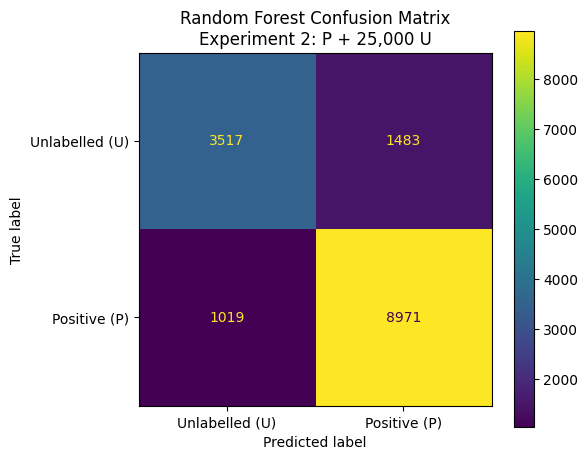

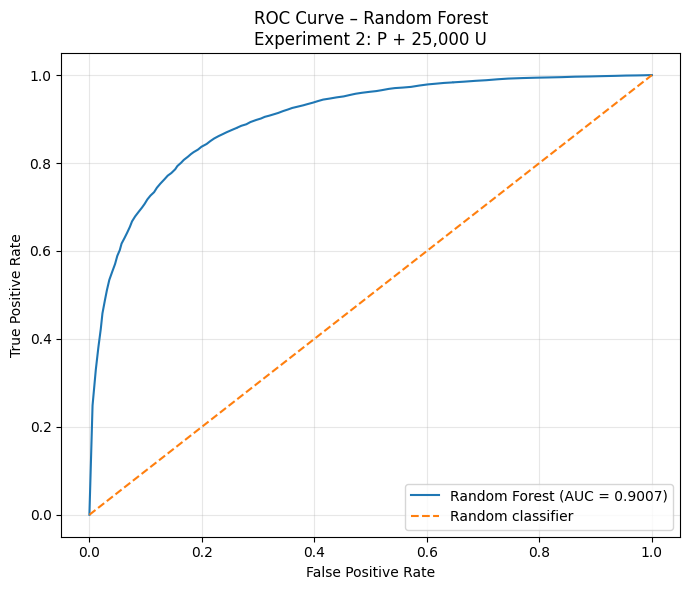


Prediction Distribution
-----------------------
Predicted Unlabelled: 4536
Predicted Positive: 10454
Total predictions: 14990

Stored Experiment 2 Results
---------------------------
  Experiment         Model  Positive  Unlabelled  Train_Size  Test_Size  Balanced_Accuracy  ROC_AUC
Experiment 2 Random Forest     49947       25000       59957      14990           0.800699 0.900743

Step 31 Final Validation
✓ Prediction count matches the Experiment 2 test set.
✓ Balanced accuracy calculated.
✓ ROC-AUC calculated.
✓ Balanced accuracy is within the expected range.
✓ ROC-AUC is within the expected range.

✓ Random Forest baseline completed for Experiment 2.
✓ The model discriminates observed Positive (P) from Unlabelled (U) pairs.
✓ PU_Label = 0 remains an UNLABELLED class rather than a confirmed biological negative.

Important Interpretation
------------------------
Performance metrics describe discrimination between known positive and unlabelled pairs.
They must not be interpreted as per

3533

In [6]:
# ============================================================
# Step 31
# Baseline Random Forest Classification
# Experiment 2: Positive + 25,000 Unlabelled
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gc

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

RANDOM_STATE = 42


# ------------------------------------------------------------
# Use Experiment 2 Matrices Prepared in Step 30
# ------------------------------------------------------------
# The familiar X/y variable names are used here for
# consistency with the machine-learning workflow.
# ------------------------------------------------------------

X_train = X_train_exp2
X_test = X_test_exp2

y_train = y_train_exp2
y_test = y_test_exp2


print("Experiment 2 Modelling Dataset")
print("------------------------------")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


print("\nTraining label distribution:")

unique_train, counts_train = np.unique(
    y_train,
    return_counts=True
)

for label, count in zip(
    unique_train,
    counts_train
):
    status = "P" if label == 1 else "U"

    print(
        f"{status} (PU_Label={label}): {count}"
    )


print("\nTest label distribution:")

unique_test, counts_test = np.unique(
    y_test,
    return_counts=True
)

for label, count in zip(
    unique_test,
    counts_test
):
    status = "P" if label == 1 else "U"

    print(
        f"{status} (PU_Label={label}): {count}"
    )


# ------------------------------------------------------------
# Random Forest Baseline
# ------------------------------------------------------------

print("\n======================================")
print("Random Forest Baseline")
print("======================================")


rf = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)


print("\nTraining Random Forest...")

rf.fit(
    X_train,
    y_train
)

print("✓ Random Forest training completed.")


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

print("\nGenerating predictions...")


y_pred_rf = rf.predict(
    X_test
)


y_proba_rf = rf.predict_proba(
    X_test
)[:, 1]


print("✓ Predictions generated.")


# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\n======================================")
print("Classification Report")
print("======================================")


print(
    classification_report(
        y_test,
        y_pred_rf,
        labels=[0, 1],
        target_names=[
            "Unlabelled (U)",
            "Positive (P)"
        ],
        digits=4
    )
)


# ------------------------------------------------------------
# Balanced Accuracy
# ------------------------------------------------------------

balanced_accuracy_rf = (
    balanced_accuracy_score(
        y_test,
        y_pred_rf
    )
)


# ------------------------------------------------------------
# ROC-AUC
# ------------------------------------------------------------

roc_auc_rf = roc_auc_score(
    y_test,
    y_proba_rf
)


# ------------------------------------------------------------
# Display Main Performance Metrics
# ------------------------------------------------------------

print("\n======================================")
print("Random Forest Performance")
print("======================================")


print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_rf,
        4
    )
)


print(
    "ROC-AUC:",
    round(
        roc_auc_rf,
        4
    )
)


# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=[0, 1]
)


print("\nConfusion Matrix")
print("----------------")

print(cm_rf)


print(
    "\nRows = observed PU label"
)

print(
    "Columns = predicted PU label"
)

print(
    "0 = Unlabelled (U), 1 = Positive (P)"
)


# ------------------------------------------------------------
# Plot Confusion Matrix
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(6, 5)
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=[
        "Unlabelled (U)",
        "Positive (P)"
    ]
)


disp.plot(
    ax=ax,
    values_format="d"
)


plt.title(
    "Random Forest Confusion Matrix\n"
    "Experiment 2: P + 25,000 U"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# ROC Curve
# ------------------------------------------------------------

fpr_rf, tpr_rf, thresholds_rf = roc_curve(
    y_test,
    y_proba_rf
)


plt.figure(
    figsize=(7, 6)
)


plt.plot(
    fpr_rf,
    tpr_rf,
    label=(
        "Random Forest "
        f"(AUC = {roc_auc_rf:.4f})"
    )
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve – Random Forest\n"
    "Experiment 2: P + 25,000 U"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Prediction Distribution
# ------------------------------------------------------------

predicted_u = int(
    (y_pred_rf == 0).sum()
)

predicted_p = int(
    (y_pred_rf == 1).sum()
)


print("\nPrediction Distribution")
print("-----------------------")

print(
    "Predicted Unlabelled:",
    predicted_u
)

print(
    "Predicted Positive:",
    predicted_p
)

print(
    "Total predictions:",
    len(y_pred_rf)
)


# ------------------------------------------------------------
# Store Results for Later Experiment Comparison
# ------------------------------------------------------------

results_exp2_rf = {
    "Experiment": "Experiment 2",
    "Model": "Random Forest",
    "Positive": 49947,
    "Unlabelled": 25000,
    "Train_Size": len(y_train),
    "Test_Size": len(y_test),
    "Balanced_Accuracy": balanced_accuracy_rf,
    "ROC_AUC": roc_auc_rf
}


results_exp2_rf_df = pd.DataFrame(
    [results_exp2_rf]
)


print("\nStored Experiment 2 Results")
print("---------------------------")

print(
    results_exp2_rf_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\n======================================")
print("Step 31 Final Validation")
print("======================================")


if len(y_pred_rf) == len(y_test):

    print(
        "✓ Prediction count matches "
        "the Experiment 2 test set."
    )

else:

    raise ValueError(
        "Prediction/test size mismatch."
    )


if np.isfinite(
    balanced_accuracy_rf
):

    print(
        "✓ Balanced accuracy calculated."
    )

else:

    raise ValueError(
        "Invalid balanced accuracy."
    )


if np.isfinite(
    roc_auc_rf
):

    print(
        "✓ ROC-AUC calculated."
    )

else:

    raise ValueError(
        "Invalid ROC-AUC."
    )


if (
    0.0
    <= balanced_accuracy_rf
    <= 1.0
):

    print(
        "✓ Balanced accuracy is within "
        "the expected range."
    )

else:

    raise ValueError(
        "Balanced accuracy outside [0, 1]."
    )


if (
    0.0
    <= roc_auc_rf
    <= 1.0
):

    print(
        "✓ ROC-AUC is within "
        "the expected range."
    )

else:

    raise ValueError(
        "ROC-AUC outside [0, 1]."
    )


print(
    "\n✓ Random Forest baseline completed "
    "for Experiment 2."
)

print(
    "✓ The model discriminates observed "
    "Positive (P) from Unlabelled (U) pairs."
)

print(
    "✓ PU_Label = 0 remains an UNLABELLED "
    "class rather than a confirmed biological negative."
)


# ------------------------------------------------------------
# Important Interpretation
# ------------------------------------------------------------

print("\nImportant Interpretation")
print("------------------------")

print(
    "Performance metrics describe discrimination "
    "between known positive and unlabelled pairs."
)

print(
    "They must not be interpreted as performance "
    "against experimentally confirmed negatives."
)


# ------------------------------------------------------------
# Memory Cleanup
# ------------------------------------------------------------
# Keep:
#   rf
#   y_pred_rf
#   y_proba_rf
#   balanced_accuracy_rf
#   roc_auc_rf
#   results_exp2_rf_df
#
# These will be useful for later comparison.
# ------------------------------------------------------------

gc.collect()

## Step 32 – Random Forest Classification for Experiment 3

This step applies the same baseline Random Forest classification procedure used in Experiment 2 to Experiment 3.

Experiment 3 contains the complete controlled Positive–Unlabelled dataset:

- 49,947 known positive (P) drug–disease associations, and
- 49,947 unlabelled (U) drug–disease pairs.

Following the stratified 80:20 train–test split performed in Step 29, Experiment 3 contains:

- **Training set:** 79,915 observations
  - 39,958 positive
  - 39,957 unlabelled
- **Test set:** 19,979 observations
  - 9,989 positive
  - 9,990 unlabelled

Each observation contains the same 2,062 modelling features used in Experiment 2:

- 10 molecular descriptors,
- 2,048 Morgan fingerprint features, and
- 4 disease-level features.

### Experimental Consistency

The Random Forest configuration is kept identical to Experiment 2:

- 100 decision trees,
- `random_state = 42`, and
- parallel tree construction using `n_jobs = -1`.

No hyperparameter tuning is introduced between the experiments. This allows the effect of increasing the number of unlabelled observations from 25,000 to 49,947 to be examined while keeping the classifier configuration constant.

The model is evaluated using:

- Classification report
- Balanced accuracy
- ROC-AUC
- Confusion matrix
- ROC curve

As in Experiment 2, `PU_Label = 0` represents an **unlabelled** drug–disease pair and not a confirmed biological negative. Therefore, the reported metrics measure discrimination between known positive and unlabelled observations under the constructed PU experimental setting.

The results from Experiments 2 and 3 are subsequently compared to assess how increasing the unlabelled sample influences predictive behaviour.

Experiment 3 Modelling Dataset
------------------------------
X_train: (79915, 2062)
X_test : (19979, 2062)
y_train: (79915,)
y_test : (19979,)

Training label distribution:
U (PU_Label=0): 39957
P (PU_Label=1): 39958

Test label distribution:
U (PU_Label=0): 9990
P (PU_Label=1): 9989

Random Forest Baseline

Training Random Forest...
✓ Random Forest training completed.

Generating predictions...
✓ Predictions generated.

Classification Report
                precision    recall  f1-score   support

Unlabelled (U)     0.8179    0.8301    0.8239      9990
  Positive (P)     0.8275    0.8151    0.8213      9989

      accuracy                         0.8226     19979
     macro avg     0.8227    0.8226    0.8226     19979
  weighted avg     0.8227    0.8226    0.8226     19979


Random Forest Performance
Balanced Accuracy: 0.8226
ROC-AUC: 0.9024

Confusion Matrix
----------------
[[8293 1697]
 [1847 8142]]

Rows = observed PU label
Columns = predicted PU label
0 = Unlabelled (U), 1 = Pos

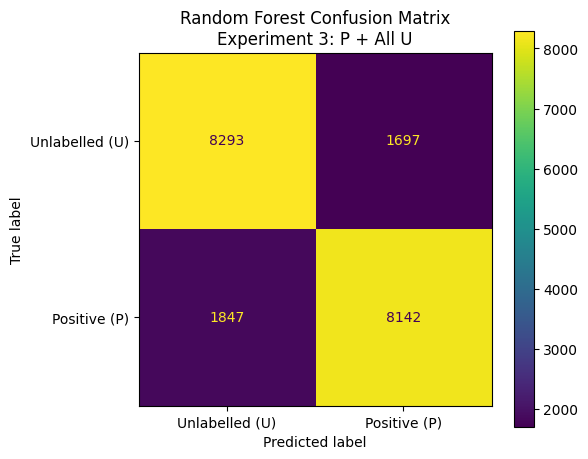

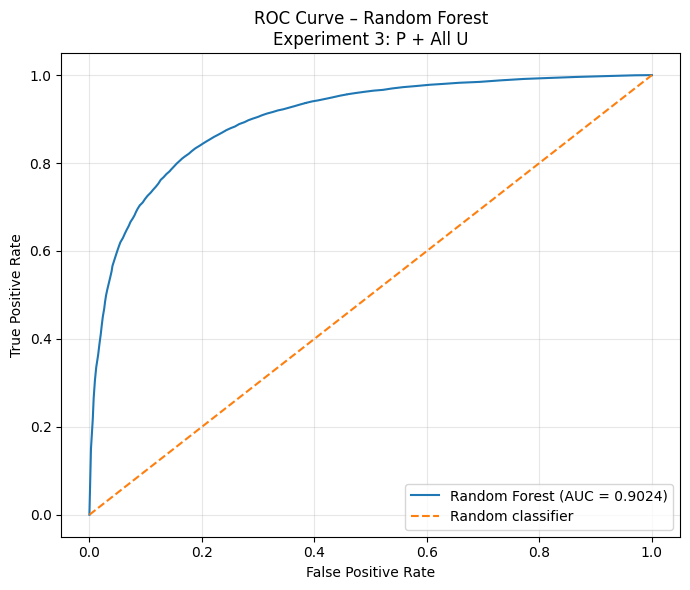


Prediction Distribution
-----------------------
Predicted Unlabelled: 10140
Predicted Positive: 9839
Total predictions: 19979

Stored Experiment 3 Results
---------------------------
  Experiment         Model  Positive  Unlabelled  Train_Size  Test_Size  Balanced_Accuracy  ROC_AUC
Experiment 3 Random Forest     49947       49947       79915      19979           0.822613 0.902405

Random Forest Experiment Comparison
  Experiment         Model  Positive  Unlabelled  Train_Size  Test_Size  Balanced_Accuracy  ROC_AUC
Experiment 2 Random Forest     49947       25000       59957      14990           0.800699 0.900743
Experiment 3 Random Forest     49947       49947       79915      19979           0.822613 0.902405

Change After Increasing Unlabelled Data
---------------------------------------
Balanced Accuracy change: 0.0219
ROC-AUC change: 0.0017

Step 32 Final Validation
✓ Prediction count matches the Experiment 3 test set.
✓ Balanced accuracy calculated.
✓ ROC-AUC calculated.
✓ Balanc

7860

In [7]:
# ============================================================
# Step 32
# Random Forest Classification
# Experiment 3: Positive + All Unlabelled
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gc

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

RANDOM_STATE = 42


# ------------------------------------------------------------
# Use Experiment 3 Matrices Prepared in Step 30
# ------------------------------------------------------------

X_train = X_train_exp3
X_test = X_test_exp3

y_train = y_train_exp3
y_test = y_test_exp3


print("Experiment 3 Modelling Dataset")
print("------------------------------")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


# ------------------------------------------------------------
# Display Label Distributions
# ------------------------------------------------------------

print("\nTraining label distribution:")

unique_train, counts_train = np.unique(
    y_train,
    return_counts=True
)

for label, count in zip(
    unique_train,
    counts_train
):
    status = "P" if label == 1 else "U"

    print(
        f"{status} (PU_Label={label}): {count}"
    )


print("\nTest label distribution:")

unique_test, counts_test = np.unique(
    y_test,
    return_counts=True
)

for label, count in zip(
    unique_test,
    counts_test
):
    status = "P" if label == 1 else "U"

    print(
        f"{status} (PU_Label={label}): {count}"
    )


# ------------------------------------------------------------
# Random Forest Baseline
# ------------------------------------------------------------
# IMPORTANT:
# Keep exactly the same RF configuration as Experiment 2
# so that the experiments are directly comparable.
# ------------------------------------------------------------

print("\n======================================")
print("Random Forest Baseline")
print("======================================")


rf_exp3 = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)


print("\nTraining Random Forest...")

rf_exp3.fit(
    X_train,
    y_train
)

print("✓ Random Forest training completed.")


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

print("\nGenerating predictions...")


y_pred_rf_exp3 = rf_exp3.predict(
    X_test
)


y_proba_rf_exp3 = rf_exp3.predict_proba(
    X_test
)[:, 1]


print("✓ Predictions generated.")


# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\n======================================")
print("Classification Report")
print("======================================")


print(
    classification_report(
        y_test,
        y_pred_rf_exp3,
        labels=[0, 1],
        target_names=[
            "Unlabelled (U)",
            "Positive (P)"
        ],
        digits=4
    )
)


# ------------------------------------------------------------
# Balanced Accuracy
# ------------------------------------------------------------

balanced_accuracy_rf_exp3 = (
    balanced_accuracy_score(
        y_test,
        y_pred_rf_exp3
    )
)


# ------------------------------------------------------------
# ROC-AUC
# ------------------------------------------------------------

roc_auc_rf_exp3 = roc_auc_score(
    y_test,
    y_proba_rf_exp3
)


# ------------------------------------------------------------
# Display Main Performance Metrics
# ------------------------------------------------------------

print("\n======================================")
print("Random Forest Performance")
print("======================================")


print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_rf_exp3,
        4
    )
)


print(
    "ROC-AUC:",
    round(
        roc_auc_rf_exp3,
        4
    )
)


# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

cm_rf_exp3 = confusion_matrix(
    y_test,
    y_pred_rf_exp3,
    labels=[0, 1]
)


print("\nConfusion Matrix")
print("----------------")

print(cm_rf_exp3)


print(
    "\nRows = observed PU label"
)

print(
    "Columns = predicted PU label"
)

print(
    "0 = Unlabelled (U), 1 = Positive (P)"
)


# ------------------------------------------------------------
# Plot Confusion Matrix
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(6, 5)
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_exp3,
    display_labels=[
        "Unlabelled (U)",
        "Positive (P)"
    ]
)


disp.plot(
    ax=ax,
    values_format="d"
)


plt.title(
    "Random Forest Confusion Matrix\n"
    "Experiment 3: P + All U"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# ROC Curve
# ------------------------------------------------------------

fpr_rf_exp3, tpr_rf_exp3, thresholds_rf_exp3 = (
    roc_curve(
        y_test,
        y_proba_rf_exp3
    )
)


plt.figure(
    figsize=(7, 6)
)


plt.plot(
    fpr_rf_exp3,
    tpr_rf_exp3,
    label=(
        "Random Forest "
        f"(AUC = {roc_auc_rf_exp3:.4f})"
    )
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve – Random Forest\n"
    "Experiment 3: P + All U"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Prediction Distribution
# ------------------------------------------------------------

predicted_u_exp3 = int(
    (y_pred_rf_exp3 == 0).sum()
)

predicted_p_exp3 = int(
    (y_pred_rf_exp3 == 1).sum()
)


print("\nPrediction Distribution")
print("-----------------------")

print(
    "Predicted Unlabelled:",
    predicted_u_exp3
)

print(
    "Predicted Positive:",
    predicted_p_exp3
)

print(
    "Total predictions:",
    len(y_pred_rf_exp3)
)


# ------------------------------------------------------------
# Store Experiment 3 Results
# ------------------------------------------------------------

results_exp3_rf = {
    "Experiment": "Experiment 3",
    "Model": "Random Forest",
    "Positive": 49947,
    "Unlabelled": 49947,
    "Train_Size": len(y_train),
    "Test_Size": len(y_test),
    "Balanced_Accuracy": balanced_accuracy_rf_exp3,
    "ROC_AUC": roc_auc_rf_exp3
}


results_exp3_rf_df = pd.DataFrame(
    [results_exp3_rf]
)


print("\nStored Experiment 3 Results")
print("---------------------------")

print(
    results_exp3_rf_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Compare Experiment 2 and Experiment 3
# ------------------------------------------------------------

print("\n======================================")
print("Random Forest Experiment Comparison")
print("======================================")


rf_comparison_df = pd.concat(
    [
        results_exp2_rf_df,
        results_exp3_rf_df
    ],
    ignore_index=True
)


print(
    rf_comparison_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Calculate Change from Experiment 2 to Experiment 3
# ------------------------------------------------------------

balanced_accuracy_change = (
    balanced_accuracy_rf_exp3
    - balanced_accuracy_rf
)


roc_auc_change = (
    roc_auc_rf_exp3
    - roc_auc_rf
)


print("\nChange After Increasing Unlabelled Data")
print("---------------------------------------")


print(
    "Balanced Accuracy change:",
    round(
        balanced_accuracy_change,
        4
    )
)


print(
    "ROC-AUC change:",
    round(
        roc_auc_change,
        4
    )
)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\n======================================")
print("Step 32 Final Validation")
print("======================================")


if len(y_pred_rf_exp3) == len(y_test):

    print(
        "✓ Prediction count matches "
        "the Experiment 3 test set."
    )

else:

    raise ValueError(
        "Prediction/test size mismatch."
    )


if np.isfinite(
    balanced_accuracy_rf_exp3
):

    print(
        "✓ Balanced accuracy calculated."
    )

else:

    raise ValueError(
        "Invalid balanced accuracy."
    )


if np.isfinite(
    roc_auc_rf_exp3
):

    print(
        "✓ ROC-AUC calculated."
    )

else:

    raise ValueError(
        "Invalid ROC-AUC."
    )


if (
    0.0
    <= balanced_accuracy_rf_exp3
    <= 1.0
):

    print(
        "✓ Balanced accuracy is within "
        "the expected range."
    )

else:

    raise ValueError(
        "Balanced accuracy outside [0, 1]."
    )


if (
    0.0
    <= roc_auc_rf_exp3
    <= 1.0
):

    print(
        "✓ ROC-AUC is within "
        "the expected range."
    )

else:

    raise ValueError(
        "ROC-AUC outside [0, 1]."
    )


print(
    "\n✓ Random Forest baseline completed "
    "for Experiment 3."
)

print(
    "✓ The same Random Forest configuration "
    "was used for Experiments 2 and 3."
)

print(
    "✓ The effect of increasing the unlabelled "
    "sample can now be compared."
)

print(
    "\n✓ PU_Label = 0 remains an UNLABELLED "
    "class rather than a confirmed biological negative."
)


# ------------------------------------------------------------
# Important Interpretation
# ------------------------------------------------------------

print("\nImportant Interpretation")
print("------------------------")

print(
    "The comparison measures how model behaviour "
    "changes when the unlabelled pool is increased."
)

print(
    "Performance metrics describe discrimination "
    "between known positive and unlabelled pairs."
)

print(
    "They must not be interpreted as performance "
    "against experimentally confirmed negatives."
)


gc.collect()

## Step 33 – Comparison of Random Forest Performance Across PU Experiments

This step compares the Random Forest results obtained from Experiments 2 and 3 to investigate the effect of progressively increasing the number of unlabelled drug–disease pairs.

The Random Forest configuration and train–test procedure were kept unchanged between the two experiments. Therefore, the principal experimental difference is the number of unlabelled observations introduced into the dataset.

- **Experiment 2:** 49,947 positive + 25,000 unlabelled observations
- **Experiment 3:** 49,947 positive + 49,947 unlabelled observations

The comparison focuses on:

- Balanced accuracy
- ROC-AUC
- Recall for the positive class
- Recall for the unlabelled class
- Prediction behaviour

In Experiment 2, the Random Forest achieved a balanced accuracy of 0.8007 and ROC-AUC of 0.9007. In Experiment 3, balanced accuracy increased to 0.8226 while ROC-AUC increased slightly to 0.9024.

Increasing the unlabelled pool also changed class-specific recall. Recall for the unlabelled class increased from 0.7034 to 0.8301, whereas recall for the known-positive class decreased from 0.8980 to 0.8151. This indicates that increasing the unlabelled sample produced more balanced discrimination between the observed P and U groups rather than uniformly improving performance for both classes.

These results must be interpreted within the Positive–Unlabelled setting. The U class consists of unlabelled observations rather than experimentally confirmed negatives. Consequently, predictions and performance measures describe discrimination between known positive and constructed unlabelled samples and do not represent evaluation against verified biological negatives.

Random Forest PU Experiment Comparison
  Experiment  Positive_Samples  Unlabelled_Samples  Balanced_Accuracy  ROC_AUC  U_Recall  P_Recall
Experiment 2             49947               25000           0.800699 0.900743   0.70340  0.897998
Experiment 3             49947               49947           0.822613 0.902405   0.83013  0.815097

Performance Changes
-------------------
           Metric  Experiment_2  Experiment_3    Change
Balanced Accuracy      0.800699      0.822613  0.021914
          ROC-AUC      0.900743      0.902405  0.001662
         U Recall      0.703400      0.830130  0.126730
         P Recall      0.897998      0.815097 -0.082901


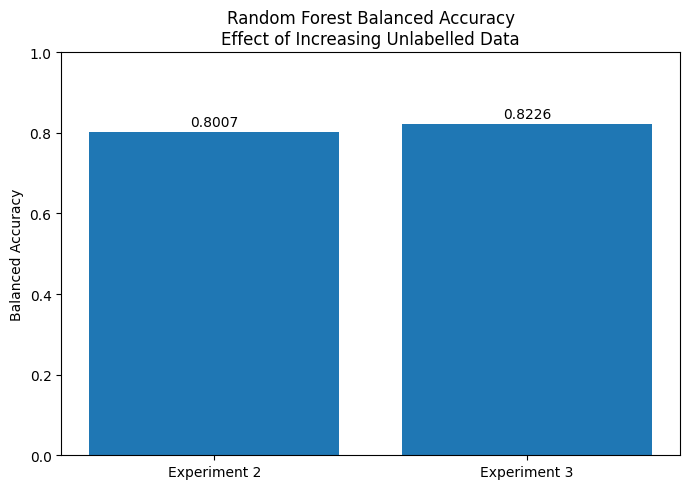

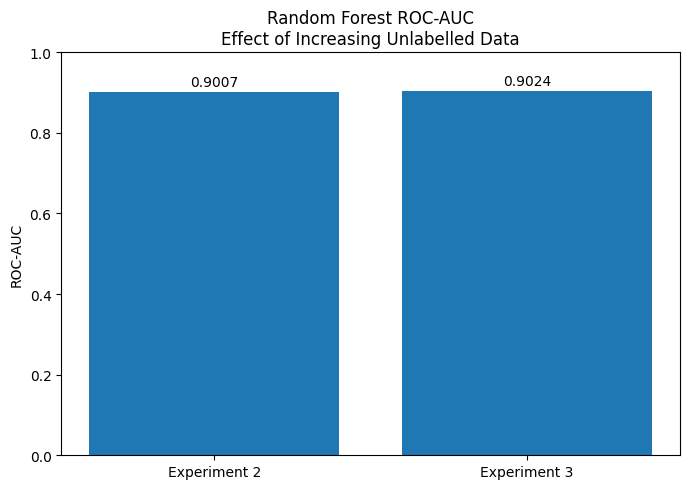

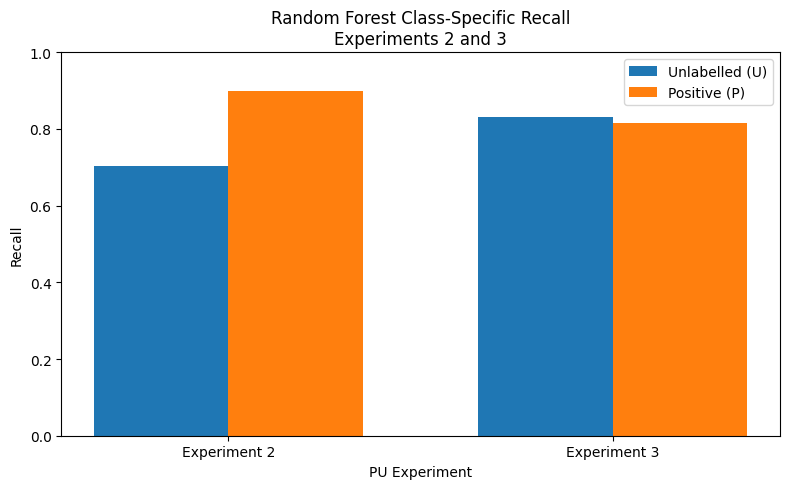

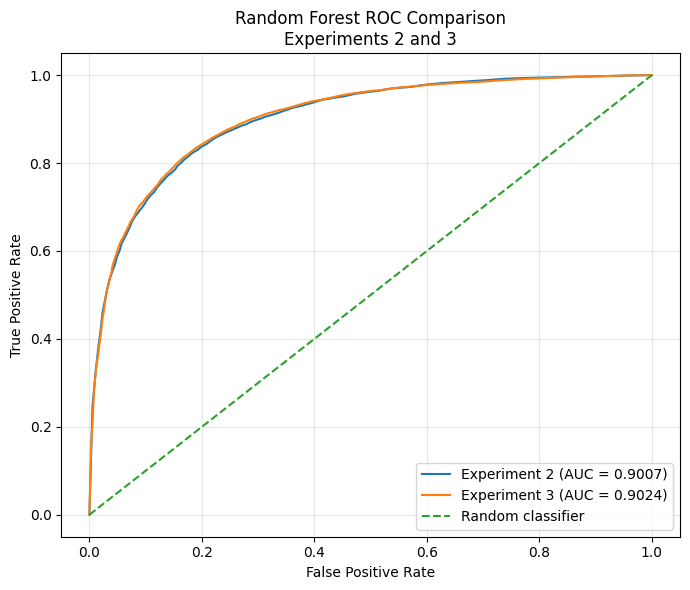


Observed Effect of Increasing U
Balanced Accuracy:
  Experiment 2 = 0.8007
  Experiment 3 = 0.8226
  Change       = +0.0219

ROC-AUC:
  Experiment 2 = 0.9007
  Experiment 3 = 0.9024
  Change       = +0.0017

Unlabelled Recall:
  Experiment 2 = 0.7034
  Experiment 3 = 0.8301
  Change       = +0.1267

Positive Recall:
  Experiment 2 = 0.8980
  Experiment 3 = 0.8151
  Change       = -0.0829

Step 33 Interpretation
Increasing the unlabelled pool from 25,000 to 49,947 increased balanced accuracy.
ROC-AUC changed only slightly.
Recall for the unlabelled class increased, while recall for the positive class decreased.
The larger unlabelled pool therefore changed the balance of discrimination between the observed P and U groups.

PU_Label = 0 represents unlabelled observations rather than confirmed biological negatives.


In [8]:
# ============================================================
# Step 33
# Comparison of Random Forest Performance
# Experiments 2 and 3
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Class-Specific Recall Values
# Obtained from the confusion matrices
# ------------------------------------------------------------

# Experiment 2
# U: 3517 correctly predicted from 5000
# P: 8971 correctly predicted from 9990

u_recall_exp2 = 3517 / 5000
p_recall_exp2 = 8971 / 9990


# Experiment 3
# U: 8293 correctly predicted from 9990
# P: 8142 correctly predicted from 9989

u_recall_exp3 = 8293 / 9990
p_recall_exp3 = 8142 / 9989


# ------------------------------------------------------------
# Construct Comparison Table
# ------------------------------------------------------------

rf_detailed_comparison = pd.DataFrame(
    {
        "Experiment": [
            "Experiment 2",
            "Experiment 3"
        ],

        "Positive_Samples": [
            49947,
            49947
        ],

        "Unlabelled_Samples": [
            25000,
            49947
        ],

        "Balanced_Accuracy": [
            balanced_accuracy_rf,
            balanced_accuracy_rf_exp3
        ],

        "ROC_AUC": [
            roc_auc_rf,
            roc_auc_rf_exp3
        ],

        "U_Recall": [
            u_recall_exp2,
            u_recall_exp3
        ],

        "P_Recall": [
            p_recall_exp2,
            p_recall_exp3
        ]
    }
)


print("======================================")
print("Random Forest PU Experiment Comparison")
print("======================================")

print(
    rf_detailed_comparison.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Calculate Changes
# ------------------------------------------------------------

metric_changes = pd.DataFrame(
    {
        "Metric": [
            "Balanced Accuracy",
            "ROC-AUC",
            "U Recall",
            "P Recall"
        ],

        "Experiment_2": [
            balanced_accuracy_rf,
            roc_auc_rf,
            u_recall_exp2,
            p_recall_exp2
        ],

        "Experiment_3": [
            balanced_accuracy_rf_exp3,
            roc_auc_rf_exp3,
            u_recall_exp3,
            p_recall_exp3
        ]
    }
)


metric_changes["Change"] = (
    metric_changes["Experiment_3"]
    - metric_changes["Experiment_2"]
)


print("\nPerformance Changes")
print("-------------------")

print(
    metric_changes.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Plot Balanced Accuracy
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    rf_detailed_comparison["Experiment"],
    rf_detailed_comparison["Balanced_Accuracy"]
)

plt.ylabel(
    "Balanced Accuracy"
)

plt.title(
    "Random Forest Balanced Accuracy\n"
    "Effect of Increasing Unlabelled Data"
)

plt.ylim(
    0,
    1
)

for i, value in enumerate(
    rf_detailed_comparison["Balanced_Accuracy"]
):

    plt.text(
        i,
        value + 0.015,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot ROC-AUC
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    rf_detailed_comparison["Experiment"],
    rf_detailed_comparison["ROC_AUC"]
)

plt.ylabel(
    "ROC-AUC"
)

plt.title(
    "Random Forest ROC-AUC\n"
    "Effect of Increasing Unlabelled Data"
)

plt.ylim(
    0,
    1
)

for i, value in enumerate(
    rf_detailed_comparison["ROC_AUC"]
):

    plt.text(
        i,
        value + 0.015,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot Class-Specific Recall
# ------------------------------------------------------------

recall_comparison = pd.DataFrame(
    {
        "Experiment": [
            "Experiment 2",
            "Experiment 3"
        ],

        "Unlabelled Recall": [
            u_recall_exp2,
            u_recall_exp3
        ],

        "Positive Recall": [
            p_recall_exp2,
            p_recall_exp3
        ]
    }
)


x = np.arange(
    len(recall_comparison)
)

width = 0.35


plt.figure(
    figsize=(8, 5)
)


plt.bar(
    x - width / 2,
    recall_comparison["Unlabelled Recall"],
    width,
    label="Unlabelled (U)"
)


plt.bar(
    x + width / 2,
    recall_comparison["Positive Recall"],
    width,
    label="Positive (P)"
)


plt.xticks(
    x,
    recall_comparison["Experiment"]
)

plt.ylabel(
    "Recall"
)

plt.xlabel(
    "PU Experiment"
)

plt.title(
    "Random Forest Class-Specific Recall\n"
    "Experiments 2 and 3"
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Compare ROC Curves Directly
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 6)
)


plt.plot(
    fpr_rf,
    tpr_rf,
    label=(
        "Experiment 2 "
        f"(AUC = {roc_auc_rf:.4f})"
    )
)


plt.plot(
    fpr_rf_exp3,
    tpr_rf_exp3,
    label=(
        "Experiment 3 "
        f"(AUC = {roc_auc_rf_exp3:.4f})"
    )
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Random Forest ROC Comparison\n"
    "Experiments 2 and 3"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Summary of Observed Changes
# ------------------------------------------------------------

print("\n======================================")
print("Observed Effect of Increasing U")
print("======================================")


print(
    "Balanced Accuracy:"
)

print(
    f"  Experiment 2 = "
    f"{balanced_accuracy_rf:.4f}"
)

print(
    f"  Experiment 3 = "
    f"{balanced_accuracy_rf_exp3:.4f}"
)

print(
    f"  Change       = "
    f"{balanced_accuracy_rf_exp3 - balanced_accuracy_rf:+.4f}"
)


print("\nROC-AUC:")

print(
    f"  Experiment 2 = "
    f"{roc_auc_rf:.4f}"
)

print(
    f"  Experiment 3 = "
    f"{roc_auc_rf_exp3:.4f}"
)

print(
    f"  Change       = "
    f"{roc_auc_rf_exp3 - roc_auc_rf:+.4f}"
)


print("\nUnlabelled Recall:")

print(
    f"  Experiment 2 = "
    f"{u_recall_exp2:.4f}"
)

print(
    f"  Experiment 3 = "
    f"{u_recall_exp3:.4f}"
)

print(
    f"  Change       = "
    f"{u_recall_exp3 - u_recall_exp2:+.4f}"
)


print("\nPositive Recall:")

print(
    f"  Experiment 2 = "
    f"{p_recall_exp2:.4f}"
)

print(
    f"  Experiment 3 = "
    f"{p_recall_exp3:.4f}"
)

print(
    f"  Change       = "
    f"{p_recall_exp3 - p_recall_exp2:+.4f}"
)


# ------------------------------------------------------------
# Final Interpretation
# ------------------------------------------------------------

print("\n======================================")
print("Step 33 Interpretation")
print("======================================")


print(
    "Increasing the unlabelled pool from "
    "25,000 to 49,947 increased balanced "
    "accuracy."
)

print(
    "ROC-AUC changed only slightly."
)

print(
    "Recall for the unlabelled class increased, "
    "while recall for the positive class decreased."
)

print(
    "The larger unlabelled pool therefore changed "
    "the balance of discrimination between the "
    "observed P and U groups."
)

print(
    "\nPU_Label = 0 represents unlabelled observations "
    "rather than confirmed biological negatives."
)

## Step 34 – Linear SVM Classification for Experiment 2

This step evaluates a second machine-learning classifier using Experiment 2, which contains known positive drug–disease associations together with 25,000 sampled unlabelled pairs.

Experiment 2 contains:

- 49,947 known positive (P) drug–disease associations
- 25,000 unlabelled (U) drug–disease pairs

The stratified 80:20 split generated in Step 29 is used:

- **Training set:** 59,957 observations
  - 39,957 positive
  - 20,000 unlabelled
- **Test set:** 14,990 observations
  - 9,990 positive
  - 5,000 unlabelled

Each observation is represented using the same 2,062 modelling features consisting of:

- 10 molecular descriptors
- 2,048 Morgan fingerprint features
- 4 disease-level features

### Linear Support Vector Machine

A Linear Support Vector Machine (Linear SVM) is used as the second classifier. A linear formulation is selected instead of a nonlinear RBF SVM because the dataset contains a large number of observations and high-dimensional molecular fingerprint features. This provides a computationally more practical SVM-based model for the available dataset.

The model is trained using the observed PU labels:

- `PU_Label = 1` represents a known positive association.
- `PU_Label = 0` represents an unlabelled pair.

The unlabelled class is used as the operational comparison class during classifier training but is not interpreted as a set of confirmed biological negatives.

### Feature Scaling

Feature scaling is performed because the molecular descriptors and disease-level variables have substantially different numerical ranges. `StandardScaler` is fitted using only the training data and then applied to the test data.

The scaler uses `with_mean=False` to avoid unnecessary mean-centering of the high-dimensional feature matrix and reduce additional memory requirements.

### Evaluation

The Linear SVM is evaluated using:

- Classification report
- Balanced accuracy
- ROC-AUC
- Confusion matrix
- ROC curve

The SVM decision-function scores are used for ROC-AUC and ROC-curve calculation.

This step processes Experiment 2 independently and removes large modelling objects from memory after evaluation. This memory-conscious workflow avoids retaining multiple large feature matrices and trained models simultaneously.

As throughout the PU experiments, the reported metrics measure discrimination between known positive and unlabelled observations and must not be interpreted as evaluation against experimentally confirmed negative drug–disease associations.

Step 34
Linear SVM – Experiment 2

Loading Experiment 2 train/test data...
Training dataset: (59957, 2068)
Test dataset    : (14990, 2068)

Feature Configuration
---------------------
Molecular descriptors: 10
Morgan fingerprints: 2048
Disease features: 4
Total modelling features: 2062

Preparing feature matrices...
X_train: (59957, 2062)
X_test : (14990, 2062)
y_train: (59957,)
y_test : (14990,)
✓ Source DataFrames released from memory.

Training PU distribution:
Unlabelled (U): 20000
Positive (P): 39957

Test PU distribution:
Unlabelled (U): 5000
Positive (P): 9990

Feature Scaling

Fitting scaler using training data...
✓ Feature scaling completed.
X_train dtype: float32
X_test dtype : float32

Linear SVM

Training Linear SVM...
✓ Linear SVM training completed.

Generating predictions...
✓ Predictions generated.

Classification Report
                precision    recall  f1-score   support

Unlabelled (U)     0.7204    0.6334    0.6741      5000
  Positive (P)     0.8270    0.8770   

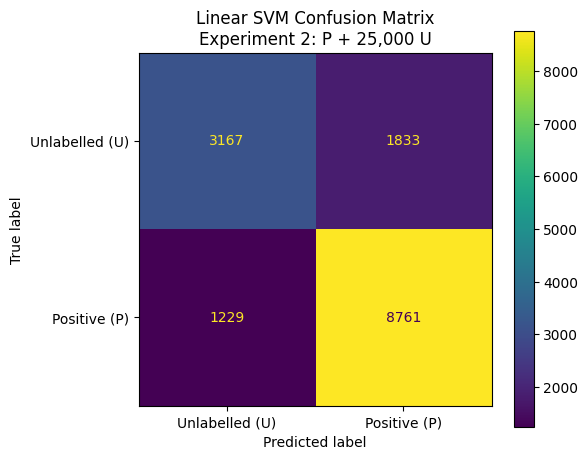

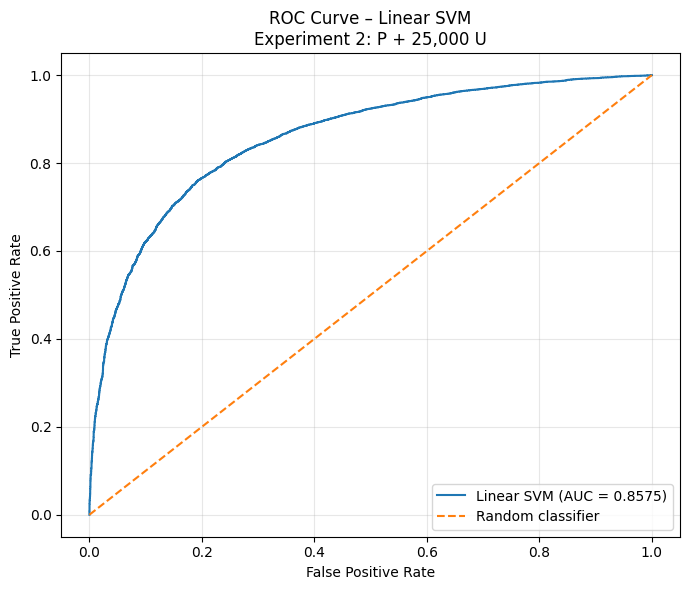


Prediction Distribution
-----------------------
Predicted Unlabelled: 4396
Predicted Positive: 10594
Total predictions: 14990

Stored Experiment 2 SVM Results
--------------------------------
  Experiment      Model  Positive  Unlabelled  Train_Size  Test_Size  Balanced_Accuracy  ROC_AUC  U_Recall  P_Recall
Experiment 2 Linear SVM     49947       25000       59957      14990           0.755188 0.857494    0.6334  0.876977

✓ Results saved:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step34_exp2_linear_svm_results.csv

Step 34 Final Validation
✓ Prediction count matches test set.
✓ Balanced accuracy calculated.
✓ ROC-AUC calculated.
✓ Class-specific recall calculated.
✓ Experiment 2 Linear SVM completed.

✓ PU_Label = 0 remains UNLABELLED rather than a confirmed biological negative.

Important Interpretation
------------------------
The Linear SVM discriminates known positive from unlabelled observations.
The performance measures do not represent evaluation against confirmed biological

In [10]:
# ============================================================
# Step 34
# Memory-Conscious Linear SVM Classification
# Experiment 2: Positive + 25,000 Unlabelled
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gc

from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

RANDOM_STATE = 42

TRAIN_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp2_train.parquet"
)

TEST_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp2_test.parquet"
)


# ------------------------------------------------------------
# Load Experiment 2 Only
# ------------------------------------------------------------

print("======================================")
print("Step 34")
print("Linear SVM – Experiment 2")
print("======================================")

print("\nLoading Experiment 2 train/test data...")


train_df = pd.read_parquet(
    TRAIN_FILE
)

test_df = pd.read_parquet(
    TEST_FILE
)


print("Training dataset:", train_df.shape)
print("Test dataset    :", test_df.shape)


# ------------------------------------------------------------
# Define Feature Columns
# ------------------------------------------------------------

descriptor_columns = [
    "MolWt",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "Rotatable_Bonds",
    "Ring_Count",
    "Aromatic_Ring_Count",
    "Heavy_Atom_Count",
    "Fraction_CSP3"
]


disease_feature_columns = [
    "Num_Targets",
    "Mean_Association_Score",
    "Max_Association_Score",
    "Total_Evidence"
]


fingerprint_columns = [
    column
    for column in train_df.columns
    if column.startswith("FP_")
]


fingerprint_columns = sorted(
    fingerprint_columns,
    key=lambda x: int(x.split("_")[1])
)


model_feature_columns = (
    descriptor_columns
    + fingerprint_columns
    + disease_feature_columns
)


print("\nFeature Configuration")
print("---------------------")

print(
    "Molecular descriptors:",
    len(descriptor_columns)
)

print(
    "Morgan fingerprints:",
    len(fingerprint_columns)
)

print(
    "Disease features:",
    len(disease_feature_columns)
)

print(
    "Total modelling features:",
    len(model_feature_columns)
)


if len(model_feature_columns) != 2062:

    raise ValueError(
        "Expected 2,062 modelling features."
    )


# ------------------------------------------------------------
# Prepare X/y Matrices
# ------------------------------------------------------------

print("\nPreparing feature matrices...")


X_train = (
    train_df[
        model_feature_columns
    ]
    .to_numpy(
        dtype=np.float32
    )
)


X_test = (
    test_df[
        model_feature_columns
    ]
    .to_numpy(
        dtype=np.float32
    )
)


y_train = (
    train_df["PU_Label"]
    .to_numpy(
        dtype=np.int8
    )
)


y_test = (
    test_df["PU_Label"]
    .to_numpy(
        dtype=np.int8
    )
)


print(
    "X_train:",
    X_train.shape
)

print(
    "X_test :",
    X_test.shape
)

print(
    "y_train:",
    y_train.shape
)

print(
    "y_test :",
    y_test.shape
)


# ------------------------------------------------------------
# Delete Source DataFrames Immediately
# ------------------------------------------------------------

del train_df
del test_df

gc.collect()

print(
    "✓ Source DataFrames released from memory."
)


# ------------------------------------------------------------
# Display PU Distribution
# ------------------------------------------------------------

print("\nTraining PU distribution:")

unique_train, counts_train = np.unique(
    y_train,
    return_counts=True
)

for label, count in zip(
    unique_train,
    counts_train
):

    status = (
        "Positive (P)"
        if label == 1
        else "Unlabelled (U)"
    )

    print(
        f"{status}: {count}"
    )


print("\nTest PU distribution:")

unique_test, counts_test = np.unique(
    y_test,
    return_counts=True
)

for label, count in zip(
    unique_test,
    counts_test
):

    status = (
        "Positive (P)"
        if label == 1
        else "Unlabelled (U)"
    )

    print(
        f"{status}: {count}"
    )


# ------------------------------------------------------------
# Feature Scaling
# ------------------------------------------------------------

print("\n======================================")
print("Feature Scaling")
print("======================================")


scaler_svm = StandardScaler(
    with_mean=False,
    copy=False
)


print(
    "\nFitting scaler using training data..."
)


X_train = scaler_svm.fit_transform(
    X_train
)


X_test = scaler_svm.transform(
    X_test
)


print(
    "✓ Feature scaling completed."
)


print(
    "X_train dtype:",
    X_train.dtype
)

print(
    "X_test dtype :",
    X_test.dtype
)


# ------------------------------------------------------------
# Linear SVM
# ------------------------------------------------------------

print("\n======================================")
print("Linear SVM")
print("======================================")


svm = LinearSVC(
    C=1.0,
    random_state=RANDOM_STATE,
    max_iter=5000,
    dual="auto"
)


print(
    "\nTraining Linear SVM..."
)


svm.fit(
    X_train,
    y_train
)


print(
    "✓ Linear SVM training completed."
)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

print(
    "\nGenerating predictions..."
)


y_pred_svm = svm.predict(
    X_test
)


y_score_svm = svm.decision_function(
    X_test
)


print(
    "✓ Predictions generated."
)


# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\n======================================")
print("Classification Report")
print("======================================")


print(
    classification_report(
        y_test,
        y_pred_svm,
        labels=[0, 1],
        target_names=[
            "Unlabelled (U)",
            "Positive (P)"
        ],
        digits=4
    )
)


# ------------------------------------------------------------
# Balanced Accuracy
# ------------------------------------------------------------

balanced_accuracy_svm_exp2 = (
    balanced_accuracy_score(
        y_test,
        y_pred_svm
    )
)


# ------------------------------------------------------------
# ROC-AUC
# ------------------------------------------------------------

roc_auc_svm_exp2 = (
    roc_auc_score(
        y_test,
        y_score_svm
    )
)


print("\n======================================")
print("Linear SVM Performance")
print("======================================")


print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_svm_exp2,
        4
    )
)


print(
    "ROC-AUC:",
    round(
        roc_auc_svm_exp2,
        4
    )
)


# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

cm_svm_exp2 = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=[0, 1]
)


print("\nConfusion Matrix")
print("----------------")

print(
    cm_svm_exp2
)


print(
    "\nRows = observed PU label"
)

print(
    "Columns = predicted PU label"
)

print(
    "0 = Unlabelled (U), 1 = Positive (P)"
)


# ------------------------------------------------------------
# Calculate Class-Specific Recall
# ------------------------------------------------------------

u_recall_svm_exp2 = (
    cm_svm_exp2[0, 0]
    / cm_svm_exp2[0].sum()
)


p_recall_svm_exp2 = (
    cm_svm_exp2[1, 1]
    / cm_svm_exp2[1].sum()
)


print("\nClass-Specific Recall")
print("---------------------")


print(
    "Unlabelled Recall:",
    round(
        u_recall_svm_exp2,
        4
    )
)


print(
    "Positive Recall:",
    round(
        p_recall_svm_exp2,
        4
    )
)


# ------------------------------------------------------------
# Plot Confusion Matrix
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(6, 5)
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm_exp2,
    display_labels=[
        "Unlabelled (U)",
        "Positive (P)"
    ]
)


disp.plot(
    ax=ax,
    values_format="d"
)


plt.title(
    "Linear SVM Confusion Matrix\n"
    "Experiment 2: P + 25,000 U"
)


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# ROC Curve
# ------------------------------------------------------------

fpr_svm_exp2, tpr_svm_exp2, _ = (
    roc_curve(
        y_test,
        y_score_svm
    )
)


plt.figure(
    figsize=(7, 6)
)


plt.plot(
    fpr_svm_exp2,
    tpr_svm_exp2,
    label=(
        "Linear SVM "
        f"(AUC = {roc_auc_svm_exp2:.4f})"
    )
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)


plt.title(
    "ROC Curve – Linear SVM\n"
    "Experiment 2: P + 25,000 U"
)


plt.legend(
    loc="lower right"
)


plt.grid(
    alpha=0.3
)


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Prediction Distribution
# ------------------------------------------------------------

predicted_u_svm_exp2 = int(
    (y_pred_svm == 0).sum()
)


predicted_p_svm_exp2 = int(
    (y_pred_svm == 1).sum()
)


print("\nPrediction Distribution")
print("-----------------------")


print(
    "Predicted Unlabelled:",
    predicted_u_svm_exp2
)


print(
    "Predicted Positive:",
    predicted_p_svm_exp2
)


print(
    "Total predictions:",
    len(y_pred_svm)
)


# ------------------------------------------------------------
# Store Small Result Table
# ------------------------------------------------------------

results_exp2_svm = {
    "Experiment": "Experiment 2",
    "Model": "Linear SVM",
    "Positive": 49947,
    "Unlabelled": 25000,
    "Train_Size": len(y_train),
    "Test_Size": len(y_test),
    "Balanced_Accuracy": (
        balanced_accuracy_svm_exp2
    ),
    "ROC_AUC": (
        roc_auc_svm_exp2
    ),
    "U_Recall": (
        u_recall_svm_exp2
    ),
    "P_Recall": (
        p_recall_svm_exp2
    )
}


results_exp2_svm_df = pd.DataFrame(
    [results_exp2_svm]
)


print("\nStored Experiment 2 SVM Results")
print("--------------------------------")


print(
    results_exp2_svm_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Save Results to Disk
# ------------------------------------------------------------

SVM_RESULTS_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step34_exp2_linear_svm_results.csv"
)


results_exp2_svm_df.to_csv(
    SVM_RESULTS_FILE,
    index=False
)


print(
    "\n✓ Results saved:"
)

print(
    SVM_RESULTS_FILE
)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\n======================================")
print("Step 34 Final Validation")
print("======================================")


if len(y_pred_svm) != len(y_test):

    raise ValueError(
        "Prediction/test size mismatch."
    )


if not (
    0 <= balanced_accuracy_svm_exp2 <= 1
):

    raise ValueError(
        "Invalid balanced accuracy."
    )


if not (
    0 <= roc_auc_svm_exp2 <= 1
):

    raise ValueError(
        "Invalid ROC-AUC."
    )


print(
    "✓ Prediction count matches test set."
)

print(
    "✓ Balanced accuracy calculated."
)

print(
    "✓ ROC-AUC calculated."
)

print(
    "✓ Class-specific recall calculated."
)

print(
    "✓ Experiment 2 Linear SVM completed."
)


print(
    "\n✓ PU_Label = 0 remains UNLABELLED "
    "rather than a confirmed biological negative."
)


# ------------------------------------------------------------
# Important Interpretation
# ------------------------------------------------------------

print("\nImportant Interpretation")
print("------------------------")


print(
    "The Linear SVM discriminates known positive "
    "from unlabelled observations."
)


print(
    "The performance measures do not represent "
    "evaluation against confirmed biological negatives."
)


# ------------------------------------------------------------
# MEMORY CLEANUP
# ------------------------------------------------------------

print("\n======================================")
print("Memory Cleanup")
print("======================================")


# The small numerical results above have been retained
# and saved to CSV. Large modelling objects can now be
# removed before processing Experiment 3.

del X_train
del X_test

del y_train
del y_test

del svm
del scaler_svm

del y_pred_svm
del y_score_svm


gc.collect()


print(
    "✓ Experiment 2 feature matrices deleted."
)

print(
    "✓ Linear SVM model deleted."
)

print(
    "✓ Scaler deleted."
)

print(
    "✓ Prediction arrays deleted."
)

print(
    "✓ Small numerical results retained."
)

print(
    "\n✓ Memory released before Experiment 3."
)

## Step 35 – Linear SVM Classification for Experiment 3

This step applies the same Linear Support Vector Machine (Linear SVM) procedure used in Experiment 2 to Experiment 3.

Experiment 3 contains the complete controlled Positive–Unlabelled dataset:

- 49,947 known positive (P) drug–disease associations
- 49,947 unlabelled (U) drug–disease pairs

Following the stratified 80:20 train–test split performed in Step 29, Experiment 3 contains:

- **Training set:** 79,915 observations
  - 39,958 positive
  - 39,957 unlabelled
- **Test set:** 19,979 observations
  - 9,989 positive
  - 9,990 unlabelled

Each observation is represented by the same 2,062 modelling features:

- 10 molecular descriptors
- 2,048 Morgan fingerprint features
- 4 disease-level features

### Experimental Consistency

The Linear SVM configuration is kept identical to that used for Experiment 2:

- `C = 1.0`
- `random_state = 42`
- `max_iter = 5000`
- `dual = "auto"`

The same feature-scaling procedure is also used. `StandardScaler` is fitted only on the Experiment 3 training data and subsequently applied to the test data. Mean-centering is disabled using `with_mean=False` to reduce unnecessary memory requirements for the high-dimensional feature matrix.

Keeping the model configuration and preprocessing procedure unchanged allows the effect of increasing the unlabelled pool from 25,000 to 49,947 observations to be examined under the same Linear SVM modelling conditions.

### Evaluation

The model is evaluated using:

- Classification report
- Balanced accuracy
- ROC-AUC
- Confusion matrix
- Class-specific recall
- ROC curve

The SVM decision-function scores are used for ROC-AUC and ROC-curve calculation.

As in the previous experiments, `PU_Label = 0` represents an **unlabelled** drug–disease pair rather than a confirmed biological negative. Therefore, the evaluation measures discrimination between known positive and unlabelled observations under the constructed PU setting.

A memory-conscious workflow is maintained by loading only Experiment 3 for this step and deleting the large feature matrices and fitted model after the numerical results have been saved.

Step 35
Linear SVM – Experiment 3

Loading Experiment 3 train/test data...
Training dataset: (79915, 2068)
Test dataset    : (19979, 2068)

Feature Configuration
---------------------
Molecular descriptors: 10
Morgan fingerprints: 2048
Disease features: 4
Total modelling features: 2062

Preparing feature matrices...
X_train: (79915, 2062)
X_test : (19979, 2062)
y_train: (79915,)
y_test : (19979,)
✓ Source DataFrames released from memory.

Training PU distribution:
Unlabelled (U): 39957
Positive (P): 39958

Test PU distribution:
Unlabelled (U): 9990
Positive (P): 9989

Feature Scaling

Fitting scaler using training data...
✓ Feature scaling completed.
X_train dtype: float32
X_test dtype : float32

Linear SVM

Training Linear SVM...
✓ Linear SVM training completed.

Generating predictions...
✓ Predictions generated.

Classification Report
                precision    recall  f1-score   support

Unlabelled (U)     0.7709    0.8061    0.7881      9990
  Positive (P)     0.7968    0.7604   

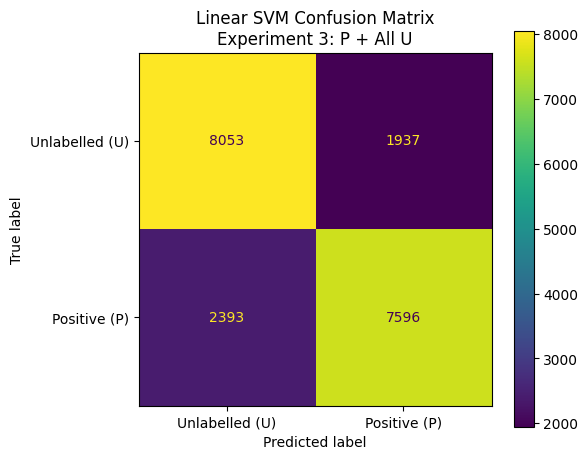

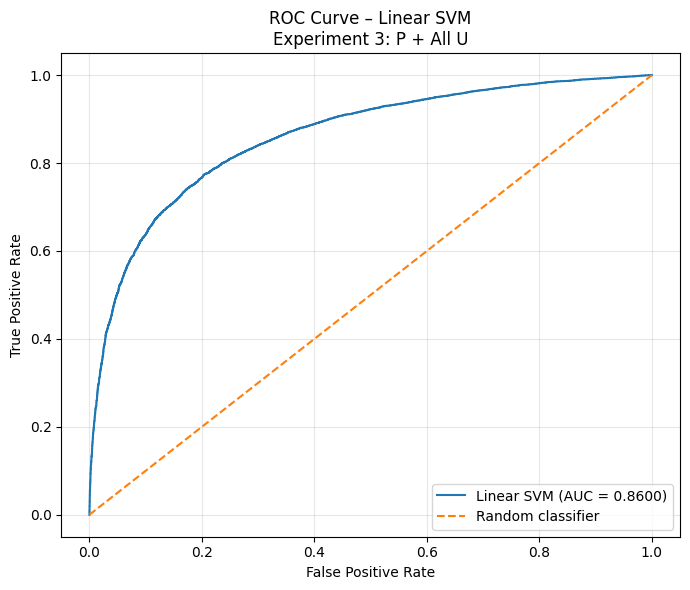


Prediction Distribution
-----------------------
Predicted Unlabelled: 10446
Predicted Positive: 9533
Total predictions: 19979

Stored Experiment 3 SVM Results
--------------------------------
  Experiment      Model  Positive  Unlabelled  Train_Size  Test_Size  Balanced_Accuracy  ROC_AUC  U_Recall  P_Recall
Experiment 3 Linear SVM     49947       49947       79915      19979           0.783271 0.860048  0.806106  0.760436

✓ Results saved:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step35_exp3_linear_svm_results.csv

Linear SVM Experiment Comparison
  Experiment      Model  Positive  Unlabelled  Train_Size  Test_Size  Balanced_Accuracy  ROC_AUC  U_Recall  P_Recall
Experiment 2 Linear SVM     49947       25000       59957      14990           0.755188 0.857494  0.633400  0.876977
Experiment 3 Linear SVM     49947       49947       79915      19979           0.783271 0.860048  0.806106  0.760436

Change After Increasing Unlabelled Data
---------------------------------------
Balanced A

In [11]:
# ============================================================
# Step 35
# Memory-Conscious Linear SVM Classification
# Experiment 3: Positive + All Unlabelled
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gc

from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

RANDOM_STATE = 42

TRAIN_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp3_train.parquet"
)

TEST_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step29_exp3_test.parquet"
)


# ------------------------------------------------------------
# Load Experiment 3 Only
# ------------------------------------------------------------

print("======================================")
print("Step 35")
print("Linear SVM – Experiment 3")
print("======================================")

print("\nLoading Experiment 3 train/test data...")


train_df = pd.read_parquet(
    TRAIN_FILE
)

test_df = pd.read_parquet(
    TEST_FILE
)


print("Training dataset:", train_df.shape)
print("Test dataset    :", test_df.shape)


# ------------------------------------------------------------
# Define Feature Columns
# ------------------------------------------------------------

descriptor_columns = [
    "MolWt",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "Rotatable_Bonds",
    "Ring_Count",
    "Aromatic_Ring_Count",
    "Heavy_Atom_Count",
    "Fraction_CSP3"
]


disease_feature_columns = [
    "Num_Targets",
    "Mean_Association_Score",
    "Max_Association_Score",
    "Total_Evidence"
]


fingerprint_columns = [
    column
    for column in train_df.columns
    if column.startswith("FP_")
]


fingerprint_columns = sorted(
    fingerprint_columns,
    key=lambda x: int(x.split("_")[1])
)


model_feature_columns = (
    descriptor_columns
    + fingerprint_columns
    + disease_feature_columns
)


print("\nFeature Configuration")
print("---------------------")

print(
    "Molecular descriptors:",
    len(descriptor_columns)
)

print(
    "Morgan fingerprints:",
    len(fingerprint_columns)
)

print(
    "Disease features:",
    len(disease_feature_columns)
)

print(
    "Total modelling features:",
    len(model_feature_columns)
)


if len(model_feature_columns) != 2062:

    raise ValueError(
        "Expected 2,062 modelling features."
    )


# ------------------------------------------------------------
# Prepare X/y Matrices
# ------------------------------------------------------------

print("\nPreparing feature matrices...")


X_train = (
    train_df[
        model_feature_columns
    ]
    .to_numpy(
        dtype=np.float32
    )
)


X_test = (
    test_df[
        model_feature_columns
    ]
    .to_numpy(
        dtype=np.float32
    )
)


y_train = (
    train_df["PU_Label"]
    .to_numpy(
        dtype=np.int8
    )
)


y_test = (
    test_df["PU_Label"]
    .to_numpy(
        dtype=np.int8
    )
)


print(
    "X_train:",
    X_train.shape
)

print(
    "X_test :",
    X_test.shape
)

print(
    "y_train:",
    y_train.shape
)

print(
    "y_test :",
    y_test.shape
)


# ------------------------------------------------------------
# Delete Source DataFrames Immediately
# ------------------------------------------------------------

del train_df
del test_df

gc.collect()


print(
    "✓ Source DataFrames released from memory."
)


# ------------------------------------------------------------
# Display PU Distribution
# ------------------------------------------------------------

print("\nTraining PU distribution:")


unique_train, counts_train = np.unique(
    y_train,
    return_counts=True
)


for label, count in zip(
    unique_train,
    counts_train
):

    status = (
        "Positive (P)"
        if label == 1
        else "Unlabelled (U)"
    )

    print(
        f"{status}: {count}"
    )


print("\nTest PU distribution:")


unique_test, counts_test = np.unique(
    y_test,
    return_counts=True
)


for label, count in zip(
    unique_test,
    counts_test
):

    status = (
        "Positive (P)"
        if label == 1
        else "Unlabelled (U)"
    )

    print(
        f"{status}: {count}"
    )


# ------------------------------------------------------------
# Feature Scaling
# ------------------------------------------------------------

print("\n======================================")
print("Feature Scaling")
print("======================================")


scaler_svm_exp3 = StandardScaler(
    with_mean=False,
    copy=False
)


print(
    "\nFitting scaler using training data..."
)


X_train = scaler_svm_exp3.fit_transform(
    X_train
)


X_test = scaler_svm_exp3.transform(
    X_test
)


print(
    "✓ Feature scaling completed."
)


print(
    "X_train dtype:",
    X_train.dtype
)

print(
    "X_test dtype :",
    X_test.dtype
)


# ------------------------------------------------------------
# Linear SVM
# ------------------------------------------------------------

print("\n======================================")
print("Linear SVM")
print("======================================")


svm_exp3 = LinearSVC(
    C=1.0,
    random_state=RANDOM_STATE,
    max_iter=5000,
    dual="auto"
)


print(
    "\nTraining Linear SVM..."
)


svm_exp3.fit(
    X_train,
    y_train
)


print(
    "✓ Linear SVM training completed."
)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

print(
    "\nGenerating predictions..."
)


y_pred_svm_exp3 = svm_exp3.predict(
    X_test
)


y_score_svm_exp3 = svm_exp3.decision_function(
    X_test
)


print(
    "✓ Predictions generated."
)


# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\n======================================")
print("Classification Report")
print("======================================")


print(
    classification_report(
        y_test,
        y_pred_svm_exp3,
        labels=[0, 1],
        target_names=[
            "Unlabelled (U)",
            "Positive (P)"
        ],
        digits=4
    )
)


# ------------------------------------------------------------
# Performance Metrics
# ------------------------------------------------------------

balanced_accuracy_svm_exp3 = (
    balanced_accuracy_score(
        y_test,
        y_pred_svm_exp3
    )
)


roc_auc_svm_exp3 = (
    roc_auc_score(
        y_test,
        y_score_svm_exp3
    )
)


print("\n======================================")
print("Linear SVM Performance")
print("======================================")


print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_svm_exp3,
        4
    )
)


print(
    "ROC-AUC:",
    round(
        roc_auc_svm_exp3,
        4
    )
)


# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

cm_svm_exp3 = confusion_matrix(
    y_test,
    y_pred_svm_exp3,
    labels=[0, 1]
)


print("\nConfusion Matrix")
print("----------------")

print(
    cm_svm_exp3
)


print(
    "\nRows = observed PU label"
)

print(
    "Columns = predicted PU label"
)

print(
    "0 = Unlabelled (U), 1 = Positive (P)"
)


# ------------------------------------------------------------
# Class-Specific Recall
# ------------------------------------------------------------

u_recall_svm_exp3 = (
    cm_svm_exp3[0, 0]
    / cm_svm_exp3[0].sum()
)


p_recall_svm_exp3 = (
    cm_svm_exp3[1, 1]
    / cm_svm_exp3[1].sum()
)


print("\nClass-Specific Recall")
print("---------------------")


print(
    "Unlabelled Recall:",
    round(
        u_recall_svm_exp3,
        4
    )
)


print(
    "Positive Recall:",
    round(
        p_recall_svm_exp3,
        4
    )
)


# ------------------------------------------------------------
# Plot Confusion Matrix
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(6, 5)
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm_exp3,
    display_labels=[
        "Unlabelled (U)",
        "Positive (P)"
    ]
)


disp.plot(
    ax=ax,
    values_format="d"
)


plt.title(
    "Linear SVM Confusion Matrix\n"
    "Experiment 3: P + All U"
)


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# ROC Curve
# ------------------------------------------------------------

fpr_svm_exp3, tpr_svm_exp3, _ = (
    roc_curve(
        y_test,
        y_score_svm_exp3
    )
)


plt.figure(
    figsize=(7, 6)
)


plt.plot(
    fpr_svm_exp3,
    tpr_svm_exp3,
    label=(
        "Linear SVM "
        f"(AUC = {roc_auc_svm_exp3:.4f})"
    )
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)


plt.xlabel(
    "False Positive Rate"
)


plt.ylabel(
    "True Positive Rate"
)


plt.title(
    "ROC Curve – Linear SVM\n"
    "Experiment 3: P + All U"
)


plt.legend(
    loc="lower right"
)


plt.grid(
    alpha=0.3
)


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Prediction Distribution
# ------------------------------------------------------------

predicted_u_svm_exp3 = int(
    (y_pred_svm_exp3 == 0).sum()
)


predicted_p_svm_exp3 = int(
    (y_pred_svm_exp3 == 1).sum()
)


print("\nPrediction Distribution")
print("-----------------------")


print(
    "Predicted Unlabelled:",
    predicted_u_svm_exp3
)


print(
    "Predicted Positive:",
    predicted_p_svm_exp3
)


print(
    "Total predictions:",
    len(y_pred_svm_exp3)
)


# ------------------------------------------------------------
# Store Experiment 3 Results
# ------------------------------------------------------------

results_exp3_svm = {
    "Experiment": "Experiment 3",
    "Model": "Linear SVM",
    "Positive": 49947,
    "Unlabelled": 49947,
    "Train_Size": len(y_train),
    "Test_Size": len(y_test),
    "Balanced_Accuracy": (
        balanced_accuracy_svm_exp3
    ),
    "ROC_AUC": (
        roc_auc_svm_exp3
    ),
    "U_Recall": (
        u_recall_svm_exp3
    ),
    "P_Recall": (
        p_recall_svm_exp3
    )
}


results_exp3_svm_df = pd.DataFrame(
    [results_exp3_svm]
)


print("\nStored Experiment 3 SVM Results")
print("--------------------------------")


print(
    results_exp3_svm_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Save Results to Disk
# ------------------------------------------------------------

SVM_RESULTS_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step35_exp3_linear_svm_results.csv"
)


results_exp3_svm_df.to_csv(
    SVM_RESULTS_FILE,
    index=False
)


print(
    "\n✓ Results saved:"
)

print(
    SVM_RESULTS_FILE
)


# ------------------------------------------------------------
# Compare with Experiment 2
# ------------------------------------------------------------
# Read the small Step 34 result file rather than depending
# on variables from an earlier notebook session.
# ------------------------------------------------------------

EXP2_RESULTS_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step34_exp2_linear_svm_results.csv"
)


exp2_svm_results = pd.read_csv(
    EXP2_RESULTS_FILE
)


svm_comparison_df = pd.concat(
    [
        exp2_svm_results,
        results_exp3_svm_df
    ],
    ignore_index=True
)


print("\n======================================")
print("Linear SVM Experiment Comparison")
print("======================================")


print(
    svm_comparison_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Changes After Increasing U
# ------------------------------------------------------------

exp2_balanced_accuracy = float(
    exp2_svm_results.loc[
        0,
        "Balanced_Accuracy"
    ]
)


exp2_roc_auc = float(
    exp2_svm_results.loc[
        0,
        "ROC_AUC"
    ]
)


exp2_u_recall = float(
    exp2_svm_results.loc[
        0,
        "U_Recall"
    ]
)


exp2_p_recall = float(
    exp2_svm_results.loc[
        0,
        "P_Recall"
    ]
)


print("\nChange After Increasing Unlabelled Data")
print("---------------------------------------")


print(
    "Balanced Accuracy change:",
    round(
        balanced_accuracy_svm_exp3
        - exp2_balanced_accuracy,
        4
    )
)


print(
    "ROC-AUC change:",
    round(
        roc_auc_svm_exp3
        - exp2_roc_auc,
        4
    )
)


print(
    "Unlabelled Recall change:",
    round(
        u_recall_svm_exp3
        - exp2_u_recall,
        4
    )
)


print(
    "Positive Recall change:",
    round(
        p_recall_svm_exp3
        - exp2_p_recall,
        4
    )
)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

print("\n======================================")
print("Step 35 Final Validation")
print("======================================")


if len(y_pred_svm_exp3) != len(y_test):

    raise ValueError(
        "Prediction/test size mismatch."
    )


if not (
    0 <= balanced_accuracy_svm_exp3 <= 1
):

    raise ValueError(
        "Invalid balanced accuracy."
    )


if not (
    0 <= roc_auc_svm_exp3 <= 1
):

    raise ValueError(
        "Invalid ROC-AUC."
    )


print(
    "✓ Prediction count matches test set."
)

print(
    "✓ Balanced accuracy calculated."
)

print(
    "✓ ROC-AUC calculated."
)

print(
    "✓ Class-specific recall calculated."
)

print(
    "✓ Experiment 3 Linear SVM completed."
)

print(
    "✓ Experiment 2 and Experiment 3 "
    "results compared."
)


print(
    "\n✓ PU_Label = 0 remains UNLABELLED "
    "rather than a confirmed biological negative."
)


# ------------------------------------------------------------
# Important Interpretation
# ------------------------------------------------------------

print("\nImportant Interpretation")
print("------------------------")


print(
    "The comparison evaluates how Linear SVM "
    "behaviour changes as the unlabelled pool increases."
)


print(
    "Performance measures describe discrimination "
    "between known positive and unlabelled observations."
)


print(
    "They do not represent evaluation against "
    "experimentally confirmed biological negatives."
)


# ------------------------------------------------------------
# MEMORY CLEANUP
# ------------------------------------------------------------

print("\n======================================")
print("Memory Cleanup")
print("======================================")


# All important numerical results have already been
# saved to CSV. Remove large objects before the next step.

del X_train
del X_test

del y_train
del y_test

del svm_exp3
del scaler_svm_exp3

del y_pred_svm_exp3
del y_score_svm_exp3


gc.collect()


print(
    "✓ Experiment 3 feature matrices deleted."
)

print(
    "✓ Linear SVM model deleted."
)

print(
    "✓ Scaler deleted."
)

print(
    "✓ Prediction arrays deleted."
)

print(
    "✓ Numerical results saved to disk."
)

print(
    "\n✓ Memory released successfully."
)

## Step 36 – Comparison of Random Forest and Linear SVM Across PU Experiments

This step compares the predictive behaviour of the Random Forest and Linear Support Vector Machine classifiers across the two Positive–Unlabelled experimental conditions.

The comparison includes:

- **Experiment 2:** 49,947 positive + 25,000 unlabelled observations
- **Experiment 3:** 49,947 positive + 49,947 unlabelled observations

Both classifiers were evaluated using the same train–test partitions established in Step 29.

The comparison focuses on:

- Balanced accuracy
- ROC-AUC
- Recall for the unlabelled class
- Recall for the known-positive class

### Random Forest

For Random Forest, increasing the unlabelled pool from 25,000 to 49,947 increased balanced accuracy from 0.8007 to 0.8226. ROC-AUC remained comparatively stable, changing from 0.9007 to 0.9024.

Unlabelled recall increased from 0.7034 to 0.8301, while positive recall decreased from 0.8980 to 0.8151.

### Linear SVM

For Linear SVM, increasing the unlabelled pool increased balanced accuracy from 0.7552 to 0.7833 and ROC-AUC from 0.8575 to 0.8600.

Unlabelled recall increased from 0.6334 to 0.8061, while positive recall decreased from 0.8770 to 0.7604.

### Comparative Objective

The purpose of this comparison is not only to compare the two classifiers, but also to determine whether the effect of progressively introducing additional unlabelled observations is consistent across different machine-learning algorithms.

The results indicate a common pattern in both classifiers: increasing the size of the unlabelled pool improves recognition of the observed unlabelled class and increases balanced accuracy, while reducing recall for known-positive observations. ROC-AUC remains relatively stable.

These results remain specific to the constructed Positive–Unlabelled experiments. The unlabelled observations are not experimentally confirmed negatives, and the reported metrics therefore quantify discrimination between known positive and unlabelled observations rather than conventional positive-versus-confirmed-negative classification.

RF and Linear SVM Comparison
  Experiment         Model  Unlabelled  Balanced_Accuracy  ROC_AUC  U_Recall  P_Recall
Experiment 2 Random Forest       25000           0.800699 0.900743  0.703400  0.897998
Experiment 3 Random Forest       49947           0.822613 0.902405  0.830130  0.815097
Experiment 2    Linear SVM       25000           0.755188 0.857494  0.633400  0.876977
Experiment 3    Linear SVM       49947           0.783271 0.860048  0.806106  0.760436

Experiment 2 Model Comparison
  Experiment         Model  Unlabelled  Balanced_Accuracy  ROC_AUC  U_Recall  P_Recall
Experiment 2 Random Forest       25000           0.800699 0.900743    0.7034  0.897998
Experiment 2    Linear SVM       25000           0.755188 0.857494    0.6334  0.876977

Experiment 3 Model Comparison
  Experiment         Model  Unlabelled  Balanced_Accuracy  ROC_AUC  U_Recall  P_Recall
Experiment 3 Random Forest       49947           0.822613 0.902405  0.830130  0.815097
Experiment 3    Linear SVM       49947 

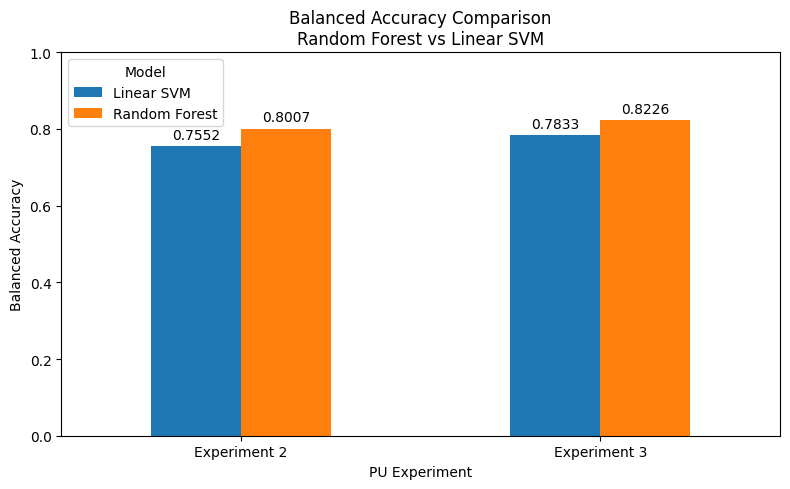

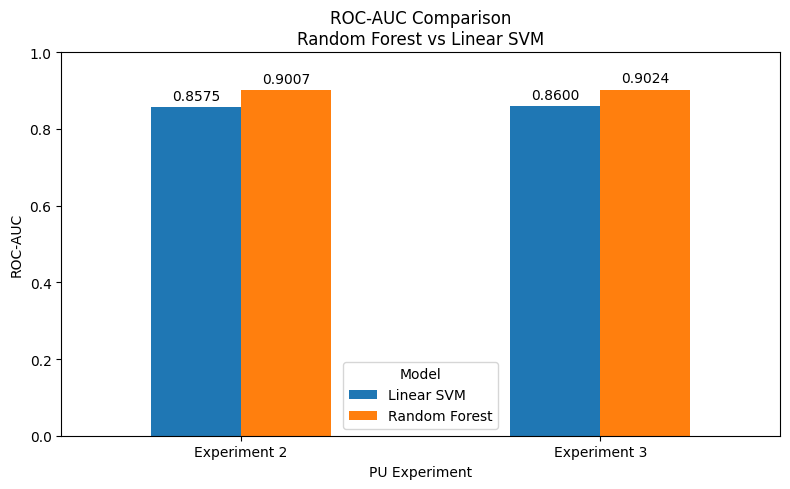

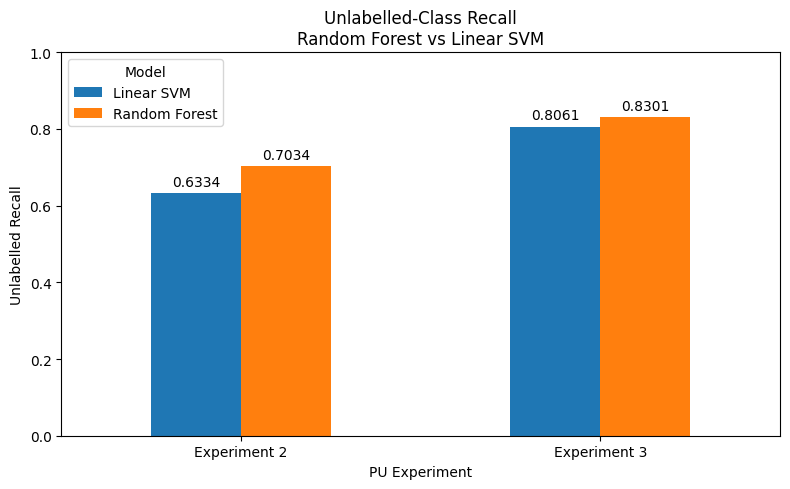

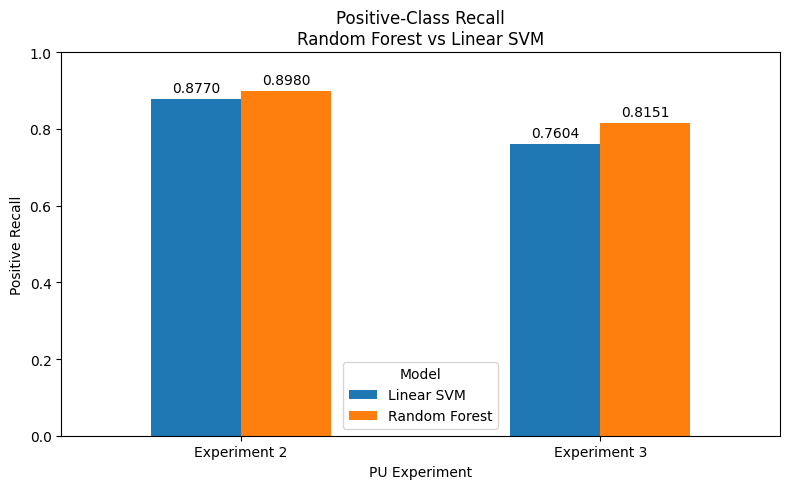


Output Files
/Users/sankhadeep/Desktop/DrugBank/drugbank_step36_rf_svm_comparison.csv
/Users/sankhadeep/Desktop/DrugBank/drugbank_step36_effect_of_unlabelled_data.csv

Step 36 Numerical Summary

Random Forest
---------
Experiment 2 Balanced Accuracy: 0.8007
Experiment 3 Balanced Accuracy: 0.8226
Experiment 2 ROC-AUC: 0.9007
Experiment 3 ROC-AUC: 0.9024

Linear SVM
---------
Experiment 2 Balanced Accuracy: 0.7552
Experiment 3 Balanced Accuracy: 0.7833
Experiment 2 ROC-AUC: 0.8575
Experiment 3 ROC-AUC: 0.86

Step 36 Interpretation
Both classifiers show increased balanced accuracy when the unlabelled pool is increased.
Both classifiers show substantially increased recall for the unlabelled class.
Both classifiers simultaneously show reduced recall for the known-positive class.
ROC-AUC changes only slightly when the unlabelled pool is increased.

These results indicate that increasing the unlabelled sample changes the balance of P/U discrimination across both classifiers.

PU_Label = 0 re

In [12]:
# ============================================================
# Step 36
# Comparison of Random Forest and Linear SVM
# Across PU Experiments
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Random Forest Results
# From Steps 31–33
# ------------------------------------------------------------

rf_results = pd.DataFrame(
    {
        "Experiment": [
            "Experiment 2",
            "Experiment 3"
        ],

        "Model": [
            "Random Forest",
            "Random Forest"
        ],

        "Unlabelled": [
            25000,
            49947
        ],

        "Balanced_Accuracy": [
            0.800699,
            0.822613
        ],

        "ROC_AUC": [
            0.900743,
            0.902405
        ],

        "U_Recall": [
            0.7034,
            0.830130
        ],

        "P_Recall": [
            0.897998,
            0.815097
        ]
    }
)


# ------------------------------------------------------------
# Read Saved Linear SVM Results
# ------------------------------------------------------------

EXP2_SVM_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step34_exp2_linear_svm_results.csv"
)

EXP3_SVM_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step35_exp3_linear_svm_results.csv"
)


svm_exp2_results = pd.read_csv(
    EXP2_SVM_FILE
)

svm_exp3_results = pd.read_csv(
    EXP3_SVM_FILE
)


svm_results = pd.concat(
    [
        svm_exp2_results,
        svm_exp3_results
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Select Common Columns
# ------------------------------------------------------------

comparison_columns = [
    "Experiment",
    "Model",
    "Unlabelled",
    "Balanced_Accuracy",
    "ROC_AUC",
    "U_Recall",
    "P_Recall"
]


svm_results = svm_results[
    comparison_columns
]


rf_results = rf_results[
    comparison_columns
]


# ------------------------------------------------------------
# Combine Model Results
# ------------------------------------------------------------

model_comparison_df = pd.concat(
    [
        rf_results,
        svm_results
    ],
    ignore_index=True
)


print("======================================")
print("RF and Linear SVM Comparison")
print("======================================")


print(
    model_comparison_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Comparison by Experiment
# ------------------------------------------------------------

print("\n======================================")
print("Experiment 2 Model Comparison")
print("======================================")


experiment_2_comparison = (
    model_comparison_df[
        model_comparison_df["Experiment"]
        == "Experiment 2"
    ]
)


print(
    experiment_2_comparison.to_string(
        index=False
    )
)


print("\n======================================")
print("Experiment 3 Model Comparison")
print("======================================")


experiment_3_comparison = (
    model_comparison_df[
        model_comparison_df["Experiment"]
        == "Experiment 3"
    ]
)


print(
    experiment_3_comparison.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Calculate Effect of Increasing U for Each Model
# ------------------------------------------------------------

change_records = []


for model in [
    "Random Forest",
    "Linear SVM"
]:

    model_data = (
        model_comparison_df[
            model_comparison_df["Model"] == model
        ]
        .set_index("Experiment")
    )


    change_records.append(
        {
            "Model": model,

            "Balanced_Accuracy_Change":
                model_data.loc[
                    "Experiment 3",
                    "Balanced_Accuracy"
                ]
                -
                model_data.loc[
                    "Experiment 2",
                    "Balanced_Accuracy"
                ],

            "ROC_AUC_Change":
                model_data.loc[
                    "Experiment 3",
                    "ROC_AUC"
                ]
                -
                model_data.loc[
                    "Experiment 2",
                    "ROC_AUC"
                ],

            "U_Recall_Change":
                model_data.loc[
                    "Experiment 3",
                    "U_Recall"
                ]
                -
                model_data.loc[
                    "Experiment 2",
                    "U_Recall"
                ],

            "P_Recall_Change":
                model_data.loc[
                    "Experiment 3",
                    "P_Recall"
                ]
                -
                model_data.loc[
                    "Experiment 2",
                    "P_Recall"
                ]
        }
    )


model_change_df = pd.DataFrame(
    change_records
)


print("\n======================================")
print("Effect of Increasing Unlabelled Data")
print("======================================")


print(
    model_change_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# Balanced Accuracy Comparison
# ------------------------------------------------------------

pivot_balanced = (
    model_comparison_df.pivot(
        index="Experiment",
        columns="Model",
        values="Balanced_Accuracy"
    )
)


ax = pivot_balanced.plot(
    kind="bar",
    figsize=(8, 5)
)


plt.ylabel(
    "Balanced Accuracy"
)

plt.xlabel(
    "PU Experiment"
)

plt.title(
    "Balanced Accuracy Comparison\n"
    "Random Forest vs Linear SVM"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=0
)


for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.4f",
        padding=3
    )


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# ROC-AUC Comparison
# ------------------------------------------------------------

pivot_auc = (
    model_comparison_df.pivot(
        index="Experiment",
        columns="Model",
        values="ROC_AUC"
    )
)


ax = pivot_auc.plot(
    kind="bar",
    figsize=(8, 5)
)


plt.ylabel(
    "ROC-AUC"
)

plt.xlabel(
    "PU Experiment"
)

plt.title(
    "ROC-AUC Comparison\n"
    "Random Forest vs Linear SVM"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=0
)


for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.4f",
        padding=3
    )


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# U Recall Comparison
# ------------------------------------------------------------

pivot_u_recall = (
    model_comparison_df.pivot(
        index="Experiment",
        columns="Model",
        values="U_Recall"
    )
)


ax = pivot_u_recall.plot(
    kind="bar",
    figsize=(8, 5)
)


plt.ylabel(
    "Unlabelled Recall"
)

plt.xlabel(
    "PU Experiment"
)

plt.title(
    "Unlabelled-Class Recall\n"
    "Random Forest vs Linear SVM"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=0
)


for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.4f",
        padding=3
    )


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# P Recall Comparison
# ------------------------------------------------------------

pivot_p_recall = (
    model_comparison_df.pivot(
        index="Experiment",
        columns="Model",
        values="P_Recall"
    )
)


ax = pivot_p_recall.plot(
    kind="bar",
    figsize=(8, 5)
)


plt.ylabel(
    "Positive Recall"
)

plt.xlabel(
    "PU Experiment"
)

plt.title(
    "Positive-Class Recall\n"
    "Random Forest vs Linear SVM"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=0
)


for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.4f",
        padding=3
    )


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Save Combined Comparison
# ------------------------------------------------------------

COMPARISON_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step36_rf_svm_comparison.csv"
)


model_comparison_df.to_csv(
    COMPARISON_FILE,
    index=False
)


CHANGE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step36_effect_of_unlabelled_data.csv"
)


model_change_df.to_csv(
    CHANGE_FILE,
    index=False
)


print("\n======================================")
print("Output Files")
print("======================================")


print(
    COMPARISON_FILE
)

print(
    CHANGE_FILE
)


# ------------------------------------------------------------
# Final Numerical Summary
# ------------------------------------------------------------

print("\n======================================")
print("Step 36 Numerical Summary")
print("======================================")


for model in [
    "Random Forest",
    "Linear SVM"
]:

    model_data = (
        model_comparison_df[
            model_comparison_df["Model"] == model
        ]
        .set_index("Experiment")
    )


    print(
        f"\n{model}"
    )

    print(
        "---------"
    )


    print(
        "Experiment 2 Balanced Accuracy:",
        round(
            model_data.loc[
                "Experiment 2",
                "Balanced_Accuracy"
            ],
            4
        )
    )


    print(
        "Experiment 3 Balanced Accuracy:",
        round(
            model_data.loc[
                "Experiment 3",
                "Balanced_Accuracy"
            ],
            4
        )
    )


    print(
        "Experiment 2 ROC-AUC:",
        round(
            model_data.loc[
                "Experiment 2",
                "ROC_AUC"
            ],
            4
        )
    )


    print(
        "Experiment 3 ROC-AUC:",
        round(
            model_data.loc[
                "Experiment 3",
                "ROC_AUC"
            ],
            4
        )
    )


# ------------------------------------------------------------
# Final Interpretation
# ------------------------------------------------------------

print("\n======================================")
print("Step 36 Interpretation")
print("======================================")


print(
    "Both classifiers show increased balanced "
    "accuracy when the unlabelled pool is increased."
)


print(
    "Both classifiers show substantially increased "
    "recall for the unlabelled class."
)


print(
    "Both classifiers simultaneously show reduced "
    "recall for the known-positive class."
)


print(
    "ROC-AUC changes only slightly when the "
    "unlabelled pool is increased."
)


print(
    "\nThese results indicate that increasing the "
    "unlabelled sample changes the balance of "
    "P/U discrimination across both classifiers."
)


print(
    "\nPU_Label = 0 represents UNLABELLED observations "
    "rather than confirmed biological negatives."
)


print(
    "\n✓ Step 36 completed without loading the "
    "large molecular feature matrices."
)